In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('sensor_log.csv')

In [3]:
df.info

<bound method DataFrame.info of             id          recorded_at     tanggal     waktu  temp   hum  \
0         1970  2026-07-23 07:57:07  23/07/2026  14:57:25   0.0   0.0   
1         1971  2026-07-23 07:58:08  23/07/2026  14:58:26  36.3  34.0   
2         1972  2026-07-23 07:59:09  23/07/2026  14:59:27  36.9  34.0   
3         1973  2026-07-23 08:00:10  23/07/2026  15:00:28  36.9  34.0   
4         1974  2026-07-23 08:01:11  23/07/2026  15:01:30  36.9  34.0   
...        ...                  ...         ...       ...   ...   ...   
118567  120537  2026-10-26 04:00:52  26/10/2026  09:13:29  28.5  62.0   
118568  120538  2026-10-26 04:00:52  26/10/2026  09:14:30  28.5  62.0   
118569  120539  2026-10-26 04:00:52  26/10/2026  09:15:32  28.5  62.0   
118570  120540  2026-10-26 04:00:52  26/10/2026  09:16:33  28.5  61.0   
118571  120541  2026-10-26 04:00:52  26/10/2026  09:17:34  28.0  59.0   

            lux   tds  soil1  soil2  relay1  relay2  calibration_id  
0          0.00   0.0

In [4]:
def clean_data(df):
    # Convert 'tanggal' to datetime, handle errors
    df['tanggal'] = pd.to_datetime(df['tanggal'], errors='coerce', dayfirst=True)
    # Convert 'waktu' column to datetime with mixed format
    df['waktu'] = pd.to_datetime(df['waktu'], errors='coerce')
    # Drop column: 'recorded_at' karena sudah diwakili oleh kolom 'waktu' yang lebih lengkap
    df = df.drop(columns=['recorded_at'])
    # Drop column: 'tanggal' untuk mempermudah analisis karena sudah ada kolom 'waktu' yang lebih lengkap
    df = df.drop(columns=['tanggal'])
    # Remove rows with temp or hum as 0.0 karena itu menandakan sensor error atau tidak ada data ataupun sensor mati
    df = df[(df['temp'] != 0.0) & (df['hum'] != 0.0)]
    # Drop column: 'calibration_id' ini hanya berisi id kalibrasi otomasi aja jadi gak ngaruh ke data
    df = df.drop(columns=['calibration_id'])
    # Drop column: 'relay1' ini hanya berisi status relay aja jadi gak ngaruh ke data
    df = df.drop(columns=['relay1'])
    # Drop column: 'relay2' ini hanya berisi status relay aja jadi gak ngaruh ke data
    df = df.drop(columns=['relay2'])
    # Drop column: 'id' ini hanya berisi id sensor aja jadi gak ngaruh ke data
    df = df.drop(columns=['id'])
    # Drop rows with missing data in column: 'waktu'
    df = df.dropna(subset=['waktu'])
    return df

In [5]:
df_clean = clean_data(df.copy())
df_clean.head()

/tmp/ipykernel_186700/4131573296.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['waktu'] = pd.to_datetime(df['waktu'], errors='coerce')


,waktu,temp,hum,lux,tds,soil1,soil2
1,2026-11-06 14:58:26,36.3,34.0,2828.33,3.0,727,716
2,2026-11-06 14:59:27,36.9,34.0,2790.00,8.0,710,719
3,2026-11-06 15:00:28,36.9,34.0,2845.00,12.0,721,718
4,2026-11-06 15:01:30,36.9,34.0,2903.33,6.0,706,709
5,2026-11-06 15:02:31,36.9,33.0,2860.00,14.0,731,710


# Analisis Data Sensor Lingkungan

Notebook ini melanjutkan `df_clean` dari cell di atas, mengikuti alur *Big Data Analytics* pada materi kuliah: cleansing, agregasi, sampling dan ekstraksi fitur, partisi data, pembuatan model, validasi, lalu penilaian nilai data.

## 1. Peta isi

| Bagian | Isi | Materi terkait |
|---|---|---|
| 2 | Memulihkan tanggal | Data cleansing |
| 3 | Tipe atribut | Data format, jenis atribut |
| 4 | Audit `soil1`, `soil2`, `tds`, dan relay | Veracity, kualitas data |
| 5 | Agregasi 5 menit dan data cube | Dimension aggregation |
| 6 | Korelasi, VPD, pola panas | Tren, pola, korelasi |
| 7 | Partisi data dan scaling | Data partition, feature scaling |
| 8 | Model A `SensorFill`: input sebagian, prediksi sisanya, dan missing value | Model creation, missing value |
| 9 | Model B: prediksi ke depan | Predictive modeling |
| 10 | Model C: alarm panas dan accuracy | Model validation |
| 11-12 | Simulasi sensor rusak dan satu hari operasi | Penggunaan model |
| 13 | 5V, nilai ekonomi, nilai per industri | Value |
| 14-17 | Penyimpanan model, kesimpulan, sumber | Report |
| 18-19 | Daftar istilah, alur penjelasan, dan pertanyaan yang mungkin muncul | Report |
| 20-22 | Analisis lanjutan di luar materi, kesimpulannya, dan saran | Di luar materi |

Kolom yang dipakai untuk model: `temp`, `hum`, `lux`. Kolom `soil1`, `soil2`, dan `tds` diaudit di bagian 4, lalu dihapus.

In [6]:
import json, time, warnings
from pathlib import Path

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, precision_recall_curve, precision_score,
                             r2_score, recall_score, roc_auc_score)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
pd.set_option('display.max_columns', 50, 'display.width', 200)

# Satu warna tetap per sensor di semua grafik
WARNA = {'temp': '#2a78d6', 'hum': '#eb6834', 'lux': '#1baf7a', 'log_lux': '#1baf7a'}
TINTA, TINTA2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
BIRU_SEQ = LinearSegmentedColormap.from_list('biru', ['#cde2fb', '#6da7ec', '#2a78d6', '#184f95', '#0d366b'])
ORANYE_SEQ = LinearSegmentedColormap.from_list('oranye', ['#fbe3d8', '#f4a988', '#eb6834', '#b8481c', '#7a2e10'])
DIVERGEN = LinearSegmentedColormap.from_list('div', ['#184f95', '#6da7ec', '#f0efec', '#ec8f8e', '#b32e2d'])
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 130, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.edgecolor': GRID, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': .6, 'axes.spines.top': False, 'axes.spines.right': False, 'xtick.color': TINTA2,
                     'ytick.color': TINTA2, 'legend.frameon': False, 'font.size': 9.5, 'lines.linewidth': 1.4})

def metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {'MAE': mean_absolute_error(y, p), 'RMSE': float(np.sqrt(np.mean((y - p) ** 2))), 'R2': r2_score(y, p)}

## 2. Melanjutkan `df_clean`: memulihkan tanggal

Sebelum analisis, ada satu hal di hasil pembersihan yang harus diperbaiki. Kolom `waktu` di CSV hanya berisi jam (`14:58:26`). Saat diubah dengan `pd.to_datetime`, pandas mengisi bagian tanggal dengan **tanggal hari notebook dijalankan**, lalu kolom `tanggal` yang asli dihapus. Cell di bawah membuktikannya.

Cell pembersihan di atas tidak diubah. Karena `df_clean` masih menyimpan index baris asli, tanggal bisa diambil kembali dari `df`.

In [7]:
print('Jumlah tanggal unik di df_clean.waktu :', df_clean['waktu'].dt.date.nunique(), '->', df_clean['waktu'].dt.date.iloc[0])
print('Timestamp yang duplikat               :', f"{df_clean['waktu'].duplicated().sum():,}", 'dari', f'{len(df_clean):,} baris')

asal = df.loc[df_clean.index]
ts_rtc = pd.to_datetime(asal['tanggal'] + ' ' + asal['waktu'], format='%d/%m/%Y %H:%M:%S', errors='coerce')
ts_server = pd.to_datetime(asal['recorded_at'])
selisih_jam = (ts_server - ts_rtc).dt.total_seconds() / 3600

print('\nSelisih recorded_at - (tanggal+waktu), dibulatkan ke jam:')
print(selisih_jam.round().value_counts().head(8).to_string())

# recorded_at normalnya 7 jam di belakang jam perangkat. Jika selisih positif, jam perangkat tertinggal
# jauh dari server (RTC ter-reset), sehingga baris itu memakai recorded_at + 7 jam.
rtc_salah = selisih_jam > 0
ts_benar = ts_rtc.where(~rtc_salah, ts_server + pd.Timedelta(hours=7))
print(f'\nBaris dengan jam perangkat ter-reset: {rtc_salah.sum()} ({rtc_salah.mean():.3%})')
print('Tanggal jam perangkat pada baris tsb:', sorted(ts_rtc[rtc_salah].dt.date.astype(str).unique()))

data = (df_clean.drop(columns='waktu').assign(timestamp=ts_benar).dropna(subset=['timestamp'])
        .sort_values('timestamp').set_index('timestamp'))
n_dup = data.index.duplicated().sum()
data = data[~data.index.duplicated()]
print(f'\nHasil: {len(data):,} baris | {data.index.min()} s.d. {data.index.max()} | {data.index.normalize().nunique()} hari | duplikat dibuang: {n_dup}')
data.head()

Jumlah tanggal unik di df_clean.waktu : 1 -> 2026-11-06
Timestamp yang duplikat               : 51,560 dari 117,044 baris

Selisih recorded_at - (tanggal+waktu), dibulatkan ke jam:
-7.0      111395
-8.0        5515
-5.0          57
 441.0        28
 18.0         26
-4.0          10
 440.0         6
 44.0          4

Baris dengan jam perangkat ter-reset: 64 (0.055%)
Tanggal jam perangkat pada baris tsb: ['2026-07-15', '2026-08-03']

Hasil: 117,043 baris | 2026-07-23 14:58:26 s.d. 2026-10-26 09:17:34 | 88 hari | duplikat dibuang: 1


,temp,hum,lux,tds,soil1,soil2
timestamp,,,,,,
2026-07-23 14:58:26,36.3,34.0,2828.33,3.0,727,716
2026-07-23 14:59:27,36.9,34.0,2790.00,8.0,710,719
2026-07-23 15:00:28,36.9,34.0,2845.00,12.0,721,718
2026-07-23 15:01:30,36.9,34.0,2903.33,6.0,706,709
2026-07-23 15:02:31,36.9,33.0,2860.00,14.0,731,710


**Hasil.** Semua baris `df_clean` memiliki tanggal yang sama, yaitu tanggal saat notebook dijalankan, dan 51.560 timestamp menjadi kembar. Tanpa perbaikan ini, urutan hari, jeda waktu, dan prediksi ke depan tidak mungkin dihitung.

- 64 baris mencatat jam perangkat yang salah (15 Juli dan 3 Agustus), padahal data server menunjukkan waktu sesudahnya. Pola ini cocok dengan jam RTC yang ter-reset. Baris ini diperbaiki dengan `recorded_at + 7 jam`.
- Baris rusak bertanggal `74/67/2022` sudah terbuang oleh `dropna` di `clean_data`.
- 5.515 baris memiliki selisih sekitar 7,6 jam, bukan 7 jam. Baris ini dibiarkan, karena jam perangkat tetap menjadi acuan dan efeknya kecil untuk data 5 menitan.

## 3. Tipe atribut (materi *Data Format*)

Dataset ini adalah **structured data**: skemanya tetap, satu baris satu observasi, dan bisa langsung disimpan di tabel relasional.

| Atribut | Jenis | Skala | Rata-rata yang tepat | Catatan |
|---|---|---|---|---|
| `id` | Kategorikal | Nominal | Modus | Hanya penanda baris |
| `calibration_id` | Kategorikal | Nominal | Modus | Angkanya hanya label versi kalibrasi |
| `relay1`, `relay2` | Kategorikal | Biner | Modus | Status nyala/mati |
| `recorded_at`, `tanggal`, `waktu` | Numerik | Interval | Mean | Waktu tidak punya nol mutlak |
| `temp` (°C) | Numerik kontinu | Interval | Mean | Nol °C bukan berarti tidak ada panas |
| `hum` (%RH) | Numerik kontinu | Rasio | Mean | Tercatat sebagai bilangan bulat |
| `lux` | Numerik kontinu | Rasio | Mean, median | Sangat miring, jadi diberi transformasi log |
| `tds` | Numerik | Rasio | Median | Satuan dan kalibrasinya belum diketahui |
| `soil1`, `soil2` | Numerik diskret | Mendekati ordinal | Median | Nilai ADC mentah, belum ada satuan kelembapan |

## 4. Audit kolom bermasalah: `soil1`, `soil2`, `tds`

Di lapangan, `soil1`, `soil2`, dan `tds` dicurigai bermasalah karena perkabelan. Sebelum dihapus, dugaan itu diuji dengan data:

- **Rasio sinyal/noise**: tinggi siklus harian dibagi noise antar-menit.
- **Autokorelasi 1 menit**: besaran fisik yang sehat berubah pelan, sehingga nilainya mendekati 1.
- **Pembacaan janggal**: nilai ≤ 1 pada ADC tanah berarti sinyal hilang.
- **Kesepakatan dua probe** dan **kestabilan hubungan** dengan suhu dari bulan ke bulan.

In [8]:
def audit(x):
    noise = x.diff().std() / np.sqrt(2)
    harian = x.groupby(x.index.hour).mean()
    amplitudo = harian.max() - harian.min()
    median_harian = x.resample('1D').median().dropna()
    return {'noise_1mnt': noise, 'amplitudo_harian': amplitudo, 'rasio_sinyal_noise': amplitudo / noise,
            'autokorelasi_1mnt': x.autocorr(1), 'persen_nol': (x == 0).mean() * 100,
            'lompatan_median_harian_maks': median_harian.diff().abs().max()}

tabel_audit = pd.DataFrame({c: audit(data[c]) for c in ['temp', 'hum', 'soil1', 'soil2', 'tds']}).T
tabel_audit['pembacaan_<=1'] = [np.nan, np.nan, (data.soil1 <= 1).sum(), (data.soil2 <= 1).sum(), np.nan]
display(tabel_audit.round(2))

jam = data[['temp', 'hum', 'soil1', 'soil2']].resample('1h').median().dropna()
bulan = jam.index.to_period('M')
konsistensi = pd.DataFrame({
    'korelasi soil1-soil2': jam.groupby(bulan).apply(lambda b: b.soil1.corr(b.soil2)),
    'korelasi soil1-temp': jam.groupby(bulan).apply(lambda b: b.soil1.corr(b.temp)),
    'korelasi soil2-temp': jam.groupby(bulan).apply(lambda b: b.soil2.corr(b.temp))})
display(konsistensi.round(2))

fase = pd.cut(data.index, [pd.Timestamp(t) for t in ('2026-07-01', '2026-08-03 15:26', '2026-08-16', '2026-11-01')],
              labels=['s.d. 3 Agu (kalibrasi 2)', '3-16 Agu', '16 Agu ke atas'])
display(data.groupby(fase, observed=True)['tds'].agg(median='median', rata2='mean', persen_nol=lambda s: (s == 0).mean() * 100).round(2))

,noise_1mnt,amplitudo_harian,rasio_sinyal_noise,autokorelasi_1mnt,persen_nol,lompatan_median_harian_maks,pembacaan_<=1
temp,0.17,14.81,84.74,1.00,0.0,9.6,NaN
hum,0.40,35.85,90.22,1.00,0.0,25.0,NaN
soil1,10.46,14.18,1.36,0.97,0.0,85.0,5.0
soil2,11.02,15.21,1.38,0.97,0.0,234.0,3.0
tds,5.16,2.18,0.42,0.32,50.7,12.0,NaN


,korelasi soil1-soil2,korelasi soil1-temp,korelasi soil2-temp
timestamp,,,
2026-07,0.32,0.35,0.08
2026-08,0.03,0.13,0.32
2026-09,0.50,-0.28,-0.02
2026-10,0.70,0.14,-0.09


,median,rata2,persen_nol
s.d. 3 Agu (kalibrasi 2),12.0,10.86,16.24
3-16 Agu,0.0,1.22,78.63
16 Agu ke atas,0.0,4.26,51.20


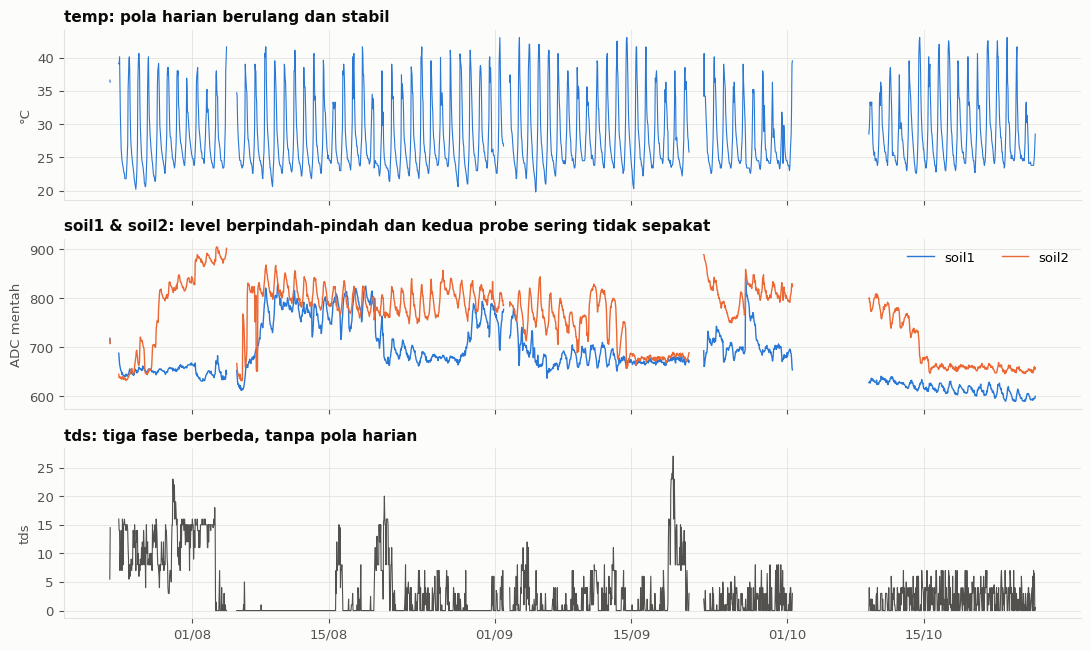

In [9]:
h = data[['temp', 'soil1', 'soil2', 'tds']].resample('1h').median()
fig, ax = plt.subplots(3, 1, figsize=(11, 6.6), sharex=True)
ax[0].plot(h.index, h.temp, color=WARNA['temp'], lw=.8)
ax[0].set_title('temp: pola harian berulang dan stabil'); ax[0].set_ylabel('°C')
ax[1].plot(h.index, h.soil1, color='#2a78d6', lw=1, label='soil1')
ax[1].plot(h.index, h.soil2, color='#eb6834', lw=1, label='soil2')
ax[1].set_title('soil1 & soil2: level berpindah-pindah dan kedua probe sering tidak sepakat'); ax[1].set_ylabel('ADC mentah'); ax[1].legend(loc='upper right', ncol=2)
ax[2].plot(h.index, h.tds, color=TINTA2, lw=.8)
ax[2].set_title('tds: tiga fase berbeda, tanpa pola harian'); ax[2].set_ylabel('tds')
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
fig.tight_layout(); plt.show()

**Hasil audit: dugaan lapangan didukung data.**

| Pemeriksaan | `temp` / `hum` (pembanding sehat) | `soil1` / `soil2` | `tds` |
|---|---|---|---|
| Rasio sinyal/noise | 84,7 / 90,2 | 1,36 / 1,38 | 0,42 |
| Autokorelasi 1 menit | 1,00 | 0,97 | 0,32 |
| Pembacaan nol | 0% setelah cleaning | 0% | 50,7% |
| Lompatan median harian terbesar | 9,6 °C / 25 %RH | 85 / 234 ADC | 12 |

- **`soil1` dan `soil2`:** noise hampir sama besar dengan pola harian, dan ada 8 pembacaan bernilai 1 yang menandakan sinyal hilang. Korelasi kedua probe berubah dari 0,03 sampai 0,70 per bulan, dan hubungannya dengan suhu berganti tanda. Data seperti ini tidak punya hubungan stabil yang bisa dipelajari model.
- **`tds`:** separuh data bernilai nol, noise lebih besar dari pola harian, dan levelnya berubah dalam tiga fase (median 12, lalu 0).

**Keputusan: ketiganya dibuang dari model.** Data ini menunjukkan sinyalnya tidak andal, tetapi tidak dapat membuktikan bahwa kabel adalah penyebabnya. `soil` juga tidak sepenuhnya kosong: pada 23-24 Juli nilainya turun saat kedua relay menyala. Itu baru satu kejadian, tetapi cukup menjadi alasan untuk memperbaiki sensor ini dan mengukur ulang, bukan meninggalkannya.

### Temuan tambahan: sensor suhu-kelembapan mati saat relay menyala

`relay1`, `relay2`, dan `calibration_id` memang dihapus dari `df_clean`, tetapi `df` mentah masih menyimpannya. Tabel berikut menguji hubungan relay dengan pembacaan nol.

In [10]:
relay_nyala = ((df.relay1 == 1) | (df.relay2 == 1)).rename('relay_nyala')
sensor_nol = ((df.temp == 0) & (df.hum == 0)).rename('temp_hum_nol')
display(pd.crosstab(relay_nyala, sensor_nol, margins=True))
print(f'P(temp & hum = 0 | relay nyala) = {sensor_nol[relay_nyala].mean():.1%}')
print(f'P(temp & hum = 0 | relay mati)  = {sensor_nol[~relay_nyala].mean():.2%}')
kal2 = df.calibration_id == 2
print(f'Rata-rata tds pada kalibrasi 2: relay mati {df.tds[kal2 & ~relay_nyala].mean():.1f} | relay nyala {df.tds[kal2 & relay_nyala].mean():.1f}')
print('Tanggal saat relay nyala:', df.loc[relay_nyala, 'tanggal'].value_counts().to_dict())

temp_hum_nol,False,True,All
relay_nyala,,,
False,117017,317,117334
True,28,1210,1238
All,117045,1527,118572


P(temp & hum = 0 | relay nyala) = 97.7%
P(temp & hum = 0 | relay mati)  = 0.27%
Rata-rata tds pada kalibrasi 2: relay mati 10.8 | relay nyala 17.6
Tanggal saat relay nyala: {'24/07/2026': 762, '23/07/2026': 462, '03/08/2026': 12, '74/67/2022': 2}


**Hasil.** Saat relay menyala, `temp` dan `hum` bernilai nol pada 97,7% baris, dibanding 0,27% saat relay mati, atau sekitar 360 kali lebih sering. Dari 1.527 pembacaan nol, 1.210 terjadi saat relay menyala. `tds` juga naik dari 10,8 menjadi 17,6 pada periode kalibrasi yang sama.

Ini hubungan yang sangat kuat, tetapi belum membuktikan sebab-akibat. Polanya cocok dengan gangguan daya atau kabel ketika beban relay aktif. Uji lapangan yang disarankan: nyalakan relay dengan catu daya terpisah, lalu lihat apakah pembacaan nol hilang.

Dampaknya bagi `df_clean`:

- Menghapus `relay1` dan `relay2` dari model sudah tepat, karena setelah baris nol dibuang hanya 28 baris relay menyala yang tersisa.
- Kolom relay tetap berguna untuk diagnosis, seperti yang baru dilakukan di atas.
- Baris yang dibuang masih menyimpan `lux` yang valid. Nilai ini dipakai kembali di bagian 8.1.

In [11]:
kolom_dibuang = ['soil1', 'soil2', 'tds']
data = data.drop(columns=kolom_dibuang)
print('Kolom untuk analisis dan model:', list(data.columns))

Kolom untuk analisis dan model: ['temp', 'hum', 'lux']


## 5. Agregasi dan kualitas data

Data per menit dirangkum menjadi median per 5 menit (*dimension aggregation*). Median dipilih karena tahan terhadap lonjakan sesaat. `lux` diberi transformasi `log1p` karena rentangnya sangat lebar (malam ±0,8 lux, siang sampai puluhan ribu lux).

In [12]:
g = data.resample('5min').median()
g['log_lux'] = np.log1p(g['lux'])
jam_desimal = g.index.hour + g.index.minute / 60
g['jam_sin'], g['jam_cos'] = np.sin(2 * np.pi * jam_desimal / 24), np.cos(2 * np.pi * jam_desimal / 24)

kosong = g['temp'].isna()
blok = (kosong != kosong.shift()).cumsum()
celah = g[kosong].groupby(blok[kosong]).apply(lambda b: pd.Series({'mulai': b.index[0], 'selesai': b.index[-1], 'durasi_jam': len(b) * 5 / 60}))
celah = celah[celah.durasi_jam >= 1].sort_values('mulai').reset_index(drop=True)
print(f'Grid 5 menit: {len(g):,} slot | terisi {1 - kosong.mean():.1%} | kosong {kosong.mean():.1%}')
display(celah.round(1))

Grid 5 menit: 27,293 slot | terisi 87.4% | kosong 12.6%


,mulai,selesai,durasi_jam
0,2026-07-23 16:00:00,2026-07-24 12:45:00,20.8
1,2026-08-04 13:35:00,2026-08-05 14:25:00,24.9
2,2026-09-01 22:30:00,2026-09-02 13:10:00,14.8
3,2026-09-20 22:45:00,2026-09-22 09:55:00,35.2
4,2026-10-01 12:10:00,2026-10-09 08:45:00,188.7


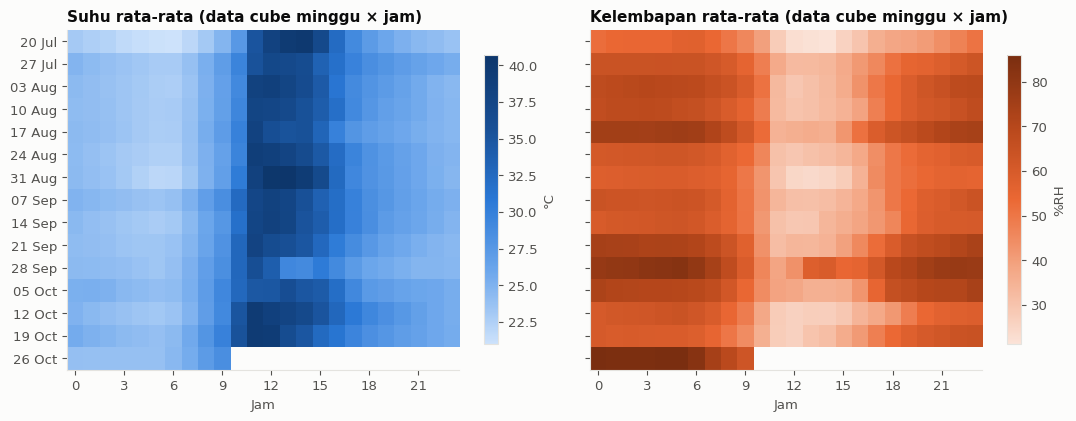

In [13]:
minggu = g.index.to_period('W').start_time
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for a, kol, cmap, judul, satuan in [(ax[0], 'temp', BIRU_SEQ, 'Suhu rata-rata (data cube minggu × jam)', '°C'),
                                     (ax[1], 'hum', ORANYE_SEQ, 'Kelembapan rata-rata (data cube minggu × jam)', '%RH')]:
    kubus = g.groupby([minggu, g.index.hour])[kol].mean().unstack()
    im = a.imshow(kubus.values, aspect='auto', cmap=cmap)
    a.set_yticks(range(len(kubus)), [d.strftime('%d %b') for d in kubus.index]); a.set_xticks(range(0, 24, 3))
    a.set_xlabel('Jam'); a.set_title(judul); a.grid(False); fig.colorbar(im, ax=a, label=satuan, shrink=.85)
fig.tight_layout(); plt.show()

**Hasil.** Dari 27.293 slot 5 menit, 87,4% terisi. Ada lima celah sepanjang 1 jam atau lebih, dan yang terpanjang adalah 188,7 jam pada 1-9 Oktober. Data cube memperlihatkan pola yang konsisten antar-minggu: panas pada sekitar jam 11-15, dan kelembapan terendah pada jam yang sama. Minggu 28 September terlihat lebih sejuk dan lembap.

## 6. Analisis eksploratif dan korelasi

### 6.1 Statistik dan pola harian

Dari `temp` dan `hum` diturunkan dua fitur yang lebih bermakna untuk tanaman: **VPD** (*vapor pressure deficit*, besarnya "tarikan" udara terhadap air pada daun) dan **titik embun**.

,count,mean,std,min,25%,50%,75%,max
temp,23855.0,28.15,5.25,19.80,24.10,26.20,30.80,43.90
hum,23855.0,53.49,16.36,12.00,41.00,55.00,66.00,92.00
lux,23855.0,700.16,1712.02,0.83,0.83,6.67,602.50,27788.30
vpd,23855.0,2.04,1.43,0.24,1.05,1.46,2.66,7.60
titik_embun,23855.0,16.87,2.67,5.44,15.32,17.24,18.73,23.01


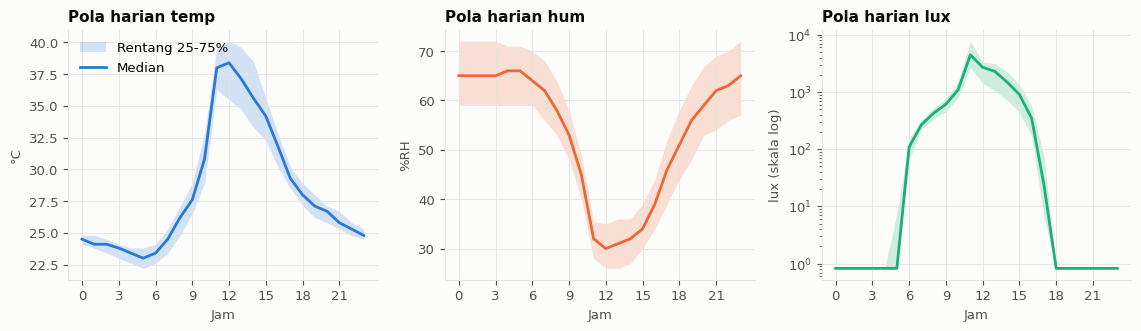

In [14]:
es = 0.6108 * np.exp(17.27 * g.temp / (g.temp + 237.3))
g['vpd'] = es * (1 - g.hum / 100)
gamma = np.log(g.hum / 100) + 17.27 * g.temp / (g.temp + 237.3)
g['titik_embun'] = 237.3 * gamma / (17.27 - gamma)
display(g[['temp', 'hum', 'lux', 'vpd', 'titik_embun']].describe().T.round(2))

profil = g.groupby(g.index.hour)
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.4))
for a, kol, label in [(ax[0], 'temp', '°C'), (ax[1], 'hum', '%RH'), (ax[2], 'lux', 'lux (skala log)')]:
    q = profil[kol].quantile([.25, .5, .75]).unstack()
    a.fill_between(q.index, q[.25], q[.75], color=WARNA[kol], alpha=.2, lw=0, label='Rentang 25-75%')
    a.plot(q.index, q[.5], color=WARNA[kol], lw=2, label='Median')
    a.set_title(f'Pola harian {kol}'); a.set_xlabel('Jam'); a.set_ylabel(label); a.set_xticks(range(0, 24, 3))
ax[2].set_yscale('log'); ax[0].legend(loc='upper left')
fig.tight_layout(); plt.show()

**Hasil.** Suhu berkisar 19,8-43,9 °C dan kelembapan 12-92 %RH. Titik embun relatif stabil (rata-rata 16,9 °C, simpangan 2,7), sehingga perubahan `hum` dalam sehari sebagian besar datang dari perubahan suhu, bukan dari perubahan jumlah uap air. `lux` sangat miring: median 6,7 sedangkan rata-rata 700.

### 6.2 Korelasi: mentah dan setelah siklus harian dihilangkan

Korelasi mentah bisa menipu. `temp` dan `lux` sama-sama tinggi saat siang, sehingga korelasinya besar walau sebagian hanya karena keduanya mengikuti jam. Karena itu dihitung juga korelasi **anomali**: nilai dikurangi rata-rata normal pada jam yang sama.

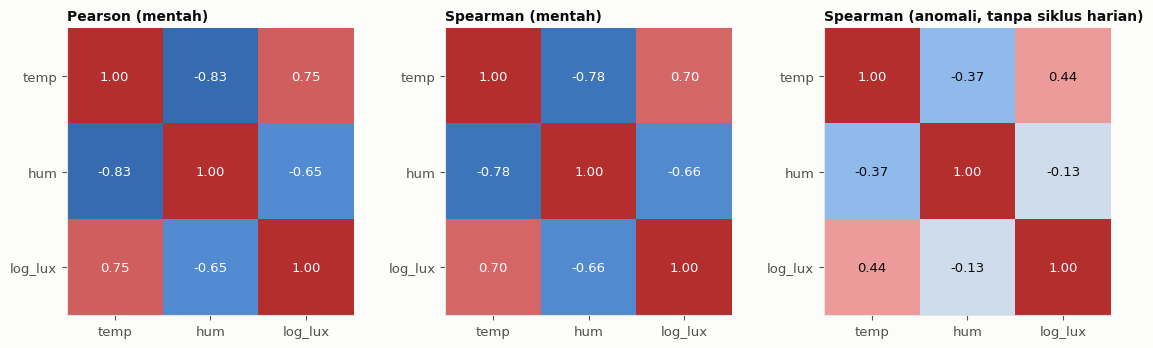

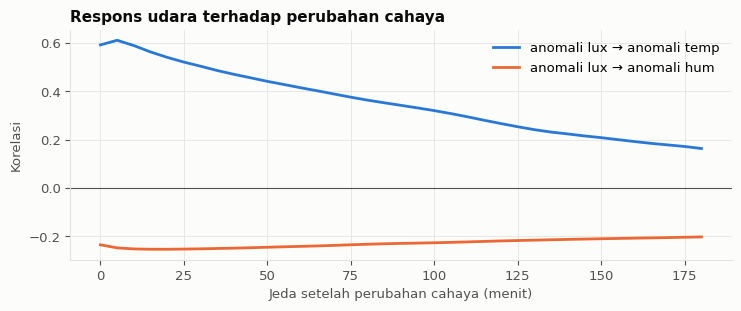

Korelasi terkuat: temp pada jeda 5 menit | hum pada jeda 20 menit


In [15]:
fitur_korelasi = ['temp', 'hum', 'log_lux']
slot = g.index.hour * 12 + g.index.minute // 5
anomali = g[fitur_korelasi] - g[fitur_korelasi].groupby(slot).transform('mean')
matriks = {'Pearson (mentah)': g[fitur_korelasi].corr(), 'Spearman (mentah)': g[fitur_korelasi].corr('spearman'),
           'Spearman (anomali, tanpa siklus harian)': anomali.corr('spearman')}
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.5))
for a, (judul, m) in zip(ax, matriks.items()):
    a.imshow(m.values, cmap=DIVERGEN, norm=TwoSlopeNorm(0, -1, 1)); a.grid(False); a.set_title(judul, fontsize=10)
    a.set_xticks(range(3), fitur_korelasi); a.set_yticks(range(3), fitur_korelasi)
    for i in range(3):
        for j in range(3):
            a.text(j, i, f'{m.values[i, j]:.2f}', ha='center', va='center', color='white' if abs(m.values[i, j]) > .6 else TINTA)
fig.tight_layout(); plt.show()

lag_menit = np.arange(0, 185, 5)
kor_lag = pd.DataFrame({'temp': [anomali.log_lux.shift(l // 5).corr(anomali.temp) for l in lag_menit],
                        'hum': [anomali.log_lux.shift(l // 5).corr(anomali.hum) for l in lag_menit]}, index=lag_menit)
fig, a = plt.subplots(figsize=(7.5, 3.2))
for k in kor_lag: a.plot(kor_lag.index, kor_lag[k], color=WARNA[k], lw=2, label=f'anomali lux → anomali {k}')
a.axhline(0, color=TINTA2, lw=.8); a.set_xlabel('Jeda setelah perubahan cahaya (menit)'); a.set_ylabel('Korelasi')
a.set_title('Respons udara terhadap perubahan cahaya'); a.legend(); fig.tight_layout(); plt.show()
print('Korelasi terkuat: temp pada jeda', kor_lag.temp.abs().idxmax(), 'menit | hum pada jeda', kor_lag.hum.abs().idxmax(), 'menit')

**Hasil.** Korelasi mentah terlihat kuat, tetapi banyak yang berasal dari siklus harian.

| Pasangan | Pearson mentah | Spearman mentah | Spearman anomali |
|---|---|---|---|
| `temp` - `hum` | -0,83 | -0,78 | -0,37 |
| `temp` - `lux` | 0,75 | 0,70 | 0,44 |
| `hum` - `lux` | -0,65 | -0,66 | -0,13 |

Setelah pengaruh jam dihilangkan, hubungan yang tersisa adalah `temp` dengan `lux` dan `temp` dengan `hum`. `hum` hampir tidak terkait langsung dengan `lux`. Suhu merespons cahaya hampir seketika (jeda terkuat 5 menit), sedangkan kelembapan menyusul sekitar 20 menit kemudian. Korelasi ini menunjukkan keterkaitan, bukan penyebab.

### 6.3 Paparan panas dan cahaya

Ambang analisis: suhu **35 °C** dan VPD **1,5 kPa**. Keduanya asumsi kerja, karena jenis tanaman belum diketahui. Ambang 35 °C mengacu pada percobaan tomat yang menggunakan siang 35 °C, dan ambang 32 °C diuji sebagai pembanding di bagian 10. Angka VPD berasal dari panduan praktisi, bukan riset spesifik satu tanaman.

Hari dengan data cukup            : 79
Hari yang menyentuh >= 35 °C      : 79 (100%)
Rata-rata jam >= 35 °C per hari   : 3.5 jam
Rata-rata jam VPD >= 1,5 per hari : 11.6 jam
Perkiraan kasar cahaya harian     : 1.1 mol/m²/hari (konversi matahari ±0,0185 µmol per lux)
Lux tertinggi                     : 28,298


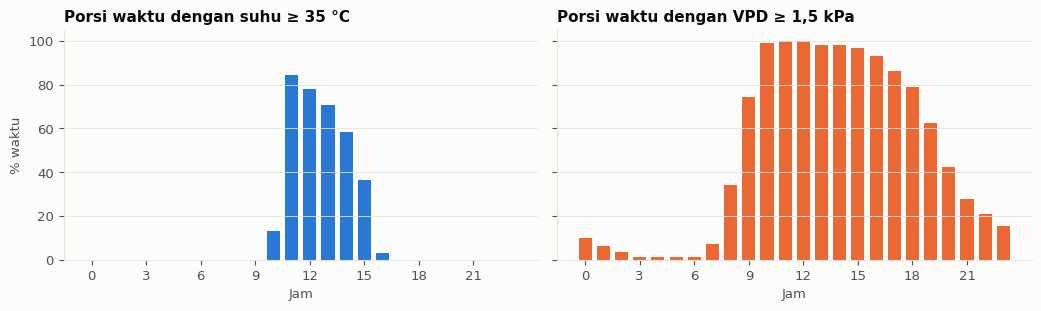

In [16]:
AMBANG_PANAS, AMBANG_VPD = 35.0, 1.5
ada = g.temp.notna()
panas, kering = (g.temp >= AMBANG_PANAS)[ada], (g.vpd >= AMBANG_VPD)[ada]
harian = pd.DataFrame({'jam_panas': panas.resample('1D').sum() * 5 / 60, 'jam_vpd_tinggi': kering.resample('1D').sum() * 5 / 60,
                       'slot': ada[ada].resample('1D').sum()})
harian = harian[harian.slot >= 200]
print(f'Hari dengan data cukup            : {len(harian)}')
print(f'Hari yang menyentuh >= 35 °C      : {(harian.jam_panas > 0).sum()} ({(harian.jam_panas > 0).mean():.0%})')
print(f'Rata-rata jam >= 35 °C per hari   : {harian.jam_panas.mean():.1f} jam')
print(f'Rata-rata jam VPD >= 1,5 per hari : {harian.jam_vpd_tinggi.mean():.1f} jam')
dli = (g.lux.dropna().resample('1D').mean() * 0.0185 * 86400 / 1e6)
print(f'Perkiraan kasar cahaya harian     : {dli.median():.1f} mol/m²/hari (konversi matahari ±0,0185 µmol per lux)')
print(f'Lux tertinggi                     : {data.lux.max():,.0f}')

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2), sharey=True)
ax[0].bar(range(24), panas.groupby(panas.index.hour).mean() * 100, color=WARNA['temp'], width=.72)
ax[0].set_title('Porsi waktu dengan suhu ≥ 35 °C'); ax[0].set_ylabel('% waktu')
ax[1].bar(range(24), kering.groupby(kering.index.hour).mean() * 100, color=WARNA['hum'], width=.72)
ax[1].set_title('Porsi waktu dengan VPD ≥ 1,5 kPa')
for a in ax: a.set_xlabel('Jam'); a.set_xticks(range(0, 24, 3)); a.grid(axis='x', visible=False)
fig.tight_layout(); plt.show()

**Hasil.** Semua 79 hari dengan data cukup menyentuh 35 °C, rata-rata 3,5 jam per hari. VPD di atas 1,5 kPa berlangsung 11,6 jam per hari, jadi udara di lokasi sensor sering sangat kering bagi tanaman.

Cahaya harian yang terukur hanya sekitar 1,1 mol/m²/hari dan lux tertinggi 28.298, jauh di bawah sinar matahari penuh. Sensor cahaya tampaknya berada di tempat teduh hampir sepanjang hari. Angka ini perkiraan kasar dan belum tentu mewakili kondisi tanaman.

### 6.4 Waktu mulai panas: sangat presisi dan bergeser

Pola harian di atas menunjukkan suhu naik sangat tajam sekitar pukul 11. Cell berikut mengukur jam pertama suhu menyentuh 35 °C pada setiap hari, dan membandingkan suhu serta cahaya per 30 menit.

,hari,median,p10,p90
23 Jul - 15 Sep,51.0,11:05,10:55,11:20
16 Sep - 1 Okt,14.0,10:50,10:45,10:53
9 - 26 Okt,16.0,10:35,10:27,10:40


,temp,hum,lux
jam,,,
9.0,27.1,54.0,559.6
9.5,28.0,52.0,674.2
10.0,29.4,48.0,895.0
10.5,32.3,42.0,1430.0
11.0,38.0,33.0,6989.2
11.5,38.5,31.0,3065.0
12.0,38.0,30.0,2699.2
12.5,38.5,30.0,2704.6


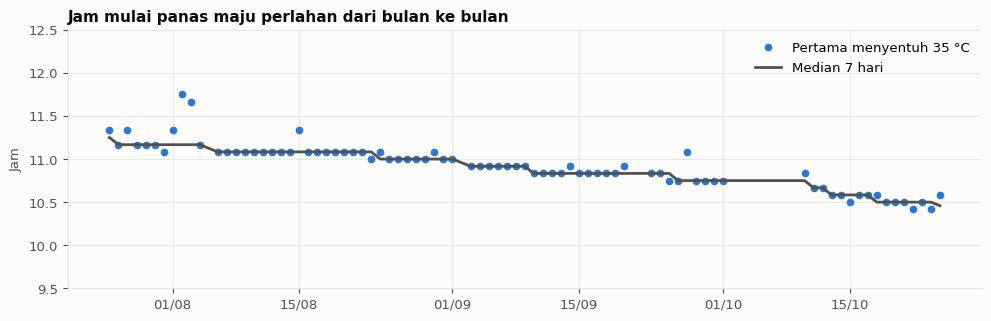

In [17]:
hari_panas = g.index[(g.temp >= AMBANG_PANAS)]
mulai_panas = pd.Series(hari_panas, index=hari_panas).groupby(hari_panas.normalize()).min()
jam_mulai = (mulai_panas - mulai_panas.index).dt.total_seconds() / 3600
# Hari yang datanya baru mulai siang tidak bisa dipakai: pagi harinya tidak terukur
slot_pagi = g.temp.between_time('08:00', '10:00').notna().groupby(lambda t: t.normalize()).sum()
jam_mulai = jam_mulai[jam_mulai.index.isin(slot_pagi[slot_pagi >= 20].index)]
fase_mulai = pd.DataFrame({n: {'hari': len(x), 'median': x.median(), 'p10': x.quantile(.1), 'p90': x.quantile(.9)} for n, x in
                           [('23 Jul - 15 Sep', jam_mulai[:'2026-09-15']), ('16 Sep - 1 Okt', jam_mulai['2026-09-16':'2026-10-01']), ('9 - 26 Okt', jam_mulai['2026-10-09':])]}).T
fase_mulai[['median', 'p10', 'p90']] = fase_mulai[['median', 'p10', 'p90']].map(lambda v: f'{int(v):02d}:{int(round(v % 1 * 60)):02d}')
display(fase_mulai)

pagi = g[(g.index.hour >= 9) & (g.index.hour < 13)]
display(pagi.groupby(pagi.index.hour + pagi.index.minute // 30 / 2)[['temp', 'hum', 'lux']].median().round(1).rename_axis('jam'))

fig, a = plt.subplots(figsize=(10, 3.3))
a.plot(jam_mulai.index, jam_mulai, ls='none', marker='o', ms=4.5, color=WARNA['temp'], label='Pertama menyentuh 35 °C')
a.plot(jam_mulai.index, jam_mulai.rolling(7, center=True, min_periods=3).median(), color=TINTA2, lw=2, label='Median 7 hari')
a.set_ylim(9.5, 12.5); a.set_ylabel('Jam'); a.set_title('Jam mulai panas maju perlahan dari bulan ke bulan')
a.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m')); a.legend(loc='upper right'); fig.tight_layout(); plt.show()

**Hasil. Ini temuan paling penting pada tahap eksplorasi.** Suhu melompat dari 29,4 °C pada pukul 10:00 menjadi 38,0 °C pada pukul 11:00, bersamaan dengan `lux` yang naik dari 895 menjadi 6.989. Jam mulainya sangat presisi dari hari ke hari, dan maju perlahan dari sekitar 11:05 pada Agustus menjadi 10:35 pada Oktober.

Polanya cocok dengan **sinar matahari langsung yang mengenai sensor pada jam tertentu**, dan posisinya bergeser mengikuti musim. Ini masih hipotesis dan perlu dicek di lokasi. Jika sensor suhu tidak memakai pelindung radiasi, suhu siang yang terbaca bisa lebih tinggi dari suhu udara sebenarnya, sehingga seluruh angka paparan panas perlu dibaca dengan hati-hati.

Pergeseran ini juga menyulitkan model: data test memiliki waktu mulai panas yang lebih awal daripada hampir semua hari di data train.

## 7. Partisi data dan feature scaling

Data sensor berurutan waktu, jadi partisi dibuat **kronologis**: model dilatih dari masa lalu dan diuji pada masa depan yang belum pernah dilihat. Pembagian acak akan membuat dua baris yang berjarak 5 menit masuk ke train dan test sekaligus, sehingga skornya terlihat lebih bagus daripada kenyataan. Efek ini diukur di bagian 8.

Scaler hanya dihitung dari data train. Materi *Feature Scaling* diterapkan sebagai berikut:

- **Standardisasi (z-score)** untuk jaringan saraf, supaya `temp`, `hum`, dan `log_lux` berada di skala yang sebanding.
- **Normalisasi (0-1)** ditampilkan sebagai pembanding. Tidak dipakai karena satu nilai ekstrem bisa menekan seluruh skala.
- Model berbasis pohon (gradient boosting) tidak memerlukan scaling.

In [18]:
AKHIR_TRAIN, AKHIR_VAL, AWAL_TEST = '2026-09-16', '2026-10-02', '2026-10-09'
is_train = g.index < AKHIR_TRAIN
is_val = (g.index >= AKHIR_TRAIN) & (g.index < AKHIR_VAL)
is_test = g.index >= AWAL_TEST

ringkas = pd.DataFrame({n: {'mulai': g.index[m][0], 'selesai': g.index[m][-1], 'slot_terisi': int(g.temp[m].notna().sum()), 'suhu_rata2': g.temp[m].mean(),
                            'hum_rata2': g.hum[m].mean(), 'lux_median': g.lux[m].median()} for n, m in [('train', is_train), ('validasi', is_val), ('test', is_test)]}).T
display(ringkas)

sampel = g.loc[is_train, ['temp', 'hum', 'lux', 'log_lux']].dropna()
skala = pd.DataFrame({'min asli': sampel.min(), 'maks asli': sampel.max(), 'rata2 asli': sampel.mean(), 'std asli': sampel.std(),
                      'min z-score': (sampel.min() - sampel.mean()) / sampel.std(), 'maks z-score': (sampel.max() - sampel.mean()) / sampel.std(),
                      'median setelah 0-1': ((sampel - sampel.min()) / (sampel.max() - sampel.min())).median()})
display(skala.round(3))

,mulai,selesai,slot_terisi,suhu_rata2,hum_rata2,lux_median
train,2026-07-23 14:55:00,2026-09-15 23:55:00,14913,28.038225,52.645611,5.0
validasi,2026-09-16 00:00:00,2026-10-01 23:55:00,4040,27.736572,59.398144,7.5
test,2026-10-09 00:00:00,2026-10-26 09:15:00,4902,28.84849,51.209302,12.5


,min asli,maks asli,rata2 asli,std asli,min z-score,maks z-score,median setelah 0-1
temp,19.800,43.500,28.038,5.393,-1.528,2.867,0.270
hum,13.000,88.000,52.646,15.516,-2.555,2.279,0.560
lux,0.830,23353.300,743.827,1771.727,-0.419,12.761,0.000
log_lux,0.604,10.059,3.514,3.070,-0.948,2.132,0.126


**Hasil.** Train memiliki 14.913 slot terisi, validasi 4.040, dan test 4.902. Celah 2-8 Oktober tidak dipakai, jadi data test benar-benar terpisah. Kondisi tiap periode berbeda (kelembapan rata-rata 52,6, 59,4, dan 51,2 %RH), sehingga pengujian ini cukup realistis. Setelah z-score, `lux` asli masih mencapai 12,8 simpangan baku, sedangkan `log_lux` hanya 2,1. Karena itu model memakai `log_lux`.

## 8. Model A: `SensorFill`, input sebagian lalu memprediksi sisanya

`SensorFill` adalah model khusus untuk dataset ini (PyTorch). Satu jaringan menerima kombinasi sensor apa pun, lalu memperkirakan sensor yang hilang.

- **Input:** riwayat 1 jam (12 titik) dari `temp`, `hum`, `log_lux`, ditambah penanda sensor mana yang tersedia dan jam dalam sehari.
- **Cara belajar:** setiap batch, sensor disembunyikan secara acak dan model diminta menebaknya kembali (*masked training*). Sensor yang disembunyikan tidak terlihat di seluruh jendela 1 jam.
- **Pembanding:** rata-rata per jam, dan gradient boosting yang dilatih terpisah untuk setiap kombinasi input.

Model dilatih dengan 3 seed. Bobot yang dipakai adalah epoch dengan loss validasi terendah.

In [19]:
SENSOR, W = ['temp', 'hum', 'log_lux'], 12
A = g[SENSOR].to_numpy('float32')
T_JAM = g[['jam_sin', 'jam_cos']].to_numpy('float32')
MU, SD = np.nanmean(A[is_train], 0), np.nanstd(A[is_train], 0)
Z = (A - MU) / SD

lengkap = pd.Series(~np.isnan(Z).any(axis=1)).rolling(W).sum().eq(W).to_numpy()
idx_all = np.flatnonzero(lengkap)
i_tr, i_va, i_te = idx_all[is_train[idx_all]], idx_all[is_val[idx_all]], idx_all[is_test[idx_all]]

def tensor_jendela(I, sumber=Z):
    return torch.tensor(np.stack([sumber[i - W + 1:i + 1] for i in I])), torch.tensor(T_JAM[I]), torch.tensor(np.nan_to_num(sumber[I]))

x_tr, t_tr, y_tr = tensor_jendela(i_tr); x_va, t_va, y_va = tensor_jendela(i_va); x_te, t_te, y_te = tensor_jendela(i_te)
MASKER = torch.tensor([[a, b, c] for a in (0, 1) for b in (0, 1) for c in (0, 1)], dtype=torch.float32)
print(f'Jendela lengkap: train {len(i_tr):,} | validasi {len(i_va):,} | test {len(i_te):,}')

class SensorFill(nn.Module):
    def __init__(self, hidden=128, dropout=.1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(W * 3 + 3 + 2, hidden), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden), nn.GELU(), nn.Linear(hidden, 3))
    def forward(self, x, masker, jam):
        return self.net(torch.cat([(x * masker[:, None, :]).flatten(1), masker, jam], 1))

def loss_masked(p, y, m):
    bobot = (1 - m) + .1 * m      # sensor tersembunyi jadi fokus utama
    return ((p - y) ** 2 * bobot).sum() / bobot.sum()

def prediksi_net(net, x, t, masker):
    net.eval()
    with torch.no_grad():
        return net(x, torch.tensor(masker, dtype=torch.float32).repeat(len(x), 1), t).numpy() * SD + MU

def latih_sensorfill(seed, epoch=60, batch=256):
    torch.manual_seed(seed)
    net = SensorFill()
    opt = torch.optim.AdamW(net.parameters(), lr=1.5e-3, weight_decay=1e-3)
    jadwal = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epoch)
    riwayat, terbaik, bobot_terbaik, n = [], np.inf, None, len(x_tr)
    y_val = y_va.numpy() * SD + MU
    for e in range(1, epoch + 1):
        net.train(); total = 0.
        urutan = torch.randperm(n)
        for i in range(0, n, batch):
            b = urutan[i:i + batch]; m = MASKER[torch.randint(0, 8, (len(b),))]
            loss = loss_masked(net(x_tr[b], m, t_tr[b]), y_tr[b], m)
            opt.zero_grad(); loss.backward(); opt.step(); total += loss.item() * len(b)
        jadwal.step(); net.eval()
        with torch.no_grad():
            v = np.mean([loss_masked(net(x_va, MASKER[k].repeat(len(x_va), 1), t_va), y_va, MASKER[k].repeat(len(x_va), 1)).item() for k in range(7)])
        riwayat.append({'epoch': e, 'loss_train': total / n, 'loss_val': v,
                        'MAE_val_temp_dari_hum+lux': mean_absolute_error(y_val[:, 0], prediksi_net(net, x_va, t_va, [0, 1, 1])[:, 0]),
                        'MAE_val_hum_dari_temp+lux': mean_absolute_error(y_val[:, 1], prediksi_net(net, x_va, t_va, [1, 0, 1])[:, 1]),
                        'lr': opt.param_groups[0]['lr']})
        if v < terbaik:
            terbaik, bobot_terbaik = v, {k: w.clone() for k, w in net.state_dict().items()}
    net.load_state_dict(bobot_terbaik)
    return net, pd.DataFrame(riwayat).set_index('epoch')

mulai = time.time()
hasil_seed = {s: latih_sensorfill(s) for s in (0, 1, 2)}
print(f'Waktu latih 3 seed: {time.time() - mulai:.0f} detik | parameter per model: {sum(p.numel() for p in hasil_seed[0][0].parameters()):,}')
ringkas_seed = pd.DataFrame({s: {'epoch_terbaik': r.loss_val.idxmin(), 'loss_val_terbaik': r.loss_val.min(), 'loss_train_saat_itu': r.loss_train[r.loss_val.idxmin()]} for s, (n_, r) in hasil_seed.items()}).T
ringkas_seed.index.name = 'seed'
display(ringkas_seed.round(4))
seed_pilih = int(ringkas_seed.loss_val_terbaik.idxmin())
net, riwayat = hasil_seed[seed_pilih]
print('Seed terpilih:', seed_pilih)
display(riwayat.iloc[[0, 1, 2, 4, 9, 14, 19, 29, 39, 49, 59]].round(4))

Jendela lengkap: train 14,837 | validasi 4,016 | test 4,891
Waktu latih 3 seed: 40 detik | parameter per model: 38,787


,epoch_terbaik,loss_val_terbaik,loss_train_saat_itu
seed,,,
0,32.0,0.1923,0.1052
1,36.0,0.1937,0.1012
2,51.0,0.1935,0.1012


Seed terpilih: 0


,loss_train,loss_val,MAE_val_temp_dari_hum+lux,MAE_val_hum_dari_temp+lux,lr
epoch,,,,,
1,0.4264,0.2922,1.3055,9.8347,0.0015
2,0.1644,0.2657,0.9504,9.8341,0.0015
3,0.1476,0.2517,0.9325,9.5247,0.0015
5,0.1348,0.2489,0.7930,9.4548,0.0015
10,0.1182,0.2184,0.8328,8.9413,0.0014
15,0.1131,0.2245,0.7925,9.0679,0.0013
20,0.1086,0.1985,0.7203,8.4648,0.0011
30,0.1054,0.2156,0.8148,8.6722,0.0008
40,0.1023,0.2037,0.7724,8.3848,0.0004


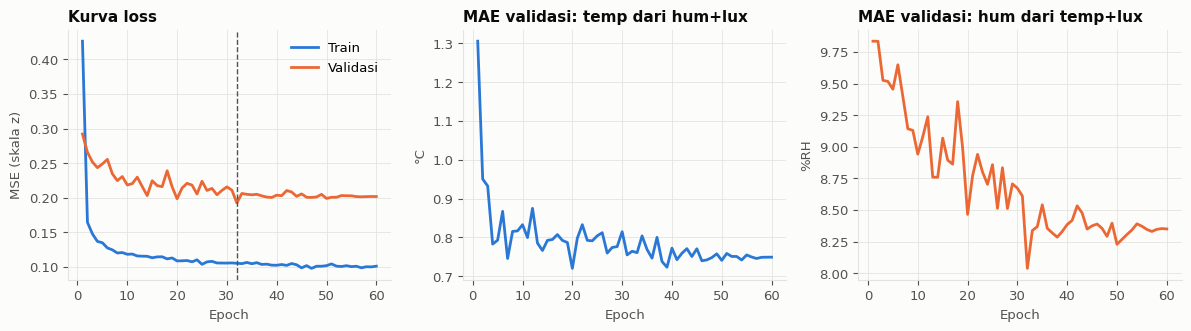

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(riwayat.index, riwayat.loss_train, color=WARNA['temp'], lw=2, label='Train')
ax[0].plot(riwayat.index, riwayat.loss_val, color=WARNA['hum'], lw=2, label='Validasi')
ax[0].axvline(riwayat.loss_val.idxmin(), color=TINTA2, ls='--', lw=1); ax[0].set_title('Kurva loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('MSE (skala z)'); ax[0].legend()
ax[1].plot(riwayat.index, riwayat['MAE_val_temp_dari_hum+lux'], color=WARNA['temp'], lw=2)
ax[1].set_title('MAE validasi: temp dari hum+lux'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('°C')
ax[2].plot(riwayat.index, riwayat['MAE_val_hum_dari_temp+lux'], color=WARNA['hum'], lw=2)
ax[2].set_title('MAE validasi: hum dari temp+lux'); ax[2].set_xlabel('Epoch'); ax[2].set_ylabel('%RH')
fig.tight_layout(); plt.show()

**Hasil latihan.** Ketiga seed berakhir pada loss validasi yang hampir sama (0,192-0,194), jadi hasilnya tidak bergantung pada keberuntungan seed. Model memiliki 38.787 parameter dan dilatih di CPU dalam sekitar 30 detik.

Loss train terus turun sampai 0,10, sedangkan loss validasi mendatar di sekitar 0,20. Selisih ini menunjukkan kondisi validasi memang berbeda dari train. Karena itu bobot yang dipakai adalah epoch terbaik di validasi (garis putus-putus), bukan epoch terakhir.

**Konfigurasi latihan `SensorFill`.**

| Komponen | Nilai |
|---|---|
| Input | 12 titik × 3 sensor, 3 penanda sensor, 2 fitur jam (41 angka) |
| Jaringan | 3 lapisan tersembunyi, masing-masing 128 neuron, aktivasi GELU |
| Dropout | 0,1 |
| Optimizer | AdamW, learning rate awal 0,0015, weight decay 0,001 |
| Jadwal learning rate | Cosine, turun bertahap sampai mendekati 0 |
| Epoch dan batch | 60 epoch, 256 data per batch |
| Loss | MSE berbobot: sensor tersembunyi bobot 1, sensor terlihat bobot 0,1 |
| Model terpilih | Seed 0, epoch 32, loss train 0,1052, loss validasi 0,1923 |

In [21]:
def latih_gbr(Xa, ya, Xv, yv, max_iter=400, lr=.05, langkah=5):
    """Melatih boosting dan memilih jumlah pohon dari validasi kronologis, bukan dari data test."""
    param = dict(learning_rate=lr, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1., early_stopping=False, random_state=SEED)
    m = HistGradientBoostingRegressor(max_iter=max_iter, **param).fit(Xa, ya)
    rmse = lambda y, p: float(np.sqrt(np.mean((np.asarray(y) - p) ** 2)))
    tr = [rmse(ya, p) for i, p in enumerate(m.staged_predict(Xa), 1) if i % langkah == 0]
    va = [rmse(yv, p) for i, p in enumerate(m.staged_predict(Xv), 1) if i % langkah == 0]
    riw = pd.DataFrame({'rmse_train': tr, 'rmse_val': va}, index=range(langkah, max_iter + 1, langkah))
    m = HistGradientBoostingRegressor(max_iter=int(riw.rmse_val.idxmin()), **param).fit(Xa, ya)
    return m, riw

NAMA = {'temp': 'temp', 'hum': 'hum', 'log_lux': 'lux'}
JAM = ['jam_sin', 'jam_cos']
gi = g.reset_index(drop=True)
model_vs, baris = {}, []
y_jam = g.index.hour
for mk in MASKER.tolist()[:-1]:
    terlihat = [s for s, b in zip(SENSOR, mk) if b]
    p_net = prediksi_net(net, x_te, t_te, mk)
    for j, target in enumerate(SENSOR):
        if mk[j]: continue
        F = terlihat + JAM
        gbr, _ = latih_gbr(gi.loc[i_tr, F], gi.loc[i_tr, target], gi.loc[i_va, F], gi.loc[i_va, target], max_iter=300)
        model_vs[(target, tuple(terlihat))] = gbr
        y = gi.loc[i_te, target].to_numpy(); p_gbr = gbr.predict(gi.loc[i_te, F])
        rata_jam = gi.loc[i_tr].groupby(y_jam[i_tr])[target].mean()
        p_base = pd.Series(y_jam[i_te]).map(rata_jam).to_numpy()
        for nama_model, p in [('Rata-rata per jam', p_base), ('Gradient boosting', p_gbr), ('SensorFill', p_net[:, j])]:
            baris.append({'target': NAMA[target], 'input': ' + '.join(NAMA[s] for s in terlihat) or '(jam saja)', 'model': nama_model, **metrik(y, p)})
hasil_vs = pd.DataFrame(baris)
tabel_vs = hasil_vs.pivot_table(index=['target', 'input'], columns='model', values=['MAE', 'R2'], sort=False)
tabel_vs = tabel_vs.reindex(columns=[(m, n) for m in ('MAE', 'R2') for n in ('Rata-rata per jam', 'Gradient boosting', 'SensorFill')])
display(tabel_vs.round(3))
print('Satuan MAE: temp = °C, hum = %RH, lux = log(1+lux).')

siang = (y_jam[i_te] >= 6) & (y_jam[i_te] < 18)
baris_lux = []
for label, mk in [('temp + hum', [1, 1, 0]), ('temp', [1, 0, 0]), ('hum', [0, 1, 0])]:
    p = np.expm1(prediksi_net(net, x_te, t_te, mk)[:, 2]); y = gi.loc[i_te, 'lux'].to_numpy()
    baris_lux.append({'input': label, **metrik(y[siang], p[siang])})
print('\nPrediksi lux khusus siang (06-18), satuan lux asli, oleh SensorFill:')
display(pd.DataFrame(baris_lux).round(2))

MAE                                             R2                             
model             Rata-rata per jam Gradient boosting SensorFill Rata-rata per jam Gradient boosting SensorFill
target input                                                                                                   
temp   (jam saja)             1.808             1.668      1.763             0.778             0.779      0.798
       lux                    1.808             1.491      1.525             0.778             0.844      0.869
       hum                    1.808             1.193      1.267             0.778             0.910      0.912
       hum + lux              1.808             1.113      1.257             0.778             0.925      0.912
hum    (jam saja)             8.266             8.226      8.173             0.606             0.612      0.615
       lux                    8.266             8.288      7.913             0.606             0.614      0.638
       temp                   8.266             6.090      6.294             0.606             0.773      0.767
       temp + lux             8.266             5.809      6.348             0.606             0.795      0.766
lux    (jam saja)             0.414             0.414      0.400             0.928             0.945      0.945
       hum                    0.414             0.367      0.307             0.928             0.953      0.968
       temp                   0.414             0.340      0.318             0.928             0.962      0.967
       temp + hum             0.414             0.329      0.288             0.928             0.963      0.976

Satuan MAE: temp = °C, hum = %RH, lux = log(1+lux).

Prediksi lux khusus siang (06-18), satuan lux asli, oleh SensorFill:


,input,MAE,RMSE,R2
0,temp + hum,342.09,747.47,0.80
1,temp,361.47,763.64,0.79
2,hum,428.98,1037.44,0.61


**Cara membaca.** MAE adalah rata-rata kesalahan absolut, dan R² menunjukkan seberapa banyak variasi yang dijelaskan (1 berarti sempurna).

| Situasi | Rata-rata per jam | Gradient boosting | SensorFill |
|---|---|---|---|
| `temp` dari `hum` + `lux` | 1,81 °C | **1,11 °C** | 1,26 °C |
| `hum` dari `temp` + `lux` | 8,27 %RH | **5,81 %RH** | 6,35 %RH |
| `temp` dari `lux` saja | 1,81 °C | **1,49 °C** | 1,53 °C |
| `hum` dari `lux` saja | 8,27 %RH | 8,29 %RH | **7,91 %RH** |

- Gradient boosting sedikit lebih akurat bila kombinasi input sudah pasti. Ia membutuhkan satu model untuk setiap kombinasi.
- `SensorFill` memakai satu model untuk semua kombinasi, dan unggul pada prediksi `lux` serta `hum` dari `lux` saja.
- `hum` paling sulit, karena perubahan kelembapan antar-hari tidak terlihat dari sensor lain.
- R² `lux` yang tinggi (sampai 0,976) sebagian besar hanya membedakan siang dan malam. Pada siang hari R² turun menjadi 0,80 dengan MAE 342 lux, dan itu angka yang lebih jujur.

In [22]:
# Mengukur efek kebocoran: skenario sama (temp dari hum+lux), hanya cara membagi data yang berbeda
F = ['hum', 'log_lux'] + JAM
semua = gi.loc[idx_all]
acak = np.random.RandomState(SEED).rand(len(semua)) < .8
m_acak = HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, random_state=SEED).fit(semua.loc[acak, F], semua.loc[acak, 'temp'])
m_krono = model_vs[('temp', ('hum', 'log_lux'))]
kebocoran = pd.DataFrame({'Split acak (bocor)': metrik(semua.loc[~acak, 'temp'], m_acak.predict(semua.loc[~acak, F])),
                          'Split kronologis (jujur)': metrik(gi.loc[i_te, 'temp'], m_krono.predict(gi.loc[i_te, F]))}).T
display(kebocoran.round(3))

,MAE,RMSE,R2
Split acak (bocor),0.650,0.856,0.974
Split kronologis (jujur),1.113,1.432,0.925


**Hasil.** Dengan split acak, R² terlihat 0,974 dan MAE 0,65 °C. Dengan split kronologis, R² 0,925 dan MAE 1,11 °C, atau kesalahan sekitar 1,7 kali lebih besar. Split acak terlihat lebih bagus hanya karena test berisi baris tetangga dari data train. Angka kronologislah yang mewakili pemakaian nyata.

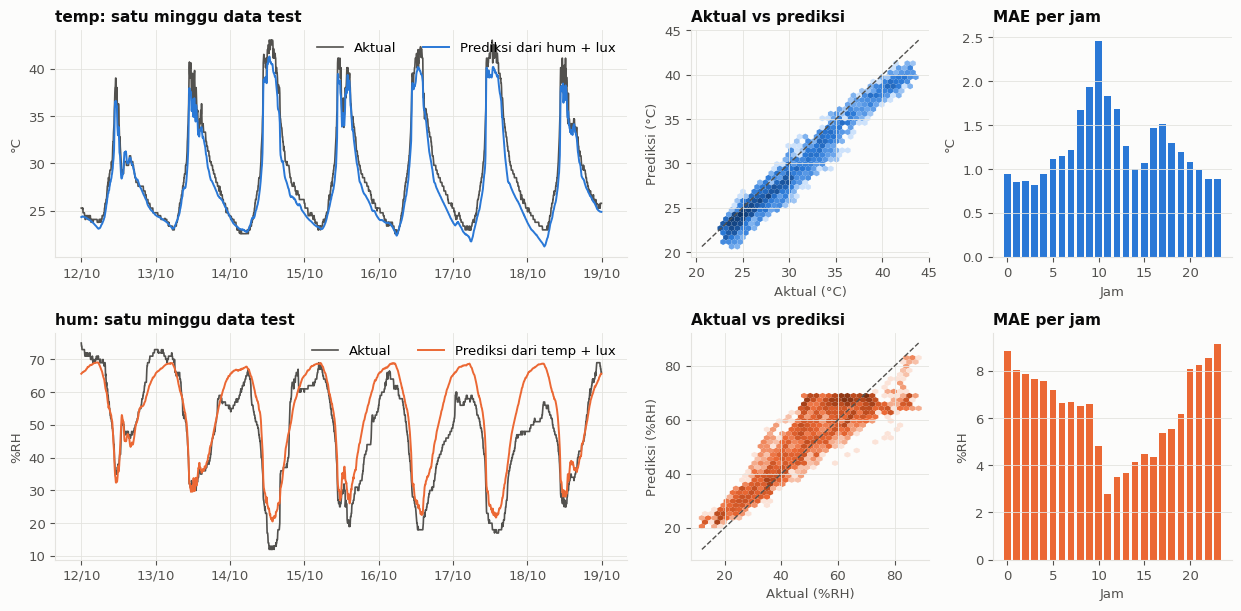

In [23]:
p_te = {'temp': prediksi_net(net, x_te, t_te, [0, 1, 1])[:, 0], 'hum': prediksi_net(net, x_te, t_te, [1, 0, 1])[:, 1]}
fig, ax = plt.subplots(2, 3, figsize=(12.5, 6.2), gridspec_kw={'width_ratios': [2.4, 1, 1]})
sepekan = (g.index[i_te] >= '2026-10-12') & (g.index[i_te] < '2026-10-19')
for r, (k, sat, inp) in enumerate([('temp', '°C', 'hum + lux'), ('hum', '%RH', 'temp + lux')]):
    y = gi.loc[i_te, k].to_numpy(); p = p_te[k]; waktu_te = g.index[i_te]
    ax[r, 0].plot(waktu_te[sepekan], y[sepekan], color=TINTA2, lw=1.2, label='Aktual')
    ax[r, 0].plot(waktu_te[sepekan], p[sepekan], color=WARNA[k], lw=1.4, label=f'Prediksi dari {inp}')
    ax[r, 0].set_title(f'{k}: satu minggu data test'); ax[r, 0].set_ylabel(sat); ax[r, 0].legend(loc='upper right', ncol=2); ax[r, 0].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
    ax[r, 1].hexbin(y, p, gridsize=35, cmap=BIRU_SEQ if k == 'temp' else ORANYE_SEQ, mincnt=1, bins='log', linewidths=0)
    batas = [min(y.min(), p.min()), max(y.max(), p.max())]; ax[r, 1].plot(batas, batas, color=TINTA2, lw=1, ls='--')
    ax[r, 1].set_title('Aktual vs prediksi'); ax[r, 1].set_xlabel(f'Aktual ({sat})'); ax[r, 1].set_ylabel(f'Prediksi ({sat})')
    err = pd.Series(np.abs(y - p)).groupby(y_jam[i_te]).mean()
    ax[r, 2].bar(err.index, err.values, color=WARNA[k], width=.72); ax[r, 2].set_title('MAE per jam'); ax[r, 2].set_xlabel('Jam'); ax[r, 2].set_ylabel(sat); ax[r, 2].grid(axis='x', visible=False)
fig.tight_layout(); plt.show()

**Hasil.** Kesalahan `temp` tertinggi sekitar pukul 10 (±2,5 °C). Model belajar dari data ketika panas mulai sekitar pukul 11, padahal pada data test panas mulai sekitar 10:35, sesuai temuan 6.4. Kesalahan `hum` tertinggi pada malam hari (±9 %RH), karena kelembapan malam bergantung pada cuaca yang tidak terlihat dari sensor lain.

### 8.1 Penerapan: menangani missing value (materi *How to handle missing value*)

Lima metode pada materi diuji dengan eksperimen. Pada data test yang sebenarnya lengkap, `temp` dan `hum` dihapus bersamaan selama 1, 6, dan 20 jam, sesuai pola kerusakan yang terjadi. Nilai aslinya lalu dibandingkan dengan isian tiap metode.

Input yang tersisa saat sensor suhu-kelembapan mati hanya `lux` dan jam, jadi model diuji dengan kondisi itu. Metode terakhir mengoreksi prediksi model memakai selisih di kedua tepi celah.

In [24]:
idx_te_grid = np.flatnonzero(is_test)
gap_fitur = ['log_lux'] + JAM
ok_lux = g.loc[is_test, 'log_lux'].notna().to_numpy()
p_gbr_lux = {k: pd.Series(np.nan, index=g.index) for k in ('temp', 'hum')}
for k in p_gbr_lux:
    p_gbr_lux[k].iloc[idx_te_grid[ok_lux]] = model_vs[(k, ('log_lux',))].predict(gi.loc[idx_te_grid[ok_lux], gap_fitur])

# SensorFill hanya melihat lux: nilai temp & hum disembunyikan oleh masker, sehingga NaN aman diganti 0
Z0 = np.nan_to_num(Z)
ok_win = pd.Series(~np.isnan(Z[:, 2])).rolling(W).sum().eq(W).to_numpy()
i_lux = np.flatnonzero(ok_win & is_test)
x_l, t_l, _ = tensor_jendela(i_lux, Z0)
p_net_lux = pd.DataFrame(np.nan, index=g.index, columns=SENSOR)
p_net_lux.iloc[i_lux] = prediksi_net(net, x_l, t_l, [0, 0, 1])

def uji_imputasi(target, durasi_jam, n=60, rs=None):
    L = durasi_jam * 12
    y = g[target].to_numpy(); rata = np.nanmean(y[is_train])
    rata_jam = g.loc[is_train, target].groupby(g.index.hour[is_train]).mean()
    kandidat = [s for s in idx_te_grid[1:-L - 1] if not np.isnan(y[s - 1:s + L + 1]).any() and not np.isnan(p_gbr_lux[target].iloc[s - 1:s + L + 1]).any()
                and not np.isnan(p_net_lux[target].iloc[s:s + L]).any()]
    awal = rs.choice(kandidat, size=min(n, len(kandidat)), replace=False)
    catat = {}
    for s in awal:
        sl = slice(s, s + L); asli = y[sl]; pg = p_gbr_lux[target].iloc[s - 1:s + L + 1].to_numpy()
        w = np.linspace(0, 1, L + 2)[1:-1]
        tebakan = {'Konstanta global (0, seperti sensor)': np.zeros(L), 'Rata-rata atribut': np.full(L, rata),
                   'Rata-rata per kelas jam': g.index.hour[sl].map(rata_jam).to_numpy(), 'Interpolasi linear': y[s - 1] + (y[s + L] - y[s - 1]) * w,
                   'Model: gradient boosting (lux + jam)': pg[1:-1], 'Model: SensorFill (lux + jam)': p_net_lux[target].iloc[sl].to_numpy(),
                   'Model + koreksi di tepi celah': pg[1:-1] + (y[s - 1] - pg[0]) * (1 - w) + (y[s + L] - pg[-1]) * w}
        for nama, p in tebakan.items(): catat.setdefault(nama, []).append(np.abs(asli - p).mean())
    return {k: np.mean(v) for k, v in catat.items()}

rs = np.random.RandomState(SEED)
imputasi = pd.DataFrame({(t, f'{d} jam'): uji_imputasi(t, d, rs=rs) for t in ('temp', 'hum') for d in (1, 6, 20)})
display(imputasi.round(2))
print('Nilai tabel adalah MAE. temp dalam °C, hum dalam %RH. "Abaikan baris" tidak punya MAE karena baris tersebut memang dibuang.')

temp                  hum              
                                      1 jam  6 jam 20 jam  1 jam  6 jam 20 jam
Konstanta global (0, seperti sensor)  29.17  29.00  29.06  49.75  50.68  50.07
Rata-rata atribut                      4.29   4.12   4.12  13.64  13.99  13.52
Rata-rata per kelas jam                1.72   1.83   1.74   8.58   8.65   8.22
Interpolasi linear                     0.45   1.69   4.69   0.97   3.83  14.51
Model: gradient boosting (lux + jam)   1.53   1.55   1.46   8.11   8.42   8.33
Model: SensorFill (lux + jam)          1.49   1.59   1.47   7.71   7.99   7.91
Model + koreksi di tepi celah          0.45   0.77   1.35   1.59   3.44   6.04

Nilai tabel adalah MAE. temp dalam °C, hum dalam %RH. "Abaikan baris" tidak punya MAE karena baris tersebut memang dibuang.


**Hasil.**

- **Mengabaikan baris** tidak memberi kesalahan estimasi, tetapi membuang data dan membuat deret waktu berlubang.
- **Konstanta global (0)** paling buruk, dengan kesalahan sekitar 29 °C. Ini juga alasan pembacaan nol tidak boleh masuk ke analisis.
- **Rata-rata atribut** kalah jauh dari **rata-rata per kelas jam**, karena siang dan malam memang berbeda.
- **Interpolasi linear** terbaik untuk 1 jam (0,45 °C dan 0,97 %RH), tetapi memburuk tajam pada 20 jam (4,69 °C dan 14,51 %RH).
- **Model + koreksi tepi** paling tahan pada celah panjang: 1,35 °C dan 6,04 %RH pada 20 jam.

**Aturan yang disarankan:** interpolasi linear untuk celah sampai 1 jam, dan model dengan koreksi tepi untuk celah lebih panjang.

Slot yang diisi model: 312 | slot terisi naik dari 87.4% ke 88.5%


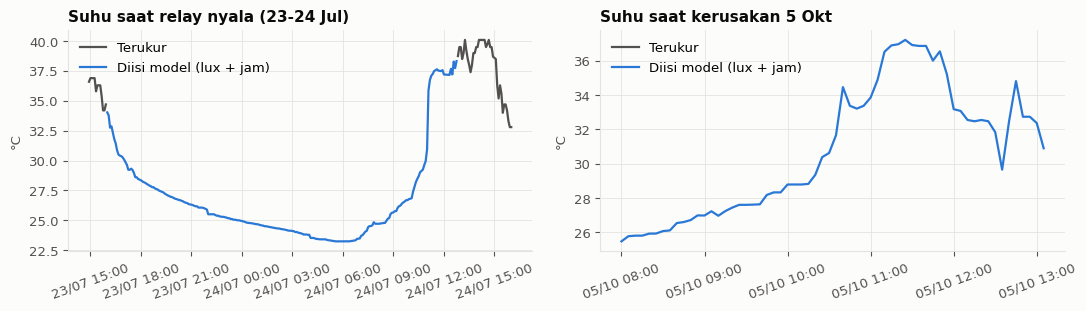

In [25]:
# Rekonstruksi dua kerusakan panjang yang benar-benar terjadi. Lux pada periode itu masih valid di df mentah.
mati = df[(df.temp == 0) & (df.hum == 0) & (df.lux > 0)].copy()
mati.index = pd.to_datetime(mati.tanggal + ' ' + mati.waktu, format='%d/%m/%Y %H:%M:%S', errors='coerce')
lux_mati = mati[mati.index.notna()].sort_index()['lux'].resample('5min').median().dropna()
isi = pd.DataFrame({'log_lux': np.log1p(lux_mati)}, index=lux_mati.index)
jd = isi.index.hour + isi.index.minute / 60
isi['jam_sin'], isi['jam_cos'] = np.sin(2 * np.pi * jd / 24), np.cos(2 * np.pi * jd / 24)
isi = isi[isi.index.isin(g.index[g.temp.isna()])]
langkah = pd.Timedelta(minutes=5)
blok_isi = (isi.index.to_series().diff() != langkah).cumsum()
for k in ('temp', 'hum'):
    isi[k] = model_vs[(k, ('log_lux',))].predict(isi[gap_fitur])
    for _, b in isi.groupby(blok_isi):
        kiri, kanan = b.index[0] - langkah, b.index[-1] + langkah
        if kiri in g.index and kanan in g.index and g.loc[[kiri, kanan], k].notna().all() and g.loc[[kiri, kanan], 'log_lux'].notna().all():
            tepi = model_vs[(k, ('log_lux',))].predict(g.loc[[kiri, kanan], gap_fitur])
            w = np.linspace(0, 1, len(b) + 2)[1:-1]
            isi.loc[b.index, k] += (g.loc[kiri, k] - tepi[0]) * (1 - w) + (g.loc[kanan, k] - tepi[1]) * w

data_final = g[['temp', 'hum', 'lux', 'vpd']].copy()
data_final['terisi_model'] = False
data_final.loc[isi.index, ['temp', 'hum']] = isi[['temp', 'hum']]
data_final.loc[isi.index, 'lux'] = np.expm1(isi['log_lux'])
data_final.loc[isi.index, 'terisi_model'] = True
data_final['vpd'] = 0.6108 * np.exp(17.27 * data_final.temp / (data_final.temp + 237.3)) * (1 - data_final.hum / 100)
print(f'Slot yang diisi model: {len(isi)} | slot terisi naik dari {g.temp.notna().mean():.1%} ke {data_final.temp.notna().mean():.1%}')

jendela = [('2026-07-23 12:00', '2026-07-24 16:00'), ('2026-10-05 06:00', '2026-10-05 15:00')]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, (m_, s_) in zip(ax, jendela):
    bagian = data_final.loc[m_:s_]
    a.plot(bagian.index, bagian.temp.where(~bagian.terisi_model), color=TINTA2, lw=1.6, label='Terukur')
    a.plot(bagian.index, bagian.temp.where(bagian.terisi_model), color=WARNA['temp'], lw=1.6, label='Diisi model (lux + jam)')
    a.set_ylabel('°C'); a.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M')); a.tick_params(axis='x', rotation=20); a.legend(loc='upper left')
ax[0].set_title('Suhu saat relay nyala (23-24 Jul)'); ax[1].set_title('Suhu saat kerusakan 5 Okt')
fig.tight_layout(); plt.show()

**Hasil.** Sebanyak 312 slot berhasil diisi, sehingga data terisi naik dari 87,4% menjadi 88,5%. Pada 23-24 Juli model memakai koreksi tepi. Pada 5 Oktober koreksi tepi tidak bisa dipakai karena kedua sisi celah juga kosong, jadi hasilnya lebih tidak pasti. Celah lain tidak bisa diisi karena seluruh perangkat mati dan `lux` pun tidak ada. Semua nilai isian ditandai `terisi_model` di `sensor_bersih_5menit.csv`.

## 9. Model B: memprediksi suhu dan kelembapan ke depan

Model ini menerima kondisi saat ini dan 2 jam terakhir, lalu memprediksi `temp` dan `hum` 1, 3, 6, dan 24 jam ke depan. Algoritmanya gradient boosting dengan jumlah pohon yang dipilih dari data validasi.

Skor model baru bermakna jika dibandingkan dengan tebakan sederhana. Tiga baseline dipakai:

- **Nilai tetap**: nilai sekarang akan bertahan.
- **Kemarin**: sama dengan nilai 24 jam sebelum waktu target.
- **Rata-rata jam**: rata-rata dari data train pada jam target.

In [26]:
HARI = 288

def buat_fitur(horizon):
    X = pd.DataFrame(index=g.index)
    for c in SENSOR:
        X[c] = g[c]
        for L in (1, 3, 6, 12, 24): X[f'{c}_beda_{L * 5}m'] = g[c] - g[c].shift(L)
        X[f'{c}_rata_1j'] = g[c].rolling(12, min_periods=8).mean()
        X[f'{c}_kemarin_saat_target'] = g[c].shift(HARI - horizon)
    jam_target = (g.index + pd.Timedelta(minutes=5 * horizon))
    jd = jam_target.hour + jam_target.minute / 60
    X['jam_sin'], X['jam_cos'] = g.jam_sin, g.jam_cos
    X['target_sin'], X['target_cos'] = np.sin(2 * np.pi * jd / 24), np.cos(2 * np.pi * jd / 24)
    return X

HORIZON = {'1 jam': 12, '3 jam': 36, '6 jam': 72, '24 jam': 288}
model_fc, riwayat_fc, hasil_fc, pred_fc = {}, {}, [], {}
for target in ('temp', 'hum'):
    for nama_h, hz in HORIZON.items():
        X = buat_fitur(hz); y = g[target].shift(-hz)
        ok = y.notna() & X[target].notna()
        tr, va, te = ok & is_train, ok & is_val, ok & is_test & X[f'{target}_kemarin_saat_target'].notna()
        m, riw = latih_gbr(X[tr], y[tr], X[va], y[va])
        p = m.predict(X[te]); q90 = np.quantile(np.abs(y[va] - m.predict(X[va])), .9)
        jam_tgt = (g.index[te] + pd.Timedelta(minutes=5 * hz)).hour
        rata_jam = g.loc[is_train, target].groupby(g.index.hour[is_train]).mean()
        base = {'Nilai tetap': X.loc[te, target], 'Kemarin': X.loc[te, f'{target}_kemarin_saat_target'], 'Rata-rata jam': jam_tgt.map(rata_jam)}
        mb = {n: metrik(y[te], b) for n, b in base.items()}
        terbaik_b = min(mb, key=lambda n: mb[n]['MAE'])
        mm = metrik(y[te], p)
        hasil_fc.append({'target': target, 'horizon': nama_h, 'n_test': int(te.sum()), 'pohon': m.max_iter, 'MAE': mm['MAE'], 'RMSE': mm['RMSE'], 'R2': mm['R2'],
                         'MAE nilai tetap': mb['Nilai tetap']['MAE'], 'MAE kemarin': mb['Kemarin']['MAE'], 'MAE rata2 jam': mb['Rata-rata jam']['MAE'],
                         'baseline terbaik': terbaik_b, 'perbaikan_vs_baseline_%': (1 - mm['MAE'] / mb[terbaik_b]['MAE']) * 100,
                         'interval_90_±': q90, 'cakupan_test_%': (np.abs(y[te] - p) <= q90).mean() * 100})
        model_fc[(target, nama_h)], riwayat_fc[(target, nama_h)] = m, riw
        pred_fc[(target, nama_h)] = pd.DataFrame({'aktual': y[te].to_numpy(), 'prediksi': p, 'q90': q90}, index=g.index[te] + pd.Timedelta(minutes=5 * hz))
hasil_fc = pd.DataFrame(hasil_fc).set_index(['target', 'horizon'])
display(hasil_fc.round(2))

n_test  pohon   MAE  RMSE    R2  MAE nilai tetap  MAE kemarin  MAE rata2 jam baseline terbaik  perbaikan_vs_baseline_%  interval_90_±  cakupan_test_%
target horizon                                                                                                                                                       
temp   1 jam      4614     50  0.99  1.53  0.92             1.50         1.33           1.82          Kemarin                    25.60           2.18           85.20
       3 jam      4614     45  1.18  1.75  0.89             3.76         1.33           1.82          Kemarin                    11.51           2.75           88.36
       6 jam      4614     45  1.35  2.04  0.85             6.29         1.33           1.82          Kemarin                    -1.80           2.93           87.17
       24 jam     4614     40  1.36  1.99  0.86             1.33         1.33           1.82      Nilai tetap                    -2.26           2.96           87.13
hum    1 jam      4614    150  2.53  3.69  0.95             3.85         7.45           8.24      Nilai tetap                    34.20           6.36           92.13
       3 jam      4614    300  4.40  6.13  0.86             9.87         7.45           8.24          Kemarin                    40.88          10.56           91.87
       6 jam      4614    365  5.93  7.92  0.77            17.14         7.45           8.24          Kemarin                    20.41          15.20           94.21
       24 jam     4614    100  7.04  9.21  0.69             7.45         7.45           8.24      Nilai tetap                     5.54          20.23           96.12

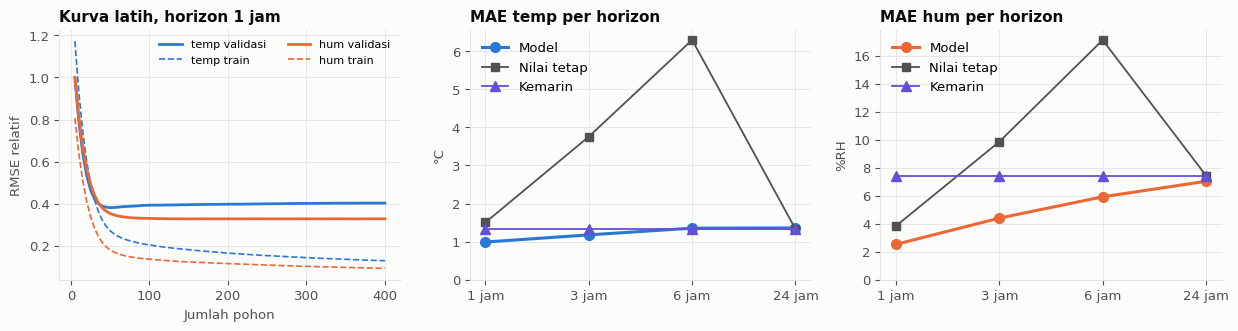

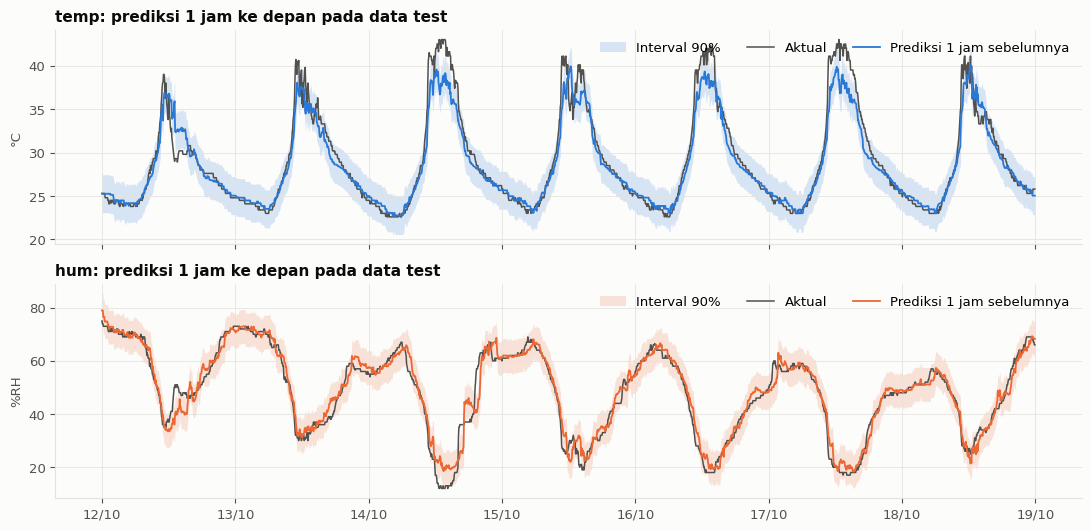

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
for k in ('temp', 'hum'):
    r = riwayat_fc[(k, '1 jam')]
    ax[0].plot(r.index, r.rmse_val / r.rmse_val.iloc[0], color=WARNA[k], lw=2, label=f'{k} validasi')
    ax[0].plot(r.index, r.rmse_train / r.rmse_val.iloc[0], color=WARNA[k], lw=1.2, ls='--', label=f'{k} train')
ax[0].set_title('Kurva latih, horizon 1 jam'); ax[0].set_xlabel('Jumlah pohon'); ax[0].set_ylabel('RMSE relatif'); ax[0].legend(ncol=2, fontsize=8)

hs = list(HORIZON)
for a, k, sat in [(ax[1], 'temp', '°C'), (ax[2], 'hum', '%RH')]:
    t = hasil_fc.loc[k]
    a.plot(hs, t['MAE'], color=WARNA[k], lw=2.2, marker='o', ms=7, label='Model')
    a.plot(hs, t['MAE nilai tetap'], color=TINTA2, lw=1.3, marker='s', ms=6, label='Nilai tetap')
    a.plot(hs, t['MAE kemarin'], color='#6250d6', lw=1.3, marker='^', ms=7, label='Kemarin')
    a.set_title(f'MAE {k} per horizon'); a.set_ylabel(sat); a.set_ylim(bottom=0); a.legend()
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
for a, k, sat in [(ax[0], 'temp', '°C'), (ax[1], 'hum', '%RH')]:
    q = pred_fc[(k, '1 jam')].loc['2026-10-12':'2026-10-18']
    a.fill_between(q.index, q.prediksi - q.q90, q.prediksi + q.q90, color=WARNA[k], alpha=.18, lw=0, label='Interval 90%')
    a.plot(q.index, q.aktual, color=TINTA2, lw=1.1, label='Aktual')
    a.plot(q.index, q.prediksi, color=WARNA[k], lw=1.3, label='Prediksi 1 jam sebelumnya')
    a.set_ylabel(sat); a.set_title(f'{k}: prediksi 1 jam ke depan pada data test'); a.legend(loc='upper right', ncol=3)
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m')); fig.tight_layout(); plt.show()

**Hasil.** Model memberi nilai nyata pada horizon pendek, dan tidak berguna untuk `temp` di horizon panjang.

| Target | 1 jam | 3 jam | 6 jam | 24 jam |
|---|---|---|---|---|
| `temp` MAE | 0,99 °C | 1,18 °C | 1,35 °C | 1,36 °C |
| Perbaikan vs baseline terbaik | +25,6% | +11,5% | -1,8% | -2,3% |
| `hum` MAE | 2,53 %RH | 4,40 %RH | 5,93 %RH | 7,04 %RH |
| Perbaikan vs baseline terbaik | +34,2% | +40,9% | +20,4% | +5,5% |

- Untuk `temp` 6 dan 24 jam ke depan, tebakan "sama seperti kemarin" sudah setara dengan model, sehingga model tidak layak dipakai untuk horizon itu.
- `hum` lebih layak diprediksi sampai 6 jam, karena kelembapan lebih dipengaruhi kondisi terbaru.
- Interval 90% untuk `temp` hanya mencakup 85-88% data test, jadi sedikit terlalu sempit. Untuk `hum` cakupannya 92-96%.
- Boosting memilih sedikit pohon untuk `temp` (40-50), dan kurva validasi berhenti membaik lebih awal. Menambah kompleksitas tidak membantu.

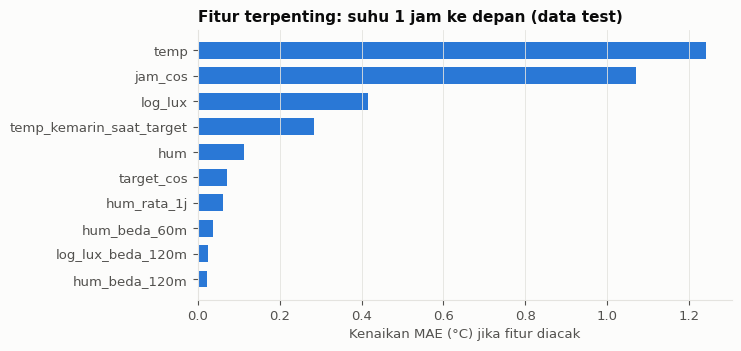

In [28]:
X = buat_fitur(12); y = g['temp'].shift(-12)
ok = y.notna() & X['temp'].notna() & is_test
pi = permutation_importance(model_fc[('temp', '1 jam')], X[ok], y[ok], scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(10)
fig, a = plt.subplots(figsize=(7.5, 3.6))
a.barh(imp.index, imp.values, color=WARNA['temp'], height=.66); a.set_xlabel('Kenaikan MAE (°C) jika fitur diacak')
a.set_title('Fitur terpenting: suhu 1 jam ke depan (data test)'); a.grid(axis='y', visible=False); fig.tight_layout(); plt.show()

**Hasil.** Fitur terpenting adalah suhu saat ini dan jam, disusul cahaya serta suhu kemarin pada jam target. Ini masuk akal secara fisik, dan sekaligus menegaskan betapa kuat pola harian di lokasi ini.

## 10. Model C: alarm panas 60 menit sebelum terjadi

Model ini menjawab pertanyaan ya/tidak, sehingga punya nilai akurasi: **saat ini suhu masih di bawah ambang, apakah dalam 60 menit ke depan suhu menyentuh ambang?** Baris yang sudah panas dikeluarkan, supaya model tidak mendapat nilai mudah dari kondisi yang sudah terjadi.

Kelas positif jarang, jadi accuracy saja bisa menipu. Hasil ditampilkan bersama precision, recall, F1, dan pembanding sederhana. Ambang probabilitas dipilih dari data validasi.

In [29]:
from sklearn.metrics import log_loss
PARAM_ALARM = dict(learning_rate=.05, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1., early_stopping=False, random_state=SEED)

def siapkan_alarm(ambang):
    masa_depan = pd.concat([g.temp.shift(-k) for k in range(1, 13)], axis=1)
    label = (masa_depan.max(axis=1) >= ambang).astype(float).where(masa_depan.notna().sum(axis=1) >= 10)
    X = buat_fitur(12)
    ok = label.notna() & X.temp.notna() & (X.temp < ambang)
    return X, label, ok

def laporan(y, pred, skor=None):
    r = {'accuracy': accuracy_score(y, pred), 'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred), 'F1': f1_score(y, pred)}
    if skor is not None: r.update({'ROC-AUC': roc_auc_score(y, skor), 'PR-AUC': average_precision_score(y, skor)})
    return r

def latih_alarm(ambang):
    X, label, ok = siapkan_alarm(ambang)
    tr, va, te = ok & is_train, ok & is_val, ok & is_test
    m = HistGradientBoostingClassifier(max_iter=400, **PARAM_ALARM).fit(X[tr], label[tr])
    riw = pd.DataFrame({'logloss_train': [log_loss(label[tr], p) for i, p in enumerate(m.staged_predict_proba(X[tr]), 1) if i % 5 == 0],
                        'logloss_val': [log_loss(label[va], p) for i, p in enumerate(m.staged_predict_proba(X[va]), 1) if i % 5 == 0]}, index=range(5, 401, 5))
    m = HistGradientBoostingClassifier(max_iter=int(riw.logloss_val.idxmin()), **PARAM_ALARM).fit(X[tr], label[tr])
    p_val = m.predict_proba(X[va])[:, 1]
    kisi = np.arange(.05, .91, .05)
    batas = float(kisi[np.argmax([f1_score(label[va], p_val >= q) for q in kisi])])
    p_te = m.predict_proba(X[te])[:, 1]
    jam_d = pd.Series(g.index.hour + g.index.minute / 60, index=g.index)
    # Pembanding terbaik dicari pada validasi, baru diuji pada test
    kisi_jam = [(a, a + b) for a in np.arange(8, 13.5, .5) for b in (.5, 1, 1.5, 2, 3)]
    a_, b_ = max(kisi_jam, key=lambda w: f1_score(label[va], jam_d[va].between(*w, inclusive='left')))
    off = max(np.arange(.5, 8.5, .5), key=lambda o: f1_score(label[va], X.temp[va] >= ambang - o))
    tabel = {'Model': laporan(label[te], p_te >= batas, p_te), 'Selalu "tidak panas"': laporan(label[te], np.zeros(te.sum())),
             f'Jadwal jam {a_:g}-{b_:g}': laporan(label[te], jam_d[te].between(a_, b_, inclusive='left')),
             f'Aturan suhu ≥ {ambang - off:g} °C': laporan(label[te], X.temp[te] >= ambang - off)}
    return {'model': m, 'riwayat': riw, 'batas': batas, 'y': label[te], 'p': pd.Series(p_te, index=g.index[te]), 'tabel': pd.DataFrame(tabel).T,
            'val': laporan(label[va], p_val >= batas, p_val), 'proporsi': (label[te].mean(), int(te.sum()))}

alarm35, alarm32 = latih_alarm(35.), latih_alarm(32.)
print(f'Ambang 35 °C | baris test {alarm35["proporsi"][1]:,} | kelas positif {alarm35["proporsi"][0]:.1%} | batas probabilitas {alarm35["batas"]:.2f} | pohon {alarm35["model"].max_iter}')
display(alarm35['tabel'].round(3))
print(f'Ambang 32 °C | baris test {alarm32["proporsi"][1]:,} | kelas positif {alarm32["proporsi"][0]:.1%} | batas probabilitas {alarm32["batas"]:.2f}')
display(alarm32['tabel'].round(3))
print('Skor model pada validasi (35 °C):', {k: round(v, 3) for k, v in alarm35['val'].items()})

# Latih ulang dengan train + validasi supaya model mengenal posisi matahari yang lebih baru
X_al, label_al, ok_al = siapkan_alarm(35.)
tv, te_al = ok_al & (is_train | is_val), ok_al & is_test
model_ulang = HistGradientBoostingClassifier(max_iter=alarm35['model'].max_iter, **PARAM_ALARM).fit(X_al[tv], label_al[tv])
p_ulang = pd.Series(model_ulang.predict_proba(X_al[te_al])[:, 1], index=g.index[te_al])
alarm35['tabel'].loc['Model dilatih ulang (train+val)'] = laporan(label_al[te_al], p_ulang >= alarm35['batas'], p_ulang)
display(alarm35['tabel'].loc[['Model', 'Model dilatih ulang (train+val)']].round(3))

Ambang 35 °C | baris test 4,183 | kelas positif 6.6% | batas probabilitas 0.50 | pohon 100


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Model,0.959,0.686,0.688,0.687,0.983,0.775
"Selalu ""tidak panas""",0.934,0.000,0.000,0.000,NaN,NaN
Jadwal jam 10-13,0.955,0.713,0.540,0.614,NaN,NaN
Aturan suhu ≥ 31 °C,0.877,0.303,0.670,0.418,NaN,NaN


Ambang 32 °C | baris test 3,708 | kelas positif 6.0% | batas probabilitas 0.25


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Model,0.979,0.798,0.869,0.832,0.992,0.854
"Selalu ""tidak panas""",0.940,0.000,0.000,0.000,NaN,NaN
Jadwal jam 9.5-11,0.979,0.974,0.662,0.788,NaN,NaN
Aturan suhu ≥ 28.5 °C,0.824,0.251,0.977,0.400,NaN,NaN


Skor model pada validasi (35 °C): {'accuracy': 0.978, 'precision': 0.844, 'recall': 0.889, 'F1': 0.866, 'ROC-AUC': 0.994, 'PR-AUC': 0.942}


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Model,0.959,0.686,0.688,0.687,0.983,0.775
Model dilatih ulang (train+val),0.967,0.750,0.739,0.745,0.985,0.823


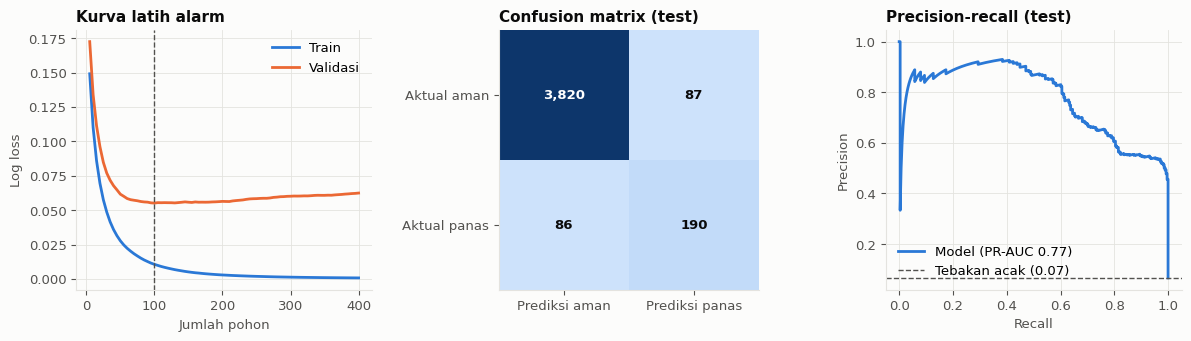

In [30]:
y, p = alarm35['y'], alarm35['p'].to_numpy()
cm = confusion_matrix(y, p >= alarm35['batas'])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
r = alarm35['riwayat']
ax[0].plot(r.index, r.logloss_train, color=WARNA['temp'], lw=2, label='Train'); ax[0].plot(r.index, r.logloss_val, color=WARNA['hum'], lw=2, label='Validasi')
ax[0].axvline(r.logloss_val.idxmin(), color=TINTA2, ls='--', lw=1); ax[0].set_title('Kurva latih alarm'); ax[0].set_xlabel('Jumlah pohon'); ax[0].set_ylabel('Log loss'); ax[0].legend()
ax[1].imshow(cm, cmap=BIRU_SEQ); ax[1].grid(False); ax[1].set_title('Confusion matrix (test)')
ax[1].set_xticks([0, 1], ['Prediksi aman', 'Prediksi panas']); ax[1].set_yticks([0, 1], ['Aktual aman', 'Aktual panas'])
for i in range(2):
    for j in range(2): ax[1].text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else TINTA, fontweight='bold')
pr, rc, _ = precision_recall_curve(y, p)
ax[2].plot(rc, pr, color=WARNA['temp'], lw=2, label=f'Model (PR-AUC {average_precision_score(y, p):.2f})')
ax[2].axhline(y.mean(), color=TINTA2, ls='--', lw=1, label=f'Tebakan acak ({y.mean():.2f})')
ax[2].set_title('Precision-recall (test)'); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].legend(loc='lower left')
fig.tight_layout(); plt.show()

**Hasil.** Accuracy model 95,9%. Angka itu terlihat tinggi, tetapi tebakan "tidak pernah panas" sudah mencapai 93,4% tanpa mendeteksi apa pun. Ukuran yang lebih jujur:

| Ambang 35 °C | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Model | 95,9% | 0,686 | 0,688 | 0,687 |
| Model dilatih ulang (train + validasi) | 96,7% | 0,750 | 0,739 | 0,745 |
| Jadwal terbaik dari validasi | 95,5% | 0,713 | 0,540 | 0,614 |

- F1 turun dari 0,866 di validasi menjadi 0,687 di test. Penyebab yang paling mungkin adalah pergeseran jam mulai panas (bagian 6.4).
- Melatih ulang dengan data yang lebih baru menaikkan F1 menjadi 0,745, sehingga model perlu diperbarui secara berkala.
- Pada ambang 32 °C, F1 model 0,832 dibanding 0,788 untuk jadwal.

**Cara membaca confusion matrix pada ambang 35 °C.** Dari 4.183 baris test:

| | Prediksi aman | Prediksi panas |
|---|---|---|
| **Aktual aman** | 3.820 benar | 87 alarm palsu |
| **Aktual panas** | 86 terlewat | 190 benar |

- Accuracy = (3.820 + 190) / 4.183 = 95,9%.
- Precision = 190 / (190 + 87) = 0,686. Dari semua prediksi panas, 68,6% benar.
- Recall = 190 / (190 + 86) = 0,688. Dari semua kejadian panas, 68,8% tertangkap.

**Konfigurasi latihan.** Model memakai gradient boosting dengan learning rate 0,05. Jumlah pohon terbaik adalah 100, dipilih dari log loss validasi terendah. Setelah itu log loss validasi naik lagi walau log loss train terus turun, yang merupakan tanda overfitting. Batas probabilitas alarm adalah 0,50, dipilih dari F1 terbaik pada validasi.

### 10.1 Evaluasi per kejadian

Petani tidak merespons baris data, melainkan kejadian. Karena itu baris digabung menjadi **episode panas** (jeda ≤ 60 menit dianggap satu episode) dan **alarm** (jeda ≤ 60 menit dianggap satu alarm). Alarm dianggap benar jika episode panas dimulai dalam 2 jam setelah alarm.

Karena panas terjadi hampir setiap hari pada jam yang bisa ditebak, model harus dibandingkan dengan aturan tanpa machine learning:

- **Jadwal tetap**: satu alarm setiap hari pada jam yang sama.
- **Jadwal adaptif**: satu alarm setiap hari, 30 menit sebelum median jam mulai panas pada 7 hari data terakhir.

Inilah pertanyaan nilai yang jujur: apakah model lebih berguna daripada aturan sederhana?

In [31]:
def kelompok(waktu, jeda='60min'):
    w = pd.DatetimeIndex(waktu).sort_values()
    if len(w) == 0: return []
    return list(w[np.r_[True, np.diff(w) > pd.Timedelta(jeda)]])

def nilai_kejadian(alarm, episode, jendela=pd.Timedelta('120min')):
    terdeteksi, lead, salah = 0, [], 0
    for e in episode:
        cocok = [a for a in alarm if e - jendela <= a <= e]
        if cocok: terdeteksi += 1; lead.append((e - min(cocok)).total_seconds() / 60)
    for a in alarm:
        if not any(a <= e <= a + jendela for e in episode): salah += 1
    return {'episode_panas': len(episode), 'terdeteksi': terdeteksi, 'terlewat': len(episode) - terdeteksi, 'alarm_total': len(alarm),
            'alarm_palsu': salah, 'recall_episode': terdeteksi / max(len(episode), 1), 'precision_alarm': 1 - salah / max(len(alarm), 1),
            'median_jeda_menit': float(np.median(lead)) if lead else np.nan}

panas_test = g.index[is_test & (g.temp >= 35)]
episode = kelompok(panas_test)
alarm_model = kelompok(alarm35['p'].index[alarm35['p'] >= alarm35['batas']])
hari_test = pd.DatetimeIndex(sorted(set(g.index[is_test & g.temp.notna()].normalize())))

alarm_ulang = kelompok(p_ulang.index[p_ulang >= alarm35['batas']])

def alarm_harian(menit): return [d + pd.Timedelta(minutes=float(menit)) for d in hari_test]
median_train = jam_mulai[:AKHIR_TRAIN].median() * 60
alarm_adaptif = []
for d in hari_test:
    tujuh_terakhir = jam_mulai[jam_mulai.index < d].tail(7)
    alarm_adaptif.append(d + pd.Timedelta(hours=tujuh_terakhir.median()) - pd.Timedelta(minutes=30))

hasil_kejadian = pd.DataFrame({
    'Model': nilai_kejadian(alarm_model, episode), 'Model dilatih ulang': nilai_kejadian(alarm_ulang, episode),
    'Jadwal adaptif (7 hari)': nilai_kejadian(alarm_adaptif, episode),
    f'Jadwal tetap {int((median_train - 30) // 60):02d}:{int((median_train - 30) % 60):02d} (dari train)': nilai_kejadian(alarm_harian(median_train - 30), episode),
    'Jadwal tetap 10:00': nilai_kejadian(alarm_harian(600), episode), 'Jadwal tetap 09:30': nilai_kejadian(alarm_harian(570), episode)}).T
print(f'Hari test: {len(hari_test)} | hari dengan panas: {len(set(e.normalize() for e in episode))}')
display(hasil_kejadian.round(2))

Hari test: 18 | hari dengan panas: 17


,episode_panas,terdeteksi,terlewat,alarm_total,alarm_palsu,recall_episode,precision_alarm,median_jeda_menit
Model,19.0,18.0,1.0,26.0,8.0,0.95,0.69,45.0
Model dilatih ulang,19.0,18.0,1.0,29.0,11.0,0.95,0.62,47.5
Jadwal adaptif (7 hari),19.0,16.0,3.0,18.0,2.0,0.84,0.89,25.0
Jadwal tetap 10:35 (dari train),19.0,9.0,10.0,18.0,9.0,0.47,0.50,0.0
Jadwal tetap 10:00,19.0,16.0,3.0,18.0,2.0,0.84,0.89,35.0
Jadwal tetap 09:30,19.0,16.0,3.0,18.0,2.0,0.84,0.89,65.0


**Hasil.** Inilah perbandingan yang paling menentukan nilai model.

- **Model** menangkap 18 dari 19 episode, dengan 8 alarm palsu dan jeda median 45 menit.
- **Jadwal adaptif tanpa ML** menangkap 16 dari 19 episode, dengan hanya 2 alarm palsu.
- **Jadwal tetap dari data train** hanya menangkap 9 dari 19, karena jam mulai panas sudah bergeser lebih awal.
- Melatih ulang tidak mengurangi alarm palsu per kejadian (11 alarm palsu), walau F1 per baris naik.

Panas terjadi pada 17 dari 18 hari test, jadi pertanyaan "apakah akan panas?" hampir selalu dijawab "ya". Selama pola ini bertahan, aturan sederhana sudah sangat kompetitif. Model menangkap 2 episode tambahan, tetapi dengan 6 alarm palsu tambahan. Dengan hanya 19 episode, selisih ini juga belum cukup untuk menyatakan salah satu lebih baik secara pasti.

## 11. Simulasi deteksi sensor rusak

Model yang sama dapat dipakai sebagai pengawas. Prediksi `temp` dari `hum`, `lux`, dan jam dibandingkan dengan pembacaan `temp`. Jika median selisihnya selama 1 jam melewati batas, sistem memberi peringatan. Batas awal diambil dari persentil 99,9 selisih pada data validasi, lalu beberapa batas lain dibandingkan.

Pada data test, kerusakan buatan disuntikkan pada `temp` selama 6 jam: nilai beku dan pergeseran ±3, ±5, ±8 °C. Setiap jenis diuji 200 kali. Pembacaan nol tidak diuji karena mudah dideteksi dengan aturan sederhana.

In [32]:
pengawas = model_vs[('temp', ('hum', 'log_lux'))]
Fp = ['hum', 'log_lux'] + JAM
def residu(mask):
    r = pd.Series(np.nan, index=g.index)
    ok = mask & g[Fp].notna().all(axis=1).to_numpy() & g.temp.notna().to_numpy()
    r[ok] = g.loc[ok, 'temp'] - pengawas.predict(g.loc[ok, Fp])
    return r

BATAS_VAL = float(residu(is_val).rolling(12, min_periods=8).median().abs().quantile(.999))
r_test = residu(is_test)
rm_bersih = r_test.rolling(12, min_periods=8).median()
L = 72
posisi = np.flatnonzero(r_test.notna().to_numpy() & is_test)
posisi = posisi[(posisi > 24) & (posisi < len(g) - L - 1)]

def uji_batas(batas, n=200):
    rs = np.random.RandomState(SEED)
    kandidat = [s for s in posisi if r_test.iloc[s:s + L].notna().mean() > .95 and rm_bersih.iloc[s - 1:s + L].abs().max() <= batas]
    hasil = {'batas_°C': batas, 'peringatan_palsu_per_hari': len(kelompok(rm_bersih.index[rm_bersih.abs() > batas])) / len(hari_test)}
    for nama, bias in [('Nilai beku', None), ('Geser ±3', 3), ('Geser ±5', 5), ('Geser ±8', 8)]:
        tunda = []
        for s in rs.choice(kandidat, n):
            r = r_test.iloc[s - 11:s + L].to_numpy().copy()
            if bias is None:
                pred = g.temp.iloc[s - 11:s + L].to_numpy() - r
                r[11:] = g.temp.iloc[s - 1] - pred[11:]
            else:
                r[11:] += bias * rs.choice([-1, 1])
            rm = pd.Series(r).rolling(12, min_periods=8).median().to_numpy()[11:]
            hit = np.flatnonzero(np.abs(rm) > batas)
            tunda.append(hit[0] * 5 if len(hit) else np.nan)
        tunda = np.array(tunda, float)
        hasil[f'{nama} terdeteksi_%'] = np.isfinite(tunda).mean() * 100
        hasil[f'{nama} tunda_menit'] = np.nanmedian(tunda) if np.isfinite(tunda).any() else np.nan
    return hasil

hasil_fault = pd.DataFrame([uji_batas(b) for b in (BATAS_VAL, 3.5, 4.5, 6.)]).set_index('batas_°C')
display(hasil_fault.round(1).T)

batas_°C,2.736655,3.500000,4.500000,6.000000
peringatan_palsu_per_hari,1.1,0.1,0.0,0.0
Nilai beku terdeteksi_%,61.5,67.0,55.5,43.0
Nilai beku tunda_menit,150.0,150.0,170.0,185.0
Geser ±3 terdeteksi_%,82.0,45.5,24.5,8.0
Geser ±3 tunda_menit,30.0,40.0,45.0,95.0
Geser ±5 terdeteksi_%,100.0,96.5,82.5,34.5
Geser ±5 tunda_menit,30.0,30.0,30.0,60.0
Geser ±8 terdeteksi_%,100.0,100.0,100.0,97.5
Geser ±8 tunda_menit,25.0,25.0,30.0,30.0


**Hasil.** Batas dari validasi (2,74 °C) terlalu sensitif untuk data test, dengan sekitar 1,1 peringatan palsu per hari. Batas **3,5 °C** memberi keseimbangan terbaik: sekitar 0,1 peringatan palsu per hari, mendeteksi 96,5% pergeseran ±5 °C dan 100% pergeseran ±8 °C dalam sekitar 30 menit.

Keterbatasannya perlu dicatat. Pergeseran ±3 °C hanya terdeteksi 45,5%, dan nilai beku hanya 67% dengan tunda sekitar 150 menit, karena nilai beku sering masih dekat dengan prediksi pada awalnya. Batas 3,5 °C juga dipilih setelah melihat data test, jadi hasil ini sedikit optimistis dan perlu diuji ulang pada data baru.

## 12. Simulasi penggunaan dalam satu hari

Skenario ini memutar ulang satu hari data test seolah sistem berjalan langsung, dengan dua kejadian: alarm panas sebelum suhu naik, dan sensor suhu-kelembapan mati pada 09:00-15:00. Model hanya memakai data yang sudah tersedia pada waktu itu.

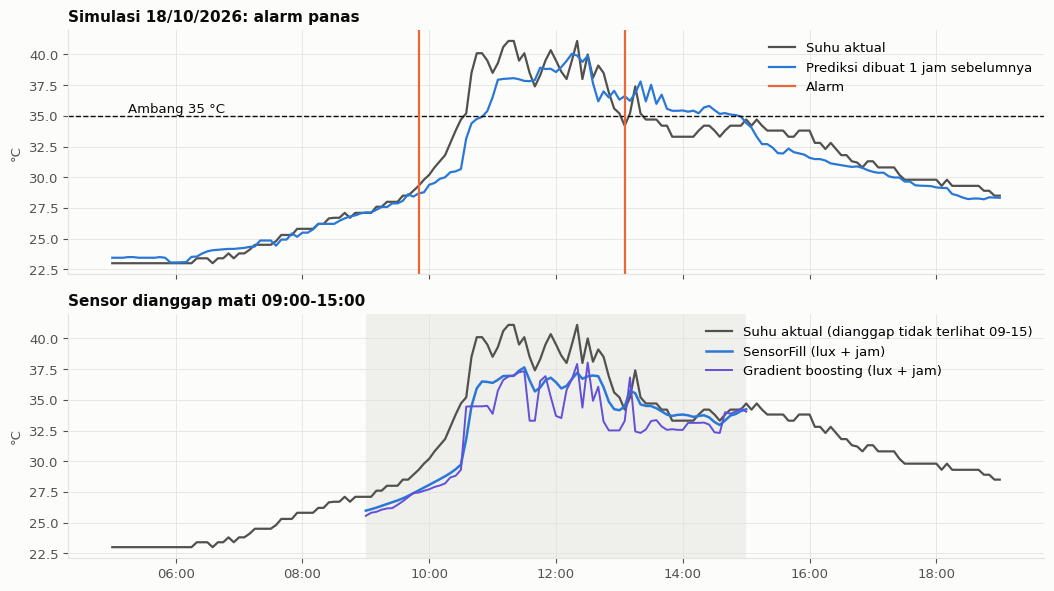

Alarm: 09:50, 13:05 | Panas dimulai: 10:35
MAE saat sensor mati: SensorFill 1.81 °C | Gradient boosting 2.55 °C


In [33]:
terdeteksi_hari = [e for e in episode if any(e - pd.Timedelta('120min') <= a <= e for a in alarm_model) and e.normalize() in set(p_net_lux.dropna(subset=['temp']).index.normalize())]
hari = terdeteksi_hari[len(terdeteksi_hari) // 2].normalize()
sehari = slice(hari + pd.Timedelta(hours=5), hari + pd.Timedelta(hours=19))
fc = pred_fc[('temp', '1 jam')].loc[sehari]
aktual = g.temp.loc[sehari]
alarm_hari = [a for a in alarm_model if a.normalize() == hari]
epi_hari = [e for e in episode if e.normalize() == hari]

fig, ax = plt.subplots(2, 1, figsize=(10.5, 6), sharex=True)
ax[0].plot(aktual.index, aktual, color=TINTA2, lw=1.6, label='Suhu aktual')
ax[0].plot(fc.index, fc.prediksi, color=WARNA['temp'], lw=1.6, label='Prediksi dibuat 1 jam sebelumnya')
ax[0].axhline(35, color=TINTA, ls='--', lw=1); ax[0].text(aktual.index[3], 35.3, 'Ambang 35 °C', color=TINTA)
for a in alarm_hari: ax[0].axvline(a, color=WARNA['hum'], lw=1.6, label='Alarm')
ax[0].set_title(f'Simulasi {hari:%d/%m/%Y}: alarm panas'); ax[0].set_ylabel('°C')
tangan, label_ = ax[0].get_legend_handles_labels(); unik = dict(zip(label_, tangan)); ax[0].legend(unik.values(), unik.keys(), loc='upper right')

mati_awal, mati_akhir = hari + pd.Timedelta(hours=9), hari + pd.Timedelta(hours=15)
isi_hari = p_net_lux.loc[mati_awal:mati_akhir, 'temp']; gb_hari = p_gbr_lux['temp'].loc[mati_awal:mati_akhir]
ax[1].plot(aktual.index, aktual, color=TINTA2, lw=1.6, label='Suhu aktual (dianggap tidak terlihat 09-15)')
ax[1].plot(isi_hari.index, isi_hari, color=WARNA['temp'], lw=1.8, label='SensorFill (lux + jam)')
ax[1].plot(gb_hari.index, gb_hari, color='#6250d6', lw=1.4, label='Gradient boosting (lux + jam)')
ax[1].axvspan(mati_awal, mati_akhir, color=GRID, alpha=.5, lw=0)
ax[1].set_title('Sensor dianggap mati 09:00-15:00'); ax[1].set_ylabel('°C'); ax[1].legend(loc='upper right')
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M')); fig.tight_layout(); plt.show()

alarm_txt = ', '.join(f'{a:%H:%M}' for a in alarm_hari) or '-'
epi_txt = ', '.join(f'{e:%H:%M}' for e in epi_hari) or '-'
print('Alarm:', alarm_txt, '| Panas dimulai:', epi_txt)
print(f'MAE saat sensor mati: SensorFill {mean_absolute_error(aktual.loc[isi_hari.index], isi_hari):.2f} °C | Gradient boosting {mean_absolute_error(aktual.loc[gb_hari.index], gb_hari):.2f} °C')

**Hasil.** Pada hari simulasi, alarm berbunyi pukul 09:50, 45 menit sebelum suhu menyentuh 35 °C pada 10:35. Alarm 13:05 terhitung palsu, karena saat itu episode panas sudah berjalan dan suhu hanya turun sebentar. Saat sensor dianggap mati, `SensorFill` memperkirakan suhu dengan MAE 1,81 °C, lebih baik dari gradient boosting (2,55 °C) yang kurvanya lebih patah-patah. Ini satu hari contoh, sedangkan perbandingan menyeluruh ada di bagian 8.

## 13. Nilai data dan simulasi ekonomi

### 13.1 Dataset ini dalam kerangka 5V

In [34]:
ukuran_mb = Path('sensor_log.csv').stat().st_size / 1e6
n_hari = (data.index.max() - data.index.min()).total_seconds() / 86400
mb_tahun = ukuran_mb / n_hari * 365
terpakai = len(data) / len(df)
display(pd.DataFrame([
    ('Volume', f'{len(df):,} baris, {ukuran_mb:.1f} MB dalam {n_hari:.0f} hari', f'Skala kecil. 1 node ±{mb_tahun:.0f} MB/tahun; 1.000 node ±{mb_tahun * 1000 / 1000:.0f} GB/tahun'),
    ('Velocity', f'1 baris per ±61 detik (±{86400 / 61:,.0f} baris/hari)', f'Aliran terus-menerus. 1.000 node ±{1000 / 61:.0f} baris/detik'),
    ('Variety', '13 kolom: numerik, biner, waktu, kategorikal', 'Satu sumber dan terstruktur, sehingga variety rendah'),
    ('Veracity', f'{terpakai:.1%} baris lolos df_clean; 3 dari 6 kanal sensor dibuang', 'Tantangan terbesar dataset ini'),
    ('Value', 'Lihat hasil model dan simulasi berikut', 'Nilai datang dari keputusan, bukan dari data mentah'),
], columns=['Dimensi', 'Kondisi dataset', 'Penilaian']).set_index('Dimensi'))

,Kondisi dataset,Penilaian
Dimensi,,
Volume,"118,572 baris, 9.8 MB dalam 95 hari",Skala kecil. 1 node ±38 MB/tahun; 1.000 node ±...
Velocity,"1 baris per ±61 detik (±1,416 baris/hari)",Aliran terus-menerus. 1.000 node ±16 baris/detik
Variety,"13 kolom: numerik, biner, waktu, kategorikal","Satu sumber dan terstruktur, sehingga variety ..."
Veracity,98.7% baris lolos df_clean; 3 dari 6 kanal sen...,Tantangan terbesar dataset ini
Value,Lihat hasil model dan simulasi berikut,"Nilai datang dari keputusan, bukan dari data m..."


**Hasil.** Secara ukuran, dataset ini belum termasuk big data: hanya 9,8 MB dari satu sensor. Yang relevan dengan konsep big data adalah alirannya yang terus-menerus dan masalah veracity-nya. Pipeline yang sama bisa diterapkan bila jumlah node bertambah, misalnya 1.000 node menghasilkan sekitar 38 GB per tahun dan sekitar 16 baris per detik. Dimensi yang paling menentukan di sini adalah veracity, karena 3 dari 6 kanal sensor tidak bisa dipakai.

### 13.2 Perkiraan nilai ekonomi

Dataset ini tidak memiliki data panen, harga, atau biaya. Karena itu **semua nilai rupiah di bawah adalah asumsi contoh, bukan hasil pengukuran**. Yang berasal dari data hanyalah jumlah episode, alarm benar, dan alarm palsu pada data test. Silakan ganti `ASUMSI` sesuai kondisi lapangan.

Rumus: `nilai per hari = (episode tertangani × efektivitas × manfaat per episode − alarm palsu × biaya alarm palsu) / jumlah hari`.

,episode_tertangani,alarm_palsu,nilai_per_hari_rp,nilai_per_tahun_rp,balik_modal_hari
Model,18.0,8.0,22778.0,8313889.0,66.0
Model dilatih ulang,18.0,11.0,21944.0,8009722.0,68.0
Jadwal adaptif (7 hari),16.0,2.0,21667.0,7908333.0,69.0
Jadwal tetap 10:35 (dari train),9.0,9.0,10000.0,3650000.0,150.0
Jadwal tetap 10:00,16.0,2.0,21667.0,7908333.0,69.0
Jadwal tetap 09:30,16.0,2.0,21667.0,7908333.0,69.0


Selisih nilai model dilatih ulang dibanding jadwal adaptif: Rp 278 per hari (dengan asumsi di atas)


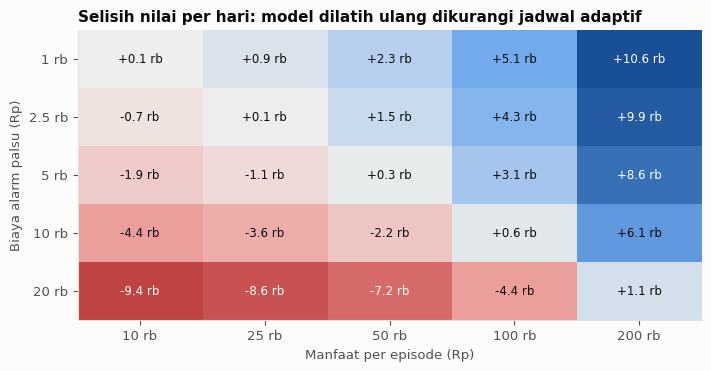

In [35]:
ASUMSI = {'manfaat_per_episode_rp': 50_000,   # kerugian yang terhindar saat satu episode panas ditangani
          'biaya_alarm_palsu_rp': 5_000,      # listrik/tenaga untuk respons yang tidak diperlukan
          'efektivitas_respons': .5,          # peluang respons benar-benar mencegah kerugian
          'biaya_alat_rp': 1_500_000}         # sensor, pengendali, dan pemasangan

def nilai_harian(hasil, a=ASUMSI):
    return (hasil['terdeteksi'] * a['efektivitas_respons'] * a['manfaat_per_episode_rp'] - hasil['alarm_palsu'] * a['biaya_alarm_palsu_rp']) / len(hari_test)

nilai = pd.DataFrame({n: {'episode_tertangani': r.terdeteksi, 'alarm_palsu': r.alarm_palsu, 'nilai_per_hari_rp': nilai_harian(r), 'nilai_per_tahun_rp': nilai_harian(r) * 365,
                          'balik_modal_hari': ASUMSI['biaya_alat_rp'] / nilai_harian(r) if nilai_harian(r) > 0 else np.nan} for n, r in hasil_kejadian.iterrows()}).T
display(nilai.round(0))
PEMBANDING = 'Jadwal adaptif (7 hari)'
tambahan = nilai.loc['Model dilatih ulang', 'nilai_per_hari_rp'] - nilai.loc[PEMBANDING, 'nilai_per_hari_rp']
print(f'Selisih nilai model dilatih ulang dibanding jadwal adaptif: Rp {tambahan:,.0f} per hari (dengan asumsi di atas)')

manfaat = np.array([10, 25, 50, 100, 200]) * 1000
biaya = np.array([1, 2.5, 5, 10, 20]) * 1000
kisi = np.array([[ (nilai_harian(hasil_kejadian.loc['Model dilatih ulang'], {**ASUMSI, 'manfaat_per_episode_rp': b, 'biaya_alarm_palsu_rp': c})
                    - nilai_harian(hasil_kejadian.loc[PEMBANDING], {**ASUMSI, 'manfaat_per_episode_rp': b, 'biaya_alarm_palsu_rp': c})) for b in manfaat] for c in biaya])
batas_warna = max(np.abs(kisi).max(), 1)
fig, a = plt.subplots(figsize=(7.2, 3.8))
im = a.imshow(kisi, cmap=DIVERGEN.reversed(), norm=TwoSlopeNorm(0, -batas_warna, batas_warna), aspect='auto'); a.grid(False)
a.set_xticks(range(5), [f'{v // 1000:.0f} rb' for v in manfaat]); a.set_yticks(range(5), [f'{v / 1000:g} rb' for v in biaya])
a.set_xlabel('Manfaat per episode (Rp)'); a.set_ylabel('Biaya alarm palsu (Rp)'); a.set_title('Selisih nilai per hari: model dilatih ulang dikurangi jadwal adaptif')
for i in range(5):
    for j in range(5): a.text(j, i, f'{kisi[i, j] / 1000:+.1f} rb', ha='center', va='center', color='white' if abs(kisi[i, j]) > batas_warna * .6 else TINTA, fontsize=8.5)
fig.tight_layout(); plt.show()

**Hasil.** Dengan asumsi contoh, nilai model, model dilatih ulang, dan jadwal adaptif hampir sama, yaitu sekitar Rp 22 ribu per hari. Selisih model dilatih ulang dengan jadwal adaptif hanya Rp 278 per hari.

Peta di atas menunjukkan kapan model unggul: **model lebih bernilai jika satu episode panas mahal dan alarm palsu murah**. Jika alarm palsu mahal, jadwal adaptif lebih baik. Jadi nilai model alarm belum terbukti, dan keputusan akhirnya bergantung pada biaya nyata di lapangan.

### 13.3 Nilai data per industri

Penilaian berikut adalah pertimbangan analis berdasarkan hasil notebook ini, bukan pengukuran pasar. Karena `soil` dan `tds` tidak dipakai, dataset ini tidak bisa mendukung keputusan penyiraman atau nutrisi.

| Industri | Nilai saat ini | Kegunaan yang didukung hasil | Yang masih kurang |
|---|---|---|---|
| Vendor IoT dan perawatan perangkat | Tinggi | Pola kerusakan nyata (RTC, relay, kabel), deteksi sensor rusak, sensor virtual | Catatan perbaikan dan versi perangkat keras |
| Riset dan pendidikan | Tinggi | Contoh nyata data kotor, kebocoran split, pergeseran musim | Dokumentasi lokasi dan alat |
| Rumah tanam dan hortikultura | Sedang | Peta jam panas, VPD, jadwal peneduh, prediksi 1-3 jam | Jenis tanaman, hasil panen, catatan tindakan, validasi suhu |
| Gudang dan penyimpanan pascapanen | Sedang | Pemantauan suhu-kelembapan dan sensor cadangan | Kalibrasi dan batas mutu produk |
| Gedung dan efisiensi energi | Rendah-sedang | Pola panas dan cahaya harian | Data energi dan penghuni |
| Hidroponik | Rendah | Hanya iklim udara | `tds` yang andal |
| Asuransi pertanian | Rendah | Belum ada | Bertahun-tahun data, banyak lokasi, data kerugian |

Nilai terbesar dataset ini saat ini bukan model alarm, melainkan **diagnosis sistem**: bukti gangguan saat relay aktif, jam RTC yang ter-reset, sensor yang tidak andal, dan kemungkinan paparan sinar langsung. Temuan ini bisa langsung ditindaklanjuti tanpa model apa pun.

## 14. Menyimpan model dan fungsi prediksi

Semua model disimpan di folder `models/`. Sel kedua memuat ulang `SensorFill` dari file untuk membuktikan model bisa dipakai di luar sesi pelatihan.

In [36]:
FOLDER = Path('models'); FOLDER.mkdir(exist_ok=True)
torch.save({'state_dict': net.state_dict(), 'mu': MU, 'sd': SD, 'window': W, 'sensor': SENSOR, 'hidden': 128}, FOLDER / 'sensorfill.pt')
joblib.dump({f'{t}_{h.replace(" ", "")}': model_fc[(t, h)] for t in ('temp', 'hum') for h in ('1 jam', '3 jam', '6 jam')}, FOLDER / 'forecast_gbr.joblib')
joblib.dump({'model': model_ulang, 'batas_probabilitas': alarm35['batas'], 'ambang_suhu': 35.0, 'fitur': list(buat_fitur(12).columns)}, FOLDER / 'alarm_panas.joblib')
data_final.to_csv('sensor_bersih_5menit.csv')
ringkasan_metrik = {'split': {'train_sebelum': AKHIR_TRAIN, 'validasi_sebelum': AKHIR_VAL, 'test_mulai': AWAL_TEST},
                    'sensorfill': json.loads(hasil_vs[hasil_vs.model == 'SensorFill'].to_json(orient='records')),
                    'forecast': json.loads(hasil_fc[['MAE', 'RMSE', 'R2']].reset_index().to_json(orient='records')),
                    'alarm_35_dilatih_ulang': json.loads(alarm35['tabel'].loc['Model dilatih ulang (train+val)'].to_json())}
(FOLDER / 'metrik.json').write_text(json.dumps(ringkasan_metrik, indent=1))
for f in sorted(FOLDER.iterdir()): print(f'{f.name:24s} {f.stat().st_size / 1024:8.1f} KB')

alarm_panas.joblib          361.5 KB
forecast_gbr.joblib        3580.2 KB
metrik.json                   3.0 KB
sensorfill.pt               155.5 KB


In [37]:
def muat_sensorfill(path='models/sensorfill.pt'):
    paket = torch.load(path, weights_only=False)
    model = SensorFill(hidden=paket['hidden']); model.load_state_dict(paket['state_dict']); model.eval()
    return model, paket

def prediksi_sebagian(jendela, model, paket):
    """jendela: 12 baris per 5 menit dengan kolom temp, hum, lux. Isi NaN pada sensor yang hilang."""
    j = jendela.copy(); j['log_lux'] = np.log1p(j['lux'])
    nilai_ = j[paket['sensor']].to_numpy('float32')
    masker = (~np.isnan(nilai_).any(axis=0)).astype('float32')
    z = np.nan_to_num((nilai_ - paket['mu']) / paket['sd'])
    jd = j.index[-1].hour + j.index[-1].minute / 60
    jam_ = torch.tensor([[np.sin(2 * np.pi * jd / 24), np.cos(2 * np.pi * jd / 24)]], dtype=torch.float32)
    with torch.no_grad():
        o = model(torch.tensor(z[None]), torch.tensor(masker[None]), jam_).numpy()[0] * paket['sd'] + paket['mu']
    return {'temp': round(float(o[0]), 2), 'hum': round(float(o[1]), 2), 'lux': round(float(np.expm1(o[2])), 1)}

model_muat, paket = muat_sensorfill()
contoh_waktu = pd.Timestamp('2026-10-20 12:00')
jendela_uji = g.loc[contoh_waktu - pd.Timedelta(minutes=55):contoh_waktu, ['temp', 'hum', 'lux']]
aktual_uji = jendela_uji.iloc[-1]
for sembunyi in (['hum'], ['temp'], ['temp', 'hum']):
    u = jendela_uji.copy(); u[sembunyi] = np.nan
    hasil = prediksi_sebagian(u, model_muat, paket)
    print(f'Sensor hilang {sembunyi}: ' + ' | '.join(f'{k} prediksi {hasil[k]} vs aktual {aktual_uji[k]}' for k in sembunyi))

Sensor hilang ['hum']: hum prediksi 29.05 vs aktual 27.0
Sensor hilang ['temp']: temp prediksi 36.13 vs aktual 37.4
Sensor hilang ['temp', 'hum']: temp prediksi 34.81 vs aktual 37.4 | hum prediksi 36.25 vs aktual 27.0


**Hasil.** Model berhasil dimuat ulang dari file dan bisa memprediksi sensor yang disembunyikan pada contoh 20 Oktober pukul 12:00. Saat hanya `hum` hilang, prediksinya 29,05 %RH (aktual 27). Saat `temp` dan `hum` hilang bersamaan, kesalahan membesar (`hum` 36,25 vs 27), sesuai hasil pengujian di bagian 8.

## 15. Ringkasan hasil

In [38]:
ambil = lambda t, i, m, c='MAE': hasil_vs[(hasil_vs.target == t) & (hasil_vs.input == i) & (hasil_vs.model == m)][c].iloc[0]
ringkasan = pd.DataFrame([
    ('temp dari hum + lux', 'SensorFill', ambil('temp', 'hum + lux', 'SensorFill'), ambil('temp', 'hum + lux', 'SensorFill', 'R2'), '°C'),
    ('temp dari hum + lux', 'Gradient boosting', ambil('temp', 'hum + lux', 'Gradient boosting'), ambil('temp', 'hum + lux', 'Gradient boosting', 'R2'), '°C'),
    ('hum dari temp + lux', 'SensorFill', ambil('hum', 'temp + lux', 'SensorFill'), ambil('hum', 'temp + lux', 'SensorFill', 'R2'), '%RH'),
    ('hum dari temp + lux', 'Gradient boosting', ambil('hum', 'temp + lux', 'Gradient boosting'), ambil('hum', 'temp + lux', 'Gradient boosting', 'R2'), '%RH'),
    ('temp 1 jam ke depan', 'Forecast', hasil_fc.loc[('temp', '1 jam'), 'MAE'], hasil_fc.loc[('temp', '1 jam'), 'R2'], '°C'),
    ('hum 1 jam ke depan', 'Forecast', hasil_fc.loc[('hum', '1 jam'), 'MAE'], hasil_fc.loc[('hum', '1 jam'), 'R2'], '%RH'),
], columns=['Tugas', 'Model', 'MAE', 'R2', 'Satuan']).set_index('Tugas')
display(ringkasan.round(3))
display(alarm35['tabel'].loc[['Model', 'Model dilatih ulang (train+val)']].round(3))
display(hasil_kejadian.round(2))

,Model,MAE,R2,Satuan
Tugas,,,,
temp dari hum + lux,SensorFill,1.257,0.912,°C
temp dari hum + lux,Gradient boosting,1.113,0.925,°C
hum dari temp + lux,SensorFill,6.348,0.766,%RH
hum dari temp + lux,Gradient boosting,5.809,0.795,%RH
temp 1 jam ke depan,Forecast,0.989,0.917,°C
hum 1 jam ke depan,Forecast,2.530,0.951,%RH


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Model,0.959,0.686,0.688,0.687,0.983,0.775
Model dilatih ulang (train+val),0.967,0.750,0.739,0.745,0.985,0.823


,episode_panas,terdeteksi,terlewat,alarm_total,alarm_palsu,recall_episode,precision_alarm,median_jeda_menit
Model,19.0,18.0,1.0,26.0,8.0,0.95,0.69,45.0
Model dilatih ulang,19.0,18.0,1.0,29.0,11.0,0.95,0.62,47.5
Jadwal adaptif (7 hari),19.0,16.0,3.0,18.0,2.0,0.84,0.89,25.0
Jadwal tetap 10:35 (dari train),19.0,9.0,10.0,18.0,9.0,0.47,0.50,0.0
Jadwal tetap 10:00,19.0,16.0,3.0,18.0,2.0,0.84,0.89,35.0
Jadwal tetap 09:30,19.0,16.0,3.0,18.0,2.0,0.84,0.89,65.0


## 16. Kesimpulan

**Masalah data**

1. `waktu` di `df_clean` kehilangan tanggal asli. Tanggal sudah dipulihkan dari `df`, dan 64 baris jam ter-reset sudah diperbaiki.
2. `soil1`, `soil2`, dan `tds` tidak andal, sehingga tidak dipakai dalam model. Data mendukung dugaan lapangan, tetapi belum membuktikan penyebabnya.
3. `temp` dan `hum` hampir selalu terbaca nol saat relay menyala. Ini petunjuk kuat adanya gangguan listrik atau kabel.
4. Lonjakan suhu sekitar pukul 11 kemungkinan disebabkan sinar matahari langsung, jadi kebenaran suhu siang perlu dicek.

**Hasil model pada data test yang belum pernah dilihat**

- **Input sebagian:** `temp` bisa diperkirakan dari `hum` + `lux` dengan MAE 1,1-1,3 °C (R² 0,91-0,93). `hum` lebih sulit, dengan MAE 5,8-6,3 %RH (R² 0,77-0,80).
- **Prediksi ke depan:** berguna untuk `temp` sampai 3 jam dan `hum` sampai 6 jam. Untuk `temp` 6 jam ke atas, model tidak lebih baik dari "sama seperti kemarin".
- **Alarm panas:** accuracy 95,9% dengan F1 0,687, dan naik menjadi 96,7% dengan F1 0,745 setelah dilatih ulang. Per kejadian, model belum jelas lebih baik dari jadwal adaptif tanpa ML.
- **Sensor rusak:** dengan batas 3,5 °C, pergeseran besar terdeteksi cepat dengan sedikit peringatan palsu. Pergeseran kecil dan nilai beku masih lemah.

**Keterbatasan**

- Data berasal dari satu lokasi dan tiga bulan, sehingga belum mencakup semua musim.
- Data test hanya 18 hari, dengan 19 episode panas.
- Pembanding jadwal adaptif dan batas 3,5 °C ditentukan setelah melihat data test, sehingga perbandingan itu perlu diuji ulang pada data baru.
- Ambang 35 °C, VPD 1,5 kPa, dan semua nilai rupiah adalah asumsi.
- Sensor belum dibandingkan dengan alat ukur rujukan.

**Langkah berikutnya, urut dari yang paling penting**

1. Periksa posisi sensor suhu dan pasang pelindung radiasi, lalu bandingkan dengan termometer rujukan.
2. Pisahkan catu daya relay, perbaiki kabel `soil` dan `tds`, lalu uji ulang dengan tabel audit di bagian 4.
3. Perbaiki RTC dan simpan kolom `tanggal` sebagai bagian dari timestamp.
4. Catat kejadian lapangan: penyiraman, jenis tanaman, tindakan yang diambil, dan hasil panen. Inilah yang akan mengubah prediksi menjadi nilai ekonomi yang terukur.
5. Latih ulang model secara berkala, misalnya setiap bulan, karena pola panas bergeser mengikuti musim.

## 17. Sumber asumsi

- Abdul-Baki & Stommel, percobaan tomat pada siang/malam 27/23 °C dan 35/23 °C: [Pollen viability and fruit-set of tomato genotypes](https://data.zhenzhi.com/details/1/988511722).
- Panduan VPD dari praktisi, bukan riset spesifik satu tanaman: [Sigrow, VPD in the greenhouse](https://sigrow.com/blog/vpd-in-the-greenhouse/) dan [Science in Hydroponics](https://scienceinhydroponics.com/2017/04/vapor-pressure-deficit-vpd-in-hydroponics.html).
- Konsep sensor virtual: [Enabling Artificial Intelligent Virtual Sensors in an IoT Environment](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC9919700/).
- Suhu normal Bandung dan definisi suhu ekstrem menurut BMKG: [Tempo](https://en.tempo.co/amp/1590007/bmkg-bandungs-daily-temperature-at-3-degrees-above-normal), [Medcom](https://www.medcom.id/nasional/daerah/yKXPY4EK-bandung-raya-dilanda-suhu-dingin-hingga-awal-tahun), dan [VOI](https://voi.id/en/amp/318040).
- Materi kuliah: *Big Data Analytics* dan *Data Format*, Dr. Dandy Pramana Hostiadi, S.Kom., M.T.

## 18. Daftar istilah

**Ukuran kesalahan (regresi)**

| Istilah | Arti sederhana |
|---|---|
| MAE | Rata-rata besar kesalahan, dalam satuan aslinya. MAE 1 °C berarti rata-rata meleset 1 °C |
| RMSE | Mirip MAE, tetapi kesalahan besar dihukum lebih berat |
| R² | Porsi variasi data yang dijelaskan model. 1 berarti sempurna, 0 sama saja dengan menebak rata-rata |
| Baseline | Tebakan sederhana sebagai pembanding. Model baru berguna bila mengalahkannya |
| Interval 90% | Rentang yang diharapkan memuat nilai aktual pada 90% kasus |

**Ukuran klasifikasi (alarm)**

| Istilah | Arti sederhana |
|---|---|
| Accuracy | Porsi semua prediksi yang benar. Menipu bila kelas positif jarang |
| Precision | Saat alarm berbunyi, seberapa sering alarm itu benar |
| Recall | Dari semua kejadian panas, berapa yang tertangkap |
| F1 | Gabungan precision dan recall. Tinggi hanya jika keduanya tinggi |
| Confusion matrix | Tabel jumlah prediksi benar dan salah untuk tiap kelas |
| ROC-AUC | Kemampuan model memberi skor lebih tinggi pada kasus positif. 0,5 acak, 1 sempurna |
| PR-AUC | Mirip ROC-AUC, tetapi lebih jujur saat kelas positif jarang |
| Log loss | Ukuran kesalahan probabilitas. Makin kecil makin baik |

**Istilah pelatihan**

| Istilah | Arti sederhana |
|---|---|
| Train, validasi, test | Data untuk belajar, untuk memilih pengaturan, dan untuk ujian akhir |
| Epoch | Satu putaran model melihat seluruh data train |
| Loss | Angka kesalahan yang diperkecil saat latihan |
| Seed | Angka awal pengacakan. Dipakai agar hasil bisa diulang |
| Overfitting | Model menghafal data train sehingga buruk pada data baru |
| Kebocoran data | Informasi dari data uji ikut masuk saat latihan, sehingga skor terlalu bagus |
| Pergeseran data | Pola data berubah seiring waktu, misalnya jam mulai panas |
| Gradient boosting | Banyak pohon keputusan kecil. Setiap pohon memperbaiki kesalahan pohon sebelumnya |
| Masked training | Sebagian input disembunyikan agar model belajar menebaknya |
| Permutation importance | Mengukur pentingnya fitur dengan mengacaknya, lalu melihat kenaikan kesalahan |

**Istilah data dan lapangan**

| Istilah | Arti sederhana |
|---|---|
| Rasio sinyal/noise | Besar pola yang berguna dibanding gangguan acak |
| Autokorelasi | Kemiripan nilai sekarang dengan nilai sebelumnya |
| Korelasi anomali | Korelasi setelah pola harian dihilangkan |
| z-score | Jarak nilai dari rata-rata, dalam satuan simpangan baku |
| VPD | Besar tarikan udara terhadap air pada daun. Makin tinggi makin kering |
| Sensor virtual | Perkiraan nilai sensor dari sensor lain |
| RTC | Jam internal perangkat |

## 19. Alur penjelasan

Urutan berikut bisa dipakai saat presentasi. Kolom kanan menunjukkan bagian notebook yang perlu dibuka.

| No | Pesan utama | Bagian |
|---|---|---|
| 1 | Data berasal dari sensor lingkungan: 118.572 baris, sekitar 1 baris per menit, selama sekitar 3 bulan | 3, 13.1 |
| 2 | Cleaning awal menyisakan satu masalah: tanggal pada `waktu` perlu dipulihkan | 2 |
| 3 | `soil1`, `soil2`, dan `tds` tidak andal, jadi dibuang setelah diuji | 4 |
| 4 | `temp` dan `hum` hampir selalu nol saat relay menyala | 4 |
| 5 | Korelasi mentah banyak dipengaruhi siklus harian | 6.2 |
| 6 | Panas mulai pada jam yang sangat presisi dan bergeser mengikuti musim | 6.4 |
| 7 | Evaluasi memakai urutan waktu, karena split acak terlalu optimistis | 7, 8 |
| 8 | `SensorFill` memperkirakan sensor yang hilang dari sensor lain | 8 |
| 9 | Prediksi ke depan berguna pada horizon pendek | 9 |
| 10 | Alarm memiliki accuracy tinggi, tetapi aturan sederhana sudah kompetitif | 10 |
| 11 | Nilai terbesar saat ini adalah diagnosis sistem | 13 |
| 12 | Evaluasi berulang menguatkan hasil, dan cahaya terbukti melonjak bersama suhu | 20.1, 20.2 |
| 13 | Tutup dengan keterbatasan dan saran | 16, 22 |

### Pertanyaan yang mungkin muncul

**Mengapa `soil` dan `tds` dihapus?** Rasio sinyal/noise-nya sekitar 1,4 dan 0,4, jauh di bawah `temp` dan `hum` yang sekitar 85-90. Hubungan `soil` dengan sensor lain juga berubah dari bulan ke bulan, dan di lapangan kabelnya memang dicurigai bermasalah.

**Mengapa data tidak dibagi acak?** Baris yang berdekatan sangat mirip. Pembagian acak membuat data uji terlalu mirip dengan data latih, sehingga R² terlihat 0,974, padahal dengan urutan waktu 0,925.

**Accuracy 95,9% berarti model sangat bagus?** Belum tentu. Tebakan "tidak pernah panas" sudah 93,4%. Karena itu F1 0,687 dan evaluasi per kejadian lebih penting.

**Mengapa model tidak jelas lebih baik dari aturan sederhana?** Panas terjadi hampir setiap hari pada jam yang bisa ditebak. Model menangkap 2 episode lebih banyak, tetapi dengan 6 alarm palsu lebih banyak.

**Mengapa F1 turun dari validasi ke test?** Jam mulai panas bergeser lebih awal, sehingga data test berbeda dari data latih. Melatih ulang dengan data lebih baru menaikkan F1 dari 0,687 menjadi 0,745.

**Apakah ini big data?** Secara ukuran belum. Dataset ini lebih tepat disebut contoh pipeline big data, dengan velocity dan veracity sebagai dimensi yang paling relevan.

**Apakah nilai rupiahnya nyata?** Tidak. Nilai rupiah adalah asumsi contoh. Yang berasal dari data hanya jumlah episode dan alarm.

**Mengapa suhu sensor jauh lebih tinggi dari suhu Bandung?** Maksimum sensor rata-rata 40,7 °C, sedangkan normal Bandung sekitar 29 °C. Sensor kemungkinan mengukur kondisi tepat di titik pemasangan, karena lonjakan suhu terjadi bersamaan dengan lonjakan cahaya. Ini belum dipastikan dan perlu dicek di lokasi.

**Apakah relay terbukti menyebabkan sensor mati?** Belum. Hubungannya sangat kuat, tetapi perlu diuji di lapangan dengan catu daya terpisah.

## 20. Analisis lanjutan di luar materi

Bagian ini menambahkan sepuluh analisis yang tidak ada di materi kuliah. Tiga analisis pertama menjawab kelemahan terbesar analisis sebelumnya.

| Bagian | Analisis | Arti sederhana | Pertanyaan yang dijawab |
|---|---|---|---|
| 20.1 | Rolling-origin backtesting | Melatih dan menguji berulang, minggu demi minggu | Apakah model benar-benar lebih baik dari aturan sederhana? |
| 20.2 | Posisi matahari | Menghitung letak matahari pada setiap waktu | Apakah lonjakan suhu jam 11 disebabkan sinar langsung? |
| 20.3 | Deteksi anomali tanpa label | Mencari data tidak wajar tanpa contoh kerusakan | Hari dan jam mana yang tidak wajar? |
| 20.4 | Model termal | Rumus fisika sederhana untuk pemanasan dan pendinginan | Seberapa cepat lokasi memanas dan mendingin? |
| 20.5 | Pengelompokan tipe hari | Mengelompokkan hari yang mirip | Apakah ada tipe hari yang jelas? |
| 20.6 | Change point detection | Mencari tanggal saat level data berubah | Kapan pola berubah? |
| 20.7 | Conformal prediction | Membuat rentang prediksi dari kesalahan masa lalu | Bagaimana membuat interval yang lebih tepat? |
| 20.8 | Keandalan alat | Mengukur seberapa sering dan lama alat mati | Berapa MTBF dan MTTR? |
| 20.9 | Forensik kelistrikan | Menelusuri urutan kejadian saat relay aktif | Sensor mana yang terganggu dan kapan? |
| 20.10 | Model untuk mikrokontroler | Mengecilkan model agar muat di perangkat | Apakah model bisa berjalan di alat? |

### 20.1 Evaluasi berulang

Sebelumnya model hanya diuji pada 18 hari terakhir. Di sini model dilatih ulang setiap minggu sejak 20 Agustus, lalu diuji pada minggu berikutnya yang belum pernah dilihat, seperti pemakaian nyata. Batas alarm dipilih dari 14 hari terakhir pada data latih.

In [39]:
# ===== 20.1 Evaluasi berulang =====
AWAL_EVAL = pd.Timestamp('2026-08-20')
blok_minggu = pd.date_range(AWAL_EVAL, g.index.max() + pd.Timedelta(days=7), freq='7D')
kisi_prob = np.arange(.05, .91, .05)
X12, y12 = buat_fitur(12), g.temp.shift(-12)
skor_alarm, skor_penuh, baris_lipatan = [], [], []
for a, b in zip(blok_minggu[:-1], blok_minggu[1:]):
    uji = ok_al & (g.index >= a) & (g.index < b)
    if uji.sum() < 100: continue
    latih = ok_al & (g.index < a)
    dalam, setel = latih & (g.index < a - pd.Timedelta(days=14)), latih & (g.index >= a - pd.Timedelta(days=14))
    m0 = HistGradientBoostingClassifier(max_iter=100, **PARAM_ALARM).fit(X_al[dalam], label_al[dalam])
    pv = m0.predict_proba(X_al[setel])[:, 1]
    batas_lipatan = float(kisi_prob[np.argmax([f1_score(label_al[setel], pv >= q) for q in kisi_prob])])
    m1 = HistGradientBoostingClassifier(max_iter=100, **PARAM_ALARM).fit(X_al[latih], label_al[latih])
    skor = pd.Series(m1.predict_proba(X_al[uji])[:, 1], index=g.index[uji])
    skor_alarm.append(skor[skor >= batas_lipatan]); skor_penuh.append(skor)

    fc_ok = y12.notna() & X12.temp.notna() & X12.temp_kemarin_saat_target.notna()
    tr_fc, te_fc = fc_ok & (g.index < a), fc_ok & (g.index >= a) & (g.index < b)
    mf = HistGradientBoostingRegressor(max_iter=60, learning_rate=.05, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1., early_stopping=False, random_state=SEED).fit(X12[tr_fc], y12[tr_fc])
    baris_lipatan.append({'minggu_mulai': a.date(), 'baris_uji': int(uji.sum()), 'batas': batas_lipatan, 'F1_alarm': f1_score(label_al[uji], skor.reindex(g.index[uji]) >= batas_lipatan),
                          'MAE_temp_1j_model': mean_absolute_error(y12[te_fc], mf.predict(X12[te_fc])), 'MAE_kemarin': mean_absolute_error(y12[te_fc], X12.temp_kemarin_saat_target[te_fc]),
                          'MAE_nilai_tetap': mean_absolute_error(y12[te_fc], X12.temp[te_fc])})
lipatan = pd.DataFrame(baris_lipatan).set_index('minggu_mulai')
display(lipatan.round(3))
print(f'Rata-rata MAE suhu 1 jam: model {lipatan.MAE_temp_1j_model.mean():.2f} | kemarin {lipatan.MAE_kemarin.mean():.2f} | nilai tetap {lipatan.MAE_nilai_tetap.mean():.2f} °C')
print(f'Model menang atas baseline terbaik pada {(lipatan.MAE_temp_1j_model < lipatan[["MAE_kemarin", "MAE_nilai_tetap"]].min(axis=1)).sum()} dari {len(lipatan)} minggu')

,baris_uji,batas,F1_alarm,MAE_temp_1j_model,MAE_kemarin,MAE_nilai_tetap
minggu_mulai,,,,,,
2026-08-20,1799,0.05,0.873,0.747,1.190,1.560
2026-08-27,1490,0.15,0.952,0.818,1.364,1.634
2026-09-03,1646,0.05,0.917,0.769,0.947,1.595
2026-09-10,1699,0.15,0.737,0.766,1.119,1.531
2026-09-17,1352,0.35,0.910,0.812,1.705,1.499
2026-09-24,1833,0.50,0.831,0.809,1.227,1.353
2026-10-01,129,0.55,0.909,0.797,1.312,1.540
2026-10-08,1416,0.60,0.655,0.877,1.575,1.444
2026-10-15,1658,0.25,0.878,0.885,1.177,1.613


Rata-rata MAE suhu 1 jam: model 0.81 | kemarin 1.29 | nilai tetap 1.52 °C
Model menang atas baseline terbaik pada 10 dari 10 minggu


In [40]:
# Evaluasi per kejadian pada seluruh periode. Hanya hari yang punya data pagi yang dinilai.
hari_eval = pd.DatetimeIndex([d for d in jam_mulai.index if d >= AWAL_EVAL])
hari_eval_set = set(hari_eval)
slot_panas = g.index[(g.index >= AWAL_EVAL) & (g.temp >= 35)]
episode_eval = [e for e in kelompok(slot_panas) if e.normalize() in hari_eval_set]
semua_skor = pd.concat(skor_alarm)
alarm_bt = [a for a in kelompok(semua_skor.index) if a.normalize() in hari_eval_set]
alarm_adaptif_bt = [d + pd.Timedelta(hours=jam_mulai[jam_mulai.index < d].tail(7).median()) - pd.Timedelta(minutes=30) for d in hari_eval]
alarm_tetap_bt = [d + pd.Timedelta(minutes=600) for d in hari_eval]

def satu_per_hari(alarm):
    return list(pd.Series(alarm, index=pd.DatetimeIndex(alarm).normalize()).groupby(level=0).min())
skor_semua = pd.concat(skor_penuh)
def alarm_batas(q): return [a for a in kelompok(skor_semua.index[skor_semua >= q]) if a.normalize() in hari_eval_set]
alarm_1hari = satu_per_hari(alarm_bt)
hasil_bt = pd.DataFrame({'Model dilatih tiap minggu': nilai_kejadian(alarm_bt, episode_eval), 'Model, batas tetap 0,5': nilai_kejadian(alarm_batas(.5), episode_eval),
                         'Model, batas tetap 0,7': nilai_kejadian(alarm_batas(.7), episode_eval), 'Model, maksimal 1 alarm per hari': nilai_kejadian(alarm_1hari, episode_eval),
                         'Jadwal adaptif (7 hari)': nilai_kejadian(alarm_adaptif_bt, episode_eval), 'Jadwal tetap 10:00': nilai_kejadian(alarm_tetap_bt, episode_eval)}).T
print(f'Periode evaluasi: {len(hari_eval)} hari | {len(episode_eval)} episode (sebelumnya 18 hari dan 19 episode)')
display(hasil_bt.round(2))

def per_hari(alarm):
    rows = {}
    for d in hari_eval:
        r = nilai_kejadian([a for a in alarm if a.normalize() == d], [e for e in episode_eval if e.normalize() == d])
        rows[d] = (r['terdeteksi'], r['alarm_palsu'])
    return pd.DataFrame(rows, index=['terdeteksi', 'palsu']).T
ep_kedua = [e for e in episode_eval if e.hour >= 12]
print(f'Episode yang dimulai setelah jam 12 (panas kembali di hari yang sama): {len(ep_kedua)}')
hm, ha = per_hari(alarm_bt), per_hari(alarm_adaptif_bt)
nilai_m = hm.terdeteksi * ASUMSI['efektivitas_respons'] * ASUMSI['manfaat_per_episode_rp'] - hm.palsu * ASUMSI['biaya_alarm_palsu_rp']
nilai_a = ha.terdeteksi * ASUMSI['efektivitas_respons'] * ASUMSI['manfaat_per_episode_rp'] - ha.palsu * ASUMSI['biaya_alarm_palsu_rp']
rs = np.random.RandomState(SEED); ambil_hari = rs.randint(0, len(hari_eval), (5000, len(hari_eval)))
beda = {'episode tertangkap per 30 hari': (hm.terdeteksi - ha.terdeteksi).to_numpy(), 'alarm palsu per 30 hari': (hm.palsu - ha.palsu).to_numpy(), 'nilai Rp per 30 hari (asumsi)': (nilai_m - nilai_a).to_numpy()}
selang = pd.DataFrame({k: {'selisih model - jadwal adaptif': v.mean() * 30, 'batas bawah 95%': np.quantile(v[ambil_hari].mean(axis=1), .025) * 30, 'batas atas 95%': np.quantile(v[ambil_hari].mean(axis=1), .975) * 30} for k, v in beda.items()}).T
display(selang.round(1))

Periode evaluasi: 56 hari | 62 episode (sebelumnya 18 hari dan 19 episode)


,episode_panas,terdeteksi,terlewat,alarm_total,alarm_palsu,recall_episode,precision_alarm,median_jeda_menit
Model dilatih tiap minggu,62.0,58.0,4.0,91.0,33.0,0.94,0.64,55.0
"Model, batas tetap 0,5",62.0,59.0,3.0,90.0,31.0,0.95,0.66,55.0
"Model, batas tetap 0,7",62.0,60.0,2.0,89.0,29.0,0.97,0.67,55.0
"Model, maksimal 1 alarm per hari",62.0,56.0,6.0,56.0,0.0,0.90,1.00,55.0
Jadwal adaptif (7 hari),62.0,56.0,6.0,56.0,0.0,0.90,1.00,30.0
Jadwal tetap 10:00,62.0,56.0,6.0,56.0,0.0,0.90,1.00,50.0


Episode yang dimulai setelah jam 12 (panas kembali di hari yang sama): 6


,selisih model - jadwal adaptif,batas bawah 95%,batas atas 95%
episode tertangkap per 30 hari,1.1,0.0,2.7
alarm palsu per 30 hari,17.7,13.4,22.0
nilai Rp per 30 hari (asumsi),-61607.1,-99107.1,-10714.3


**Hasil.** Jumlah data uji naik menjadi 56 hari dan 62 episode.

**Prediksi suhu 1 jam:** model menang pada 10 dari 10 minggu. MAE rata-ratanya 0,81 °C, dibanding 1,29 °C untuk "kemarin" dan 1,52 °C untuk "nilai tetap". Ini bukti kuat bahwa model prediksi berguna, terutama bila dilatih ulang setiap minggu.

**Alarm panas:**

| Metode | Tertangkap | Alarm palsu | Jeda median |
|---|---|---|---|
| Model dilatih tiap minggu | 58 dari 62 | 33 | 55 menit |
| Model, maksimal 1 alarm per hari | 56 dari 62 | 0 | 55 menit |
| Jadwal adaptif tanpa ML | 56 dari 62 | 0 | 30 menit |
| Jadwal tetap 10:00 | 56 dari 62 | 0 | 50 menit |

- Episode pagi tertangkap oleh semua metode, karena panas pagi terjadi setiap hari. Keenam episode yang terlewat jadwal adalah panas yang kembali setelah jam 12.
- Dibanding jadwal adaptif, model tanpa batas menambah sekitar 1,1 episode per 30 hari (selang 95%: 0 sampai 2,7), tetapi juga 17,7 alarm palsu (selang 95%: 13,4 sampai 22,0).
- Dengan asumsi rupiah di bagian 13.2, selisihnya sekitar **-Rp 61.600 per 30 hari** (selang 95%: -Rp 99.100 sampai -Rp 10.700). Di sini aturan sederhana lebih bernilai.
- Model dengan batas 1 alarm per hari menyamai jadwal adaptif, dan peringatannya lebih awal (55 vs 30 menit). Ini pilihan terbaik jika peringatan lebih awal memang berguna.

**Kesimpulan:** model berguna untuk memprediksi nilai suhu, tetapi alarm "akan panas atau tidak" bisa ditangani aturan sederhana selama panas terjadi setiap hari. Jadwal tetap 10:00 dipilih setelah melihat data, jadi hasilnya sedikit optimistis. Hanya hari yang memiliki data pagi yang dinilai.

### 20.2 Posisi matahari

Bagian 6.4 menduga sinar matahari langsung menyebabkan lonjakan suhu. Di sini dugaan itu diuji dengan rumus posisi matahari. Sensor berada di Kota Bandung, jadi perhitungan memakai koordinat pusat kota (-6,91; 107,61). Ubah `LOKASI_SENSOR` bila titik sensor yang tepat sudah diketahui.

Uji utamanya adalah **uji bidang**: jika ada tepi lurus seperti atap atau dinding, posisi matahari saat sinarnya mulai masuk akan berada pada satu bidang. Bidang dicocokkan dengan data sampai 15 September, lalu dipakai memprediksi Oktober.

,median selisih jam
2026-07,-7.0042
2026-08,-6.9967
2026-09,-6.9969
2026-10,-6.9997


Perubahan jam mulai panas (median awal vs akhir): 38 menit
Perubahan equation of time pada periode yang sama: 21.5 menit
Korelasi jam mulai dengan equation of time: -0.892 | dengan deklinasi: 0.905 | R2 eot 0.796 | R2 deklinasi 0.818


,MAE_bidang_train_menit,MAE_bidang_Oktober_menit,ketinggian_Agustus,ketinggian_Oktober,azimuth_Agustus,azimuth_Oktober,geser_terbit_menit
lokasi,,,,,,,
Kota Bandung,4.4,9.8,63.2,74.3,24.3,100.6,35.0


Pembanding pada Oktober: jam tetap dari train 31.2 menit | tren garis lurus dari train 3.3 menit
Hari dengan lonjakan lux >= 3000: 79 dari 79 | median suhu 35 °C tercapai 2 menit setelah lonjakan cahaya | p10-p90 -3 s.d. 6 menit | korelasi jam 0.958
Suhu 5 menit sebelum lonjakan: median 32.8 °C
Memakai jam lonjakan cahaya, MAE Oktober: bidang 6.5 menit | tren garis lurus 1.2 | jam tetap 21.3
Lux > 50 pertama: median awal 6.35 jam | median akhir 5.85 jam | bergeser 30 menit


,terbit,lux>50 pertama,terbenam,lux>50 terakhir,tengah hari matahari,ketinggian maks
tanggal,,,,,,
2026-08-15,05:59,06:19,17:50,17:33,11:55,68.8
2026-09-15,05:44,06:05,17:46,17:13,11:45,79.7
2026-10-15,05:28,05:51,17:42,17:14,11:35,88.7


,jam_mulai,ketinggian,azimuth
bulan,,,
2026-07,11:10,61.7,23.6
2026-08,11:05,66.2,30.4
2026-09,10:50,73.2,53.6
2026-10,10:35,75.0,98.8


Maksimum harian sensor: median 40.7 °C (p10-p90 38.0-43.0) | normal sekitar 29 °C | selisih +11.7 °C
Minimum harian sensor : median 23.0 °C | normal sekitar 20 °C | selisih +3.0 °C
Hari dengan maksimum sensor di atas normal + 3 °C: 79 dari 79 hari


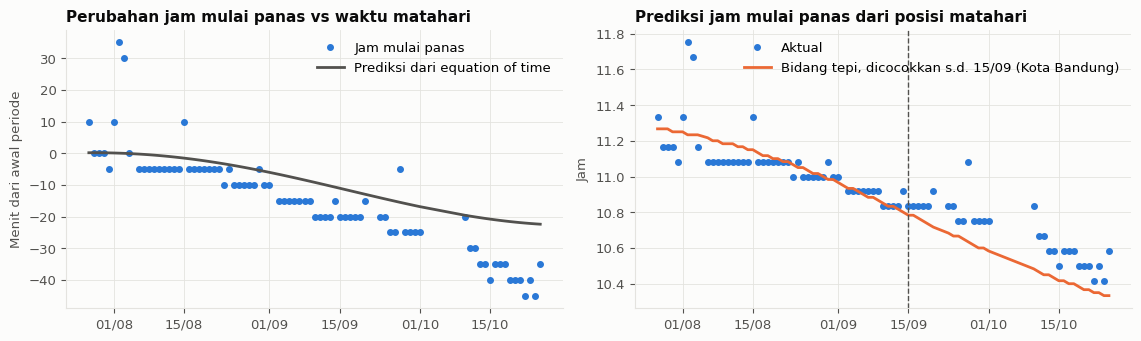

In [41]:
# ===== 20.2 Posisi matahari =====
def posisi_matahari(waktu, lintang, bujur, zona=7):
    w = pd.DatetimeIndex(waktu); jam_ = w.hour + w.minute / 60
    ga = 2 * np.pi / 365 * (w.dayofyear - 1 + (jam_ - 12) / 24)
    eot = 229.18 * (.000075 + .001868 * np.cos(ga) - .032077 * np.sin(ga) - .014615 * np.cos(2 * ga) - .040849 * np.sin(2 * ga))
    dek = .006918 - .399912 * np.cos(ga) + .070257 * np.sin(ga) - .006758 * np.cos(2 * ga) + .000907 * np.sin(2 * ga) - .002697 * np.cos(3 * ga) + .00148 * np.sin(3 * ga)
    ha_ = np.radians((jam_ * 60 + eot + 4 * bujur - 60 * zona) / 4 - 180)
    la = np.radians(lintang)
    alt = np.arcsin(np.sin(la) * np.sin(dek) + np.cos(la) * np.cos(dek) * np.cos(ha_))
    az = (np.degrees(np.arctan2(np.sin(ha_), np.cos(ha_) * np.sin(la) - np.tan(dek) * np.cos(la))) + 180) % 360
    return pd.DataFrame({'eot_menit': eot, 'deklinasi': np.degrees(dek), 'ketinggian': np.degrees(alt), 'azimuth': az}, index=w)

# Koordinat pusat Kota Bandung. Ganti jika titik sensor yang tepat sudah diketahui.
LOKASI_SENSOR = {'Kota Bandung': (-6.91, 107.61)}

# Apakah jam perangkat sendiri yang bergeser? recorded_at dipakai sebagai pembanding
sehat = selisih_jam[(selisih_jam > -7.1) & (selisih_jam < -6.9)]
bulan_jam = pd.Series(sehat.values, index=ts_rtc[sehat.index]).dropna()
display(bulan_jam.groupby(bulan_jam.index.to_period('M')).median().round(4).rename('median selisih jam').to_frame())

mulai_waktu = pd.DatetimeIndex([d + pd.Timedelta(hours=h) for d, h in jam_mulai.items()])
s0 = posisi_matahari(mulai_waktu, *LOKASI_SENSOR['Kota Bandung'])
menit_mulai = jam_mulai.to_numpy() * 60
stabil = pd.Series(menit_mulai, index=jam_mulai.index)['2026-07-27':]
eot_st = pd.Series(s0.eot_menit.to_numpy(), index=jam_mulai.index).reindex(stabil.index)
dek_st = pd.Series(s0.deklinasi.to_numpy(), index=jam_mulai.index).reindex(stabil.index)
A1 = np.c_[np.ones(len(stabil)), eot_st]; b1 = np.linalg.lstsq(A1, stabil, rcond=None)[0]
A2 = np.c_[np.ones(len(stabil)), dek_st]; b2 = np.linalg.lstsq(A2, stabil, rcond=None)[0]
print(f'Perubahan jam mulai panas (median awal vs akhir): {stabil.iloc[:14].median() - stabil.iloc[-14:].median():.0f} menit')
print(f'Perubahan equation of time pada periode yang sama: {eot_st.iloc[-14:].median() - eot_st.iloc[:14].median():.1f} menit')
print(f'Korelasi jam mulai dengan equation of time: {np.corrcoef(stabil, eot_st)[0, 1]:.3f} | dengan deklinasi: {np.corrcoef(stabil, dek_st)[0, 1]:.3f} | R2 eot {r2_score(stabil, A1 @ b1):.3f} | R2 deklinasi {r2_score(stabil, A2 @ b2):.3f}')

def vektor_matahari(waktu, la, lo):
    p = posisi_matahari(waktu, la, lo); al, az = np.radians(p.ketinggian), np.radians(p.azimuth)
    return np.c_[np.cos(al) * np.sin(az), np.cos(al) * np.cos(az), np.sin(al)]

def tebak_mulai(n_bidang, hari_, la, lo):
    menit_ = np.arange(540, 750); hasil_ = []
    for d in hari_:
        hasil_.append(menit_[np.abs(vektor_matahari(d + pd.to_timedelta(menit_, 'min'), la, lo) @ n_bidang).argmin()])
    return np.array(hasil_, float)

latih_s, uji_s = stabil[:'2026-09-15'], stabil['2026-10-09':]
tren = np.polyfit(latih_s.index.dayofyear, latih_s, 1)
baris_sun = []
for nama, (la, lo) in LOKASI_SENSOR.items():
    v = vektor_matahari(pd.DatetimeIndex([d + pd.Timedelta(minutes=m) for d, m in latih_s.items()]), la, lo)
    n_bidang = np.linalg.svd(v, full_matrices=False)[2][-1]
    terbit_prediksi = []
    for d in stabil.index:
        m_ = np.arange(300, 480); terbit_prediksi.append(m_[np.abs(posisi_matahari(d + pd.to_timedelta(m_, 'min'), la, lo).ketinggian.to_numpy()).argmin()])
    terbit_prediksi = np.array(terbit_prediksi, float)
    p_ = posisi_matahari(pd.DatetimeIndex([d + pd.Timedelta(minutes=m) for d, m in stabil.items()]), la, lo)
    baris_sun.append({'lokasi': nama, 'MAE_bidang_train_menit': np.abs(tebak_mulai(n_bidang, latih_s.index, la, lo) - latih_s).mean(), 'MAE_bidang_Oktober_menit': np.abs(tebak_mulai(n_bidang, uji_s.index, la, lo) - uji_s).mean(),
                      'ketinggian_Agustus': p_.ketinggian[:14].median(), 'ketinggian_Oktober': p_.ketinggian[-14:].median(), 'azimuth_Agustus': p_.azimuth[:14].median(), 'azimuth_Oktober': p_.azimuth[-14:].median(),
                      'geser_terbit_menit': np.median(terbit_prediksi[:14]) - np.median(terbit_prediksi[-14:])})
tabel_sun = pd.DataFrame(baris_sun).set_index('lokasi')
display(tabel_sun.round(1))
mae_const = np.abs(latih_s.median() - uji_s).mean(); mae_tren = np.abs(np.polyval(tren, uji_s.index.dayofyear) - uji_s).mean()
print(f'Pembanding pada Oktober: jam tetap dari train {mae_const:.1f} menit | tren garis lurus dari train {mae_tren:.1f} menit')

# Bukti langsung: apakah lonjakan cahaya mendahului suhu menyentuh 35 °C?
LUX_LONJAK = 3000
pagi_lux = data.between_time('09:00', '13:00')
tinggi = pagi_lux[pagi_lux.lux >= LUX_LONJAK]
jam_lonjak = tinggi.groupby(tinggi.index.normalize()).apply(lambda b: (b.index[0] - b.index[0].normalize()).total_seconds() / 60)
pasangan = pd.DataFrame({'lux': jam_lonjak, 'panas': stabil}).dropna()
beda_menit = pasangan.panas - pasangan.lux
print(f'Hari dengan lonjakan lux >= {LUX_LONJAK}: {len(pasangan)} dari {len(stabil)} | median suhu 35 °C tercapai {beda_menit.median():.0f} menit setelah lonjakan cahaya | p10-p90 {beda_menit.quantile(.1):.0f} s.d. {beda_menit.quantile(.9):.0f} menit | korelasi jam {pasangan.lux.corr(pasangan.panas):.3f}')
print(f'Suhu 5 menit sebelum lonjakan: median {np.median([g.temp.asof(d + pd.Timedelta(minutes=m - 5)) for d, m in pasangan.lux.items()]):.1f} °C')
lat_lux = pasangan.lux[:'2026-09-15']; uji_lux = pasangan.lux['2026-10-09':]
vl = vektor_matahari(pd.DatetimeIndex([d + pd.Timedelta(minutes=m) for d, m in lat_lux.items()]), *LOKASI_SENSOR['Kota Bandung'])
n_lux = np.linalg.svd(vl, full_matrices=False)[2][-1]
tren_lux = np.polyfit(lat_lux.index.dayofyear, lat_lux, 1)
print(f'Memakai jam lonjakan cahaya, MAE Oktober: bidang {np.abs(tebak_mulai(n_lux, uji_lux.index, *LOKASI_SENSOR["Kota Bandung"]) - uji_lux).mean():.1f} menit | tren garis lurus {np.abs(np.polyval(tren_lux, uji_lux.index.dayofyear) - uji_lux).mean():.1f} | jam tetap {np.abs(lat_lux.median() - uji_lux).mean():.1f}')

terang = data[data.lux > 50]
terbit = terang.groupby(terang.index.normalize()).apply(lambda b: b.index[0].hour + b.index[0].minute / 60)
terbit = terbit[terbit.index.isin(stabil.index) & (terbit < 7)]
print(f'Lux > 50 pertama: median awal {terbit.iloc[:14].median():.2f} jam | median akhir {terbit.iloc[-14:].median():.2f} jam | bergeser {(terbit.iloc[:14].median() - terbit.iloc[-14:].median()) * 60:.0f} menit')

# Waktu matahari di Bandung dibandingkan dengan cahaya yang terukur
la_s, lo_s = LOKASI_SENSOR['Kota Bandung']
menit_hari = np.arange(240, 1200)
baris_w = []
for tgl in ('2026-08-15', '2026-09-15', '2026-10-15'):
    d = pd.Timestamp(tgl)
    tinggi_ = posisi_matahari(d + pd.to_timedelta(menit_hari, 'min'), la_s, lo_s).ketinggian.to_numpy()
    naik = menit_hari[tinggi_ > -.83]
    sekitar = data.loc[d - pd.Timedelta(days=7):d + pd.Timedelta(days=7)]
    sekitar = sekitar[sekitar.lux > 50]
    awal_l = sekitar.groupby(sekitar.index.normalize()).apply(lambda b: b.index[0].hour * 60 + b.index[0].minute).median()
    akhir_l = sekitar.groupby(sekitar.index.normalize()).apply(lambda b: b.index[-1].hour * 60 + b.index[-1].minute).median()
    jam_ = lambda m: f'{int(m // 60):02d}:{int(m % 60):02d}'
    baris_w.append({'tanggal': tgl, 'terbit': jam_(naik[0]), 'lux>50 pertama': jam_(awal_l), 'terbenam': jam_(naik[-1]), 'lux>50 terakhir': jam_(akhir_l), 'tengah hari matahari': jam_(menit_hari[tinggi_.argmax()]), 'ketinggian maks': round(float(tinggi_.max()), 1)})
display(pd.DataFrame(baris_w).set_index('tanggal'))

arah = posisi_matahari(pd.DatetimeIndex([d + pd.Timedelta(minutes=m) for d, m in stabil.items()]), la_s, lo_s)
arah['jam_mulai'] = stabil.to_numpy() / 60
arah_bulan = arah.groupby(arah.index.to_period('M'))[['jam_mulai', 'ketinggian', 'azimuth']].median()
arah_bulan['jam_mulai'] = arah_bulan['jam_mulai'].map(lambda v: f'{int(v):02d}:{int(round(v % 1 * 60)):02d}')
display(arah_bulan.round(1).rename_axis('bulan'))

# Perbandingan dengan iklim Bandung. Normal menurut pernyataan BMKG: maksimum sekitar 29 °C, minimum sekitar 20 °C
NORMAL_MAKS, NORMAL_MIN = 29., 20.
harian_t = g.temp.resample('1D').agg(['max', 'min', 'count']); harian_t = harian_t[harian_t['count'] >= 250]
print(f"Maksimum harian sensor: median {harian_t['max'].median():.1f} °C (p10-p90 {harian_t['max'].quantile(.1):.1f}-{harian_t['max'].quantile(.9):.1f}) | normal sekitar {NORMAL_MAKS:.0f} °C | selisih {harian_t['max'].median() - NORMAL_MAKS:+.1f} °C")
print(f"Minimum harian sensor : median {harian_t['min'].median():.1f} °C | normal sekitar {NORMAL_MIN:.0f} °C | selisih {harian_t['min'].median() - NORMAL_MIN:+.1f} °C")
print(f"Hari dengan maksimum sensor di atas normal + 3 °C: {(harian_t['max'] >= NORMAL_MAKS + 3).sum()} dari {len(harian_t)} hari")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.5))
ax[0].plot(stabil.index, stabil - stabil.iloc[:14].median(), ls='none', marker='o', ms=4, color=WARNA['temp'], label='Jam mulai panas')
ax[0].plot(eot_st.index, -(eot_st - eot_st.iloc[:14].median()), color=TINTA2, lw=2, label='Prediksi dari equation of time')
ax[0].set_title('Perubahan jam mulai panas vs waktu matahari'); ax[0].set_ylabel('Menit dari awal periode'); ax[0].legend(); ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
lok_terbaik = tabel_sun.MAE_bidang_Oktober_menit.idxmin(); la_b, lo_b = LOKASI_SENSOR[lok_terbaik]
vb = vektor_matahari(pd.DatetimeIndex([d + pd.Timedelta(minutes=m) for d, m in latih_s.items()]), la_b, lo_b)
nb_ = np.linalg.svd(vb, full_matrices=False)[2][-1]
ax[1].plot(stabil.index, stabil / 60, ls='none', marker='o', ms=4, color=WARNA['temp'], label='Aktual')
ax[1].plot(stabil.index, tebak_mulai(nb_, stabil.index, la_b, lo_b) / 60, color=WARNA['hum'], lw=2, label=f'Bidang tepi, dicocokkan s.d. 15/09 ({lok_terbaik})')
ax[1].axvline(pd.Timestamp('2026-09-15'), color=TINTA2, ls='--', lw=1); ax[1].set_title('Prediksi jam mulai panas dari posisi matahari'); ax[1].set_ylabel('Jam'); ax[1].legend(); ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
fig.tight_layout(); plt.show()

**Hasil.** Dugaan sinar matahari langsung kini didukung cukup kuat.

- **Lonjakan cahaya dan suhu terjadi bersamaan.** Pada 79 dari 79 hari, suhu menyentuh 35 °C rata-rata 2 menit setelah `lux` melewati 3.000 (p10-p90: -3 sampai 6 menit, korelasi jam 0,958). Lima menit sebelum lonjakan, suhunya masih sekitar 32,8 °C.
- **Jam perangkat tidak bergeser.** Selisih dengan `recorded_at` stabil sekitar -7,00 jam setiap bulan, jadi perubahan jam mulai panas bukan akibat RTC.
- **Pergeserannya cocok dengan matahari.** Jam mulai panas maju 38 menit. Rumus memprediksi matahari terbit di Bandung maju 35 menit, dan pada data `lux` terukur maju 30 menit.
- **Tepi lurus hanya didukung sebagian.** Uji bidang meleset 9,8 menit pada Oktober (6,5 menit bila memakai jam lonjakan cahaya). Hasil ini jauh lebih baik dari jam tetap (31,2 dan 21,3 menit), tetapi kalah dari garis tren (3,3 dan 1,2 menit).

Uji bidang tidak bergantung pada koordinat, karena mengganti lokasi hanya memutar sistem koordinat. Saat dicoba dengan lima kota, hasilnya memang sama.

**Hasil khusus Bandung.**

- **Jam perangkat cocok dengan matahari Bandung.** `lux` melewati 50 sekitar 20-23 menit setelah matahari terbit pada Agustus sampai Oktober, dan berhenti 17-33 menit sebelum terbenam. Selisih yang stabil ini wajar, karena butuh waktu sampai cahaya cukup terang. Zona waktunya juga cocok dengan WIB.
- **Panas mulai sebelum tengah hari.** Pada Oktober panas mulai pukul 10:35, sekitar 1 jam sebelum tengah hari matahari (11:35).
- **Arah matahari berubah jauh.** Saat panas mulai, matahari berada di utara-timur laut pada Juli-Agustus (azimuth 24-30°, ketinggian 62-66°), lalu di timur pada Oktober (azimuth 99°, ketinggian 75°). Jika ada celah atau tepi yang menentukan, posisinya harus cocok dengan rentang arah ini.

**Perbandingan dengan iklim Bandung.**

| Ukuran | Sensor (median harian) | Normal Bandung (BMKG) | Selisih |
|---|---|---|---|
| Suhu maksimum | 40,7 °C | Sekitar 29 °C | +11,7 °C |
| Suhu minimum | 23,0 °C | Sekitar 20 °C | +3,0 °C |

Maksimum sensor melewati normal + 3 °C pada 79 dari 79 hari. BMKG menyebut suhu 3 °C atau lebih di atas normal setempat sebagai kondisi ekstrem, jadi kejadian setiap hari selama tiga bulan sangat tidak mungkin mewakili udara terbuka Bandung.

Artinya, **angka `temp` kemungkinan besar mewakili kondisi tepat di titik sensor, bukan suhu udara Bandung.** Penyebabnya bisa sinar langsung pada sensor, ruang tertutup seperti rumah tanam, atau gabungan keduanya. Suhu minimum yang juga lebih tinggi menunjukkan kemungkinan ada faktor selain sinar matahari. Angka normal ini berasal dari pernyataan BMKG, bukan data stasiun untuk periode yang sama, jadi selisihnya adalah perkiraan. Karena VPD dihitung dari `temp` dan `hum`, nilainya bisa ikut terlalu tinggi bila sensor terpanaskan.

Garis tren hanya cocok untuk jangka pendek, karena arah gerak matahari akan berbalik. Data ini tidak dapat membedakan apakah sinar mengenai badan sensor atau area di sekitarnya. Pemeriksaan lokasi tetap diperlukan.

### 20.3 Deteksi anomali tanpa label

Detektor di bagian 11 diuji dengan kerusakan buatan. Di sini **Isolation Forest** mencari data tidak wajar pada data asli, tanpa contoh kerusakan. Algoritma ini membelah data secara acak, dan data yang paling cepat terpisah dianggap tidak wajar. Pengujian dilakukan per hari dan per 5 menit.

,skor,pendorong_utama,z,temp_maks,hum_min,hum_malam,jam_mulai
timestamp,,,,,,,
2026-08-02,0.604,jam_mulai,3.4,37.4,40.0,64.0,11.8
2026-10-25,0.592,lux_rata2_log,-3.3,35.2,38.0,63.0,10.6
2026-07-26,0.560,temp_min,-2.7,41.0,13.0,49.0,11.2
2026-08-15,0.559,lux_maks_log,-2.5,37.4,37.0,70.0,11.3
2026-09-27,0.550,hum_malam,2.7,36.9,35.0,89.0,11.1
2026-09-30,0.550,lux_rata2_log,-2.3,36.6,40.0,79.0,10.8
2026-10-22,0.541,jam_mulai,-2.0,43.5,17.0,49.0,10.4


Slot anomali: 120 | episode: 53 | dekat celah data: 3
Jam mulai episode anomali: {10: 26, 11: 16, 12: 3, 13: 2, 14: 2, 15: 3, 16: 1}


,mulai,n,temp_anomali,hum_anomali,lux_anomali,dekat_celah_data
27,2026-09-19 14:05:00,9,-7.91,31.79,-2.62,False
52,2026-10-25 15:45:00,8,-5.84,32.63,-2.56,False
38,2026-09-30 12:55:00,7,-11.59,39.77,-2.75,False
36,2026-09-29 13:05:00,7,-8.34,27.83,-2.69,False
7,2026-08-19 15:35:00,4,-8.37,36.85,-2.17,False
10,2026-08-20 15:25:00,4,-6.85,37.70,-1.82,False
44,2026-10-17 10:35:00,4,5.94,-14.00,1.79,False
41,2026-10-14 10:40:00,3,6.64,-11.15,1.50,False


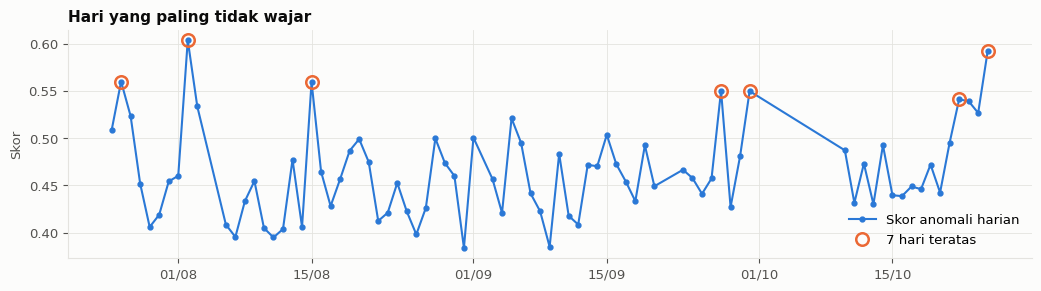

In [42]:
# ===== 20.3 Deteksi anomali tanpa label =====
from sklearn.ensemble import IsolationForest
slot_hari = g.temp.notna().resample('1D').sum()
hari_lengkap = slot_hari[slot_hari >= 250].index
fitur_hari = pd.DataFrame({'temp_maks': g.temp.resample('1D').max(), 'temp_min': g.temp.resample('1D').min(), 'hum_min': g.hum.resample('1D').min(), 'hum_malam': g.hum.between_time('00:00', '05:00').resample('1D').median(),
                           'lux_rata2_log': g.log_lux.resample('1D').mean(), 'lux_maks_log': g.log_lux.resample('1D').max(), 'jam_mulai': jam_mulai}).loc[hari_lengkap]
fitur_hari['jam_mulai'] = fitur_hari['jam_mulai'].fillna(fitur_hari['jam_mulai'].median() + 3)
hutan = IsolationForest(n_estimators=500, contamination=.08, random_state=SEED).fit(fitur_hari)
skor_hari = pd.Series(-hutan.score_samples(fitur_hari), index=fitur_hari.index)
z_hari = (fitur_hari - fitur_hari.median()) / (1.4826 * (fitur_hari - fitur_hari.median()).abs().median())
top_hari = skor_hari.sort_values(ascending=False).head(7)
display(pd.DataFrame({'skor': top_hari.round(3), 'pendorong_utama': [z_hari.loc[d].abs().idxmax() for d in top_hari.index],
                      'z': [round(float(z_hari.loc[d, z_hari.loc[d].abs().idxmax()]), 1) for d in top_hari.index]}).join(fitur_hari[['temp_maks', 'hum_min', 'hum_malam', 'jam_mulai']].round(1)))

baris5 = pd.DataFrame({'temp_anomali': anomali.temp, 'hum_anomali': anomali.hum, 'lux_anomali': anomali.log_lux, 'temp_beda_15m': g.temp.diff(3), 'hum_beda_15m': g.hum.diff(3), 'lux_beda_15m': g.log_lux.diff(3)}).dropna()
hutan5 = IsolationForest(n_estimators=300, contamination=.005, random_state=SEED).fit(baris5)
anom5 = baris5.index[hutan5.predict(baris5) == -1]
kel5 = pd.Series(anom5, index=anom5).diff().gt(pd.Timedelta('60min')).cumsum()
epi5 = baris5.loc[anom5].groupby(kel5.values).agg(n=('temp_anomali', 'size'), temp_anomali=('temp_anomali', 'mean'), hum_anomali=('hum_anomali', 'mean'), lux_anomali=('lux_anomali', 'mean'))
epi5.insert(0, 'mulai', pd.Series(anom5).groupby(kel5.values).min())
sebelum_celah = [bool(g.temp.loc[m - pd.Timedelta(hours=3):m].isna().any()) for m in epi5.mulai]
epi5['dekat_celah_data'] = sebelum_celah
print(f'Slot anomali: {len(anom5)} | episode: {len(epi5)} | dekat celah data: {sum(sebelum_celah)}')
print('Jam mulai episode anomali:', epi5.mulai.dt.hour.value_counts().sort_index().to_dict())
display(epi5.sort_values('n', ascending=False).head(8).round(2))

fig, a = plt.subplots(figsize=(10.5, 3))
a.plot(skor_hari.index, skor_hari, color=WARNA['temp'], lw=1.5, marker='o', ms=3.5, label='Skor anomali harian')
a.plot(top_hari.index, top_hari, ls='none', marker='o', ms=9, mfc='none', mec=WARNA['hum'], mew=1.8, label='7 hari teratas')
a.set_title('Hari yang paling tidak wajar'); a.set_ylabel('Skor'); a.legend(); a.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m')); fig.tight_layout(); plt.show()

**Hasil.** Anomali yang ditemukan lebih banyak berkaitan dengan cuaca dan pergeseran musim, bukan kerusakan alat.

- **Harian:** hari paling tidak wajar antara lain 2 Agustus (panas mulai terlambat), 25 Oktober (paling gelap), dan 27 September (kelembapan malam 89 %RH).
- **Per 5 menit:** ada 120 slot dalam 53 episode. Sebagian besar (42 episode) mulai jam 10-11, yaitu saat pola panas paling mudah bergeser.
- **Episode terpanjang** (seperti 19, 29, dan 30 September) menunjukkan suhu turun 8-12 °C, kelembapan naik 28-40 %RH, dan cahaya turun bersamaan. Karena ketiga sensor bergerak searah secara fisik, penyebab yang paling mungkin adalah awan atau hujan, bukan sensor rusak.
- Episode 14 dan 17 Oktober adalah panas yang datang lebih awal dari pola rata-rata.

Tidak ditemukan pola kerusakan baru selain yang sudah diketahui, sehingga metode ini lebih tepat untuk menemukan kejadian menarik, bukan sebagai alarm kerusakan. Persentase anomali (8% dan 0,5%) adalah pengaturan, bukan hasil pengukuran. Penyebab tiap episode belum bisa dipastikan tanpa catatan cuaca.

### 20.4 Model termal

Model ini memakai rumus sederhana dengan 3 parameter: perubahan suhu bergantung pada selisih suhu saat ini dengan suhu setimbang, ditambah pemanasan dari cahaya. **Konstanta waktu** menunjukkan seberapa lambat suhu merespons.

Malam: laju pendinginan 0.108 per jam | konstanta waktu 9.3 jam | suhu setimbang 20.7 °C
Model siang-malam: k = 0.434 per jam | konstanta waktu 2.3 jam | akar lux koefisien 0.1098
R2 laju suhu pada test: 0.111


,MAE,RMSE,R2
"Fisika, lux masa depan diketahui",0.974,1.598,0.907
"Fisika, lux dianggap tetap",1.156,2.035,0.849
Nilai tetap,1.474,2.286,0.809
Gradient boosting (bagian 9),0.974,1.511,0.917


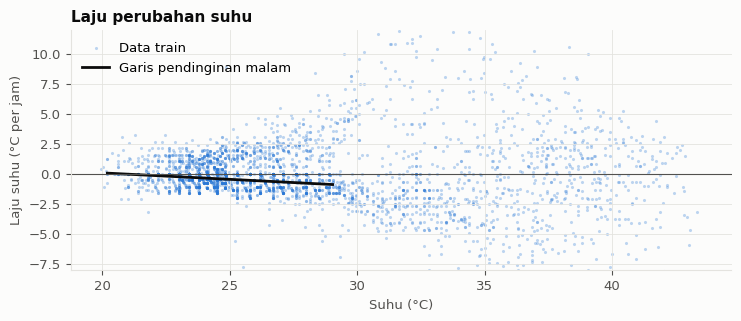

In [43]:
# ===== 20.4 Model termal =====
langkah_t = 3   # 15 menit, supaya resolusi sensor 0,1 °C tidak mendominasi
t_hal = g.temp.rolling(3, center=True, min_periods=2).mean()
dT = (t_hal.shift(-langkah_t) - t_hal) / (langkah_t * 5 / 60)   # °C per jam
tabel_termal = pd.DataFrame({'dT': dT, 'T': t_hal, 'lux_akar': np.sqrt(g.lux), 'jam': g.index.hour}).dropna()
latih_t = tabel_termal[tabel_termal.index < AKHIR_VAL]; uji_t = tabel_termal[tabel_termal.index >= AWAL_TEST]

malam = latih_t[(latih_t.jam >= 19) | (latih_t.jam < 5)]
Am = np.c_[np.ones(len(malam)), malam['T']]; bm = np.linalg.lstsq(Am, malam.dT, rcond=None)[0]
k_malam = -bm[1]; T_setimbang = bm[0] / k_malam
print(f'Malam: laju pendinginan {k_malam:.3f} per jam | konstanta waktu {1 / k_malam:.1f} jam | suhu setimbang {T_setimbang:.1f} °C')

Aa = np.c_[np.ones(len(latih_t)), latih_t['T'], latih_t.lux_akar]; ba = np.linalg.lstsq(Aa, latih_t.dT, rcond=None)[0]
Au = np.c_[np.ones(len(uji_t)), uji_t['T'], uji_t.lux_akar]
print(f'Model siang-malam: k = {-ba[1]:.3f} per jam | konstanta waktu {-1 / ba[1]:.1f} jam | akar lux koefisien {ba[2]:.4f}')
print(f'R2 laju suhu pada test: {r2_score(uji_t.dT, Au @ ba):.3f}')

uji_idx = g.index[is_test & g.temp.notna() & g.temp.shift(-12).notna() & g.lux.notna()]
T = g.temp.reindex(uji_idx).to_numpy().copy()
for k in range(12):
    lx = g.lux.shift(-k).reindex(uji_idx).ffill().to_numpy()
    T = T + (ba[0] + ba[1] * T + ba[2] * np.sqrt(lx)) * (5 / 60)
Tp = g.temp.reindex(uji_idx).to_numpy().copy(); lx0 = g.lux.reindex(uji_idx).to_numpy()
for k in range(12): Tp = Tp + (ba[0] + ba[1] * Tp + ba[2] * np.sqrt(lx0)) * (5 / 60)
y_t = g.temp.shift(-12).reindex(uji_idx).to_numpy()
banding_t = pd.DataFrame({'Fisika, lux masa depan diketahui': metrik(y_t, T), 'Fisika, lux dianggap tetap': metrik(y_t, Tp), 'Nilai tetap': metrik(y_t, g.temp.reindex(uji_idx))}).T
banding_t.loc['Gradient boosting (bagian 9)'] = metrik(y_t, model_fc[('temp', '1 jam')].predict(X12.loc[uji_idx]))
display(banding_t.round(3))

fig, a = plt.subplots(figsize=(7.5, 3.3))
sampel_t = latih_t.sample(4000, random_state=SEED)
a.scatter(sampel_t['T'], sampel_t.dT, s=5, color=WARNA['temp'], alpha=.3, lw=0, label='Data train')
xs = np.array([malam['T'].min(), malam['T'].max()]); a.plot(xs, bm[0] + bm[1] * xs, color=TINTA, lw=2, label='Garis pendinginan malam')
a.axhline(0, color=TINTA2, lw=.8); a.set_ylim(-8, 12); a.set_xlabel('Suhu (°C)'); a.set_ylabel('Laju suhu (°C per jam)'); a.set_title('Laju perubahan suhu'); a.legend(); fig.tight_layout(); plt.show()

**Hasil.**

- **Malam hari:** konstanta waktu sekitar 9,3 jam, dengan suhu setimbang 20,7 °C. Lokasi mendingin perlahan.
- **Seluruh hari:** konstanta waktu sekitar 2,3 jam. Perbedaan besar ini menunjukkan satu rumus linear hanya pendekatan kasar.
- **Laju sesaat sulit ditebak:** R² pada test hanya 0,111, karena awan dan sinar langsung membuat suhu berubah tiba-tiba.

| Prediksi 1 jam | MAE | Catatan |
|---|---|---|
| Fisika, `lux` masa depan diketahui | 0,97 °C | Tidak adil, karena `lux` masa depan belum diketahui |
| Gradient boosting | 0,97 °C | Tanpa informasi masa depan |
| Fisika, `lux` dianggap tetap | 1,16 °C | Perbandingan adil, hanya 3 parameter |
| Nilai tetap | 1,47 °C | Baseline |

Rumus 3 parameter sudah mengalahkan baseline dan mudah dijelaskan, tetapi gradient boosting tetap lebih akurat pada perbandingan yang adil. Kalau `lux` bisa diprediksi dengan baik, model fisika menjadi pilihan menarik.

### 20.5 Pengelompokan tipe hari

**K-means** mengelompokkan hari yang profil 24 jamnya mirip. **Silhouette** mengukur seberapa jelas pemisahan kelompok: mendekati 1 berarti jelas, mendekati 0 berarti kelompok tumpang tindih.

Silhouette: {2: 0.198, 3: 0.199, 4: 0.194, 5: 0.178, 6: 0.184}


,jumlah_hari,temp_maks,temp_min,hum_min,hum_malam,lux_rata2_log
tipe,,,,,,
0,16,41.83,21.02,19.69,56.06,3.56
1,51,40.83,22.98,27.10,65.57,3.51
2,12,38.76,23.31,33.42,76.33,3.30


Tipe per bulan:


tipe,0,1,2
bulan,,,
2026-07,4,3,0
2026-08,5,21,3
2026-09,7,14,6
2026-10,0,13,3


,MAE_temp_1j,MAE_hum_1j,slot
tipe,,,
1.0,1.03,2.49,3638
2.0,0.90,2.82,864


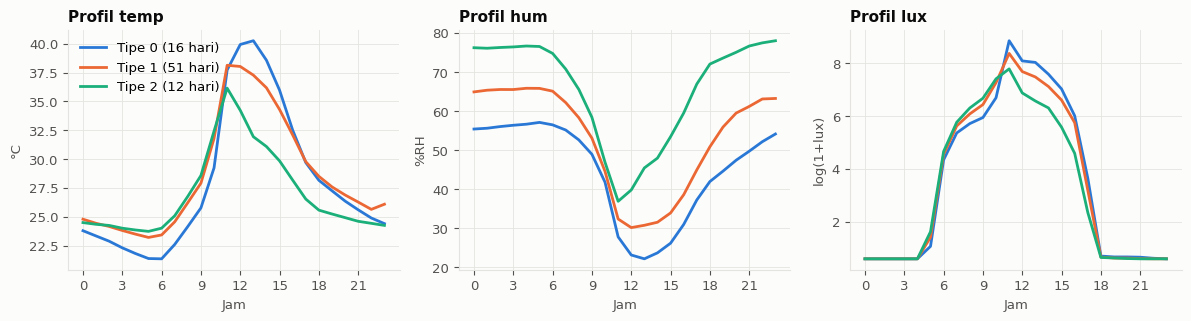

In [44]:
# ===== 20.5 Pengelompokan tipe hari =====
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
per_jam = g[['temp', 'hum', 'log_lux']].groupby([g.index.normalize(), g.index.hour]).mean().unstack()
per_jam = per_jam.loc[per_jam.index.isin(hari_lengkap)].interpolate(axis=1, limit_direction='both').dropna()
Zh = (per_jam - per_jam.mean()) / per_jam.std()
siluet = {k: silhouette_score(Zh, KMeans(k, n_init=20, random_state=SEED).fit_predict(Zh)) for k in range(2, 7)}
print('Silhouette:', {k: round(v, 3) for k, v in siluet.items()})
K = max(siluet, key=siluet.get)
km = KMeans(K, n_init=50, random_state=SEED).fit(Zh)
tipe = pd.Series(km.labels_, index=per_jam.index, name='tipe')
tipe = tipe.map({lama: baru for baru, lama in enumerate(fitur_hari.loc[tipe.index, 'temp_maks'].groupby(tipe).mean().sort_values(ascending=False).index)})
ringkas_tipe = fitur_hari.loc[tipe.index].groupby(tipe)[['temp_maks', 'temp_min', 'hum_min', 'hum_malam', 'lux_rata2_log']].mean().round(2)
ringkas_tipe.insert(0, 'jumlah_hari', tipe.value_counts().sort_index())
display(ringkas_tipe)
print('Tipe per bulan:'); display(pd.crosstab(pd.Series(tipe.index.to_period('M'), index=tipe.index, name='bulan'), tipe))

r1 = pred_fc[('temp', '1 jam')]; rh = pred_fc[('hum', '1 jam')]
galat_tipe = pd.DataFrame({'temp_abs': (r1.aktual - r1.prediksi).abs(), 'hum_abs': (rh.aktual - rh.prediksi).abs()})
galat_tipe['tipe'] = galat_tipe.index.normalize().map(tipe)
display(galat_tipe.dropna().groupby('tipe').agg(MAE_temp_1j=('temp_abs', 'mean'), MAE_hum_1j=('hum_abs', 'mean'), slot=('temp_abs', 'size')).round(2))

warna_tipe = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, k, sat in [(ax[0], 'temp', '°C'), (ax[1], 'hum', '%RH'), (ax[2], 'log_lux', 'log(1+lux)')]:
    for t_ in sorted(tipe.unique()):
        a.plot(range(24), per_jam.loc[tipe[tipe == t_].index, k].mean(), color=warna_tipe[t_], lw=2, label=f'Tipe {t_} ({(tipe == t_).sum()} hari)')
    a.set_title(f'Profil {NAMA.get(k, k)}'); a.set_xlabel('Jam'); a.set_ylabel(sat); a.set_xticks(range(0, 24, 3))
ax[0].legend(); fig.tight_layout(); plt.show()

**Hasil.** Silhouette terbaik hanya 0,199, sehingga kelompok ini lemah. Hari-hari di lokasi ini lebih tepat disebut rentang yang bersambung daripada tipe yang benar-benar terpisah. Tiga kelompok tetap berguna sebagai ringkasan:

| Tipe | Jumlah hari | Suhu maksimum | Kelembapan terendah | Kelembapan malam | Sebutan |
|---|---|---|---|---|---|
| 0 | 16 | 41,8 °C | 19,7 %RH | 56,1 %RH | Panas kering |
| 1 | 51 | 40,8 °C | 27,1 %RH | 65,6 %RH | Normal |
| 2 | 12 | 38,8 °C | 33,4 %RH | 76,3 %RH | Lembap, kurang panas |

Pada data test, kesalahan prediksi 1 jam mirip antar-tipe (`temp` 1,03 dan 0,90 °C; `hum` 2,49 dan 2,82 %RH), jadi tipe hari tidak menjelaskan kesalahan model. Tipe 0 tidak muncul pada hari-hari lengkap di Oktober, sehingga performanya belum teruji pada data test.

### 20.6 Change point detection

Metode ini mencari tanggal saat rata-rata data berubah, dengan **binary segmentation**: data dibelah di titik terbaik, lalu dibelah lagi selama perubahannya cukup besar. **Penalti** mengatur kepekaan, jadi dua nilai diuji. `tds` dipakai sebagai uji kebenaran, karena perubahan fasenya sudah diketahui.

,titik_penalti_longgar,titik_penalti_ketat,tanggal,level_tiap_segmen
deret,,,,
temp_maks,3,0,"24/08, 17/09, 14/10",40.3 | 41.7 | 39.1 | 42.0
hum_malam,4,0,"15/08, 28/08, 19/09, 14/10",64.3 | 72.5 | 58.7 | 75.1 | 59.0
lux_rata2_log,1,0,25/09,3.5 | 3.4
jam_mulai,12,12,"30/07, 04/08, 11/08, 16/08, 23/08, 03/09, 10/0...",11.2 | 11.4 | 11.1 | 11.1 | 11.1 | 11.0 | 10.9...
tds (uji kebenaran metode),8,6,"30/07, 06/08, 15/08, 22/08, 27/08, 01/09, 18/0...",9.6 | 11.5 | 0.8 | 5.3 | 3.8 | 2.4 | 3.8 | 7.1...


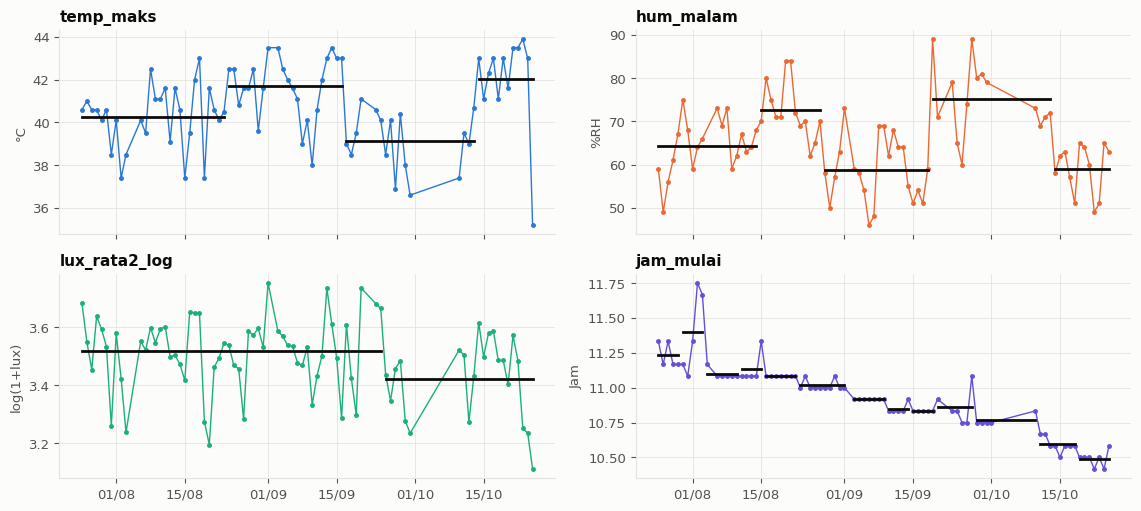

In [45]:
# ===== 20.6 Change point detection =====
def biaya(x): return ((x - x.mean()) ** 2).sum()
def cari_titik(x, penalti, min_seg=5):
    hasil_ = []
    def belah(a, b):
        if b - a < 2 * min_seg: return
        total = biaya(x[a:b]); kandidat = [(biaya(x[a:i]) + biaya(x[i:b]), i) for i in range(a + min_seg, b - min_seg + 1)]
        c, i = min(kandidat)
        if total - c > penalti: hasil_.append(i); belah(a, i); belah(i, b)
    belah(0, len(x)); return sorted(hasil_)

deret = {'temp_maks': g.temp.resample('1D').max(), 'hum_malam': g.hum.between_time('00:00', '05:00').resample('1D').median(), 'lux_rata2_log': g.log_lux.resample('1D').mean(), 'jam_mulai': jam_mulai}
tds_harian = pd.Series(df_clean['tds'].to_numpy(), index=ts_benar).sort_index().resample('1D').mean()
deret['tds (uji kebenaran metode)'] = tds_harian
baris_cp, simpan_cp = [], {}
for nama, s_ in deret.items():
    s_ = s_.loc[s_.index.isin(hari_lengkap) | (nama == 'jam_mulai')].dropna()
    x = s_.to_numpy(float); sig = 1.4826 * np.median(np.abs(np.diff(x))) / np.sqrt(2)
    titik = cari_titik(x, 2 * np.log(len(x)) * sig ** 2)
    titik_ketat = cari_titik(x, 6 * np.log(len(x)) * sig ** 2)
    simpan_cp[nama] = (s_, titik)
    baris_cp.append({'deret': nama, 'titik_penalti_longgar': len(titik), 'titik_penalti_ketat': len(titik_ketat), 'tanggal': ', '.join(f'{s_.index[i]:%d/%m}' for i in titik), 'level_tiap_segmen': ' | '.join(f'{v.mean():.1f}' for v in np.split(x, titik))})
display(pd.DataFrame(baris_cp).set_index('deret'))

fig, ax = plt.subplots(2, 2, figsize=(11.5, 5.2), sharex=True)
for a, (nama, warna_, sat) in zip(ax.ravel(), [('temp_maks', WARNA['temp'], '°C'), ('hum_malam', WARNA['hum'], '%RH'), ('lux_rata2_log', WARNA['lux'], 'log(1+lux)'), ('jam_mulai', '#6250d6', 'Jam')]):
    s_, titik = simpan_cp[nama]; a.plot(s_.index, s_, color=warna_, lw=1, marker='o', ms=2.5)
    for seg in np.split(np.arange(len(s_)), titik): a.plot(s_.index[seg], [s_.iloc[seg].mean()] * len(seg), color=TINTA, lw=2)
    a.set_title(nama); a.set_ylabel(sat); a.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
fig.tight_layout(); plt.show()

**Hasil.** Iklim di lokasi ini tidak punya perubahan rezim yang tegas.

- Dengan penalti ketat, `temp_maks`, `hum_malam`, dan `lux` tidak punya titik perubahan sama sekali. Dengan penalti longgar muncul 3, 4, dan 1 titik. Jadi perubahannya ada, tetapi tidak kuat. Yang paling terlihat adalah periode lebih lembap (level malam 64, 72,5, 58,7, 75,1, lalu 59 %RH).
- `jam_mulai` memiliki 12 titik pada kedua penalti. Itu bukan 12 kejadian, melainkan pergeseran perlahan yang terpotong menjadi anak tangga. Metode ini tidak tepat untuk perubahan bertahap.
- **Uji kebenaran:** metode menemukan titik `tds` pada 6 dan 15 Agustus, dekat dengan fase yang diketahui (3 dan 16 Agustus). Selisih pada 3 Agustus wajar, karena hari-hari sekitar itu datanya tidak lengkap.

### 20.7 Conformal prediction

Bagian 9 menunjukkan interval 90% `temp` hanya mencakup 85-88%. **Conformal prediction** membuat interval dari kesalahan yang sudah terjadi. Lima cara dibandingkan pada prediksi 1 jam. Interval yang baik mencakup sekitar 90% dan tetap sempit.

In [46]:
# ===== 20.7 Conformal prediction =====
def residu_fc(target):
    Xc = buat_fitur(12); yc = g[target].shift(-12)
    ok = yc.notna() & Xc[target].notna() & (g.index >= AKHIR_TRAIN)
    r = (yc[ok] - model_fc[(target, '1 jam')].predict(Xc[ok])).abs()
    return pd.DataFrame({'r': r, 'y': yc[ok]})

baris_cf = []
for target in ('temp', 'hum'):
    rs_ = residu_fc(target)
    uji_c = rs_.index >= AWAL_TEST
    val_c = rs_[rs_.index < AKHIR_VAL]
    panas_jam = (rs_.index.hour >= 9) & (rs_.index.hour < 15)
    q_tetap = pd.Series(val_c.r.quantile(.9), index=rs_.index)
    q_kelas = pd.Series(np.where(panas_jam, val_c.r[panas_jam[:len(val_c)]].quantile(.9), val_c.r[~panas_jam[:len(val_c)]].quantile(.9)), index=rs_.index)
    # r pada waktu t baru diketahui 1 jam kemudian, jadi digeser 12 slot
    q_gulir = rs_.r.rolling('7D', min_periods=200).quantile(.9).shift(12)
    q_gk = pd.concat([rs_.r[m].rolling('7D', min_periods=100).quantile(.9).shift(12) for m in (panas_jam, ~panas_jam)]).sort_index()
    alpha, q_aci, aktif = .1, [], .1
    r_arr = rs_.r.to_numpy(); hist = []
    for i in range(len(r_arr)):
        h_ = r_arr[max(0, i - 2016):max(0, i - 12)]
        lvl = min(max(1 - aktif, .5), .995)
        q = np.quantile(h_, lvl) if len(h_) >= 200 else np.nan
        q_aci.append(q)
        if i >= 12 and not np.isnan(q_aci[i - 12]):
            aktif += .005 * (alpha - float(r_arr[i - 12] > q_aci[i - 12]))
    q_aci = pd.Series(q_aci, index=rs_.index)
    for nama, q in [('Tetap dari validasi', q_tetap), ('Per kelas jam', q_kelas), ('Bergulir 7 hari', q_gulir), ('Bergulir + kelas jam', q_gk), ('Adaptif (ACI)', q_aci)]:
        q_u = q[uji_c]; r_u = rs_.r[uji_c]
        ok = q_u.notna()
        baris_cf.append({'target': target, 'metode': nama, 'cakupan_%': (r_u[ok] <= q_u[ok]).mean() * 100, 'lebar_rata2_±': q_u[ok].mean(), 'cakupan_jam_9-15_%': (r_u[ok & panas_jam[uji_c]] <= q_u[ok & panas_jam[uji_c]]).mean() * 100})
display(pd.DataFrame(baris_cf).set_index(['target', 'metode']).round(2))

cakupan_%  lebar_rata2_±  cakupan_jam_9-15_%
target metode                                                            
temp   Tetap dari validasi       85.46           2.18               48.12
       Per kelas jam             85.54           1.71               88.15
       Bergulir 7 hari           89.47           2.71               60.15
       Bergulir + kelas jam      87.57           1.80               86.67
       Adaptif (ACI)             90.55           2.98               63.32
hum    Tetap dari validasi       92.33           6.36               85.29
       Per kelas jam             94.48           7.09               98.28
       Bergulir 7 hari           88.60           5.37               78.57
       Bergulir + kelas jam      88.02           5.00               88.18
       Adaptif (ACI)             89.78           6.29               80.07

**Hasil. Temuan terpenting adalah cakupan total bisa menipu.**

| `temp`, 1 jam | Cakupan total | Cakupan jam 9-15 | Lebar rata-rata |
|---|---|---|---|
| Tetap dari validasi | 85,5% | 48,1% | ±2,18 °C |
| Per kelas jam | 85,5% | 88,2% | ±1,71 °C |
| Bergulir + kelas jam | 87,6% | 86,7% | ±1,80 °C |
| Adaptif (ACI) | 90,6% | 63,3% | ±2,98 °C |

Interval lama terlihat hanya sedikit kurang (85,5%), padahal pada jam panas hanya mencakup 48,1%. Metode ACI mencapai target total, tetapi jam panasnya tetap lemah dan intervalnya paling lebar.

**Rekomendasi:** pakai interval **per kelas jam**, atau **bergulir + kelas jam** bila model berjalan terus-menerus. Keduanya lebih merata dan lebih sempit dari interval lama. Untuk `hum`, bergulir + kelas jam memberi cakupan 88,0% dengan lebar ±5,00 %RH, lebih sempit dari interval lama (±6,36 %RH). Belum ada satu metode yang tepat mencapai 90% di semua kondisi.

### 20.8 Keandalan alat

**MTBF** adalah rata-rata waktu alat berjalan di antara dua gangguan. **MTTR** adalah rata-rata lama gangguan. "Berhenti mencatat" berarti tidak ada baris data selama lebih dari 10 menit.

In [47]:
# ===== 20.8 Keandalan alat =====
semua_ts = pd.to_datetime(df.tanggal + ' ' + df.waktu, format='%d/%m/%Y %H:%M:%S', errors='coerce')
server_ts = pd.to_datetime(df.recorded_at)
semua_ts = semua_ts.where(~((server_ts - semua_ts).dt.total_seconds() > 0), server_ts + pd.Timedelta(hours=7)).dropna().sort_values()
jeda = semua_ts.diff()
mati = pd.DataFrame({'mulai': semua_ts.shift()[jeda > pd.Timedelta('10min')], 'jam': jeda[jeda > pd.Timedelta('10min')].dt.total_seconds() / 3600}).sort_values('mulai').reset_index(drop=True)
nol = (df.temp == 0) & (df.hum == 0)
blok_nol = (nol != nol.shift()).cumsum()
ep_nol = nol[nol].groupby(blok_nol[nol]).size()
total_jam = (semua_ts.max() - semua_ts.min()).total_seconds() / 3600
jam_hidup = total_jam - mati.jam.sum()
display(mati.round(2))
rangkum = pd.Series({'Rentang pemantauan (jam)': total_jam, 'Jumlah perangkat berhenti mencatat (> 10 menit)': len(mati), 'Total jam tanpa data': mati.jam.sum(), 'Ketersediaan perangkat (%)': jam_hidup / total_jam * 100,
                     'MTBF perangkat (jam)': jam_hidup / max(len(mati), 1), 'MTTR perangkat (jam)': mati.jam.mean(), 'Median lama mati (jam)': mati.jam.median(),
                     'Episode sensor suhu-kelembapan nol': len(ep_nol), 'Ketersediaan sensor suhu-kelembapan (%)': (1 - nol.mean()) * jam_hidup / total_jam * 100})
display(rangkum.round(2).to_frame('nilai'))
print('Jam mulai berhenti mencatat:', mati.mulai.dt.hour.value_counts().sort_index().to_dict())

,mulai,jam
0,2026-08-03 10:05:45,0.18
1,2026-08-03 10:28:46,0.28
2,2026-08-03 10:56:50,0.18
3,2026-08-03 11:07:44,0.58
4,2026-08-03 14:21:52,0.72
5,2026-08-04 13:16:32,0.23
6,2026-08-04 13:30:09,25.04
7,2026-09-01 22:25:31,14.82
8,2026-09-20 22:44:07,35.29
9,2026-09-22 10:06:53,0.28


,nilai
Rentang pemantauan (jam),2274.34
Jumlah perangkat berhenti mencatat (> 10 menit),12.00
Total jam tanpa data,261.28
Ketersediaan perangkat (%),88.51
MTBF perangkat (jam),167.75
MTTR perangkat (jam),21.77
Median lama mati (jam),0.65
Episode sensor suhu-kelembapan nol,5.00
Ketersediaan sensor suhu-kelembapan (%),87.37


Jam mulai berhenti mencatat: {10: 4, 11: 1, 12: 1, 13: 3, 14: 1, 22: 2}


**Hasil.** Selama sekitar 95 hari, alat berhenti mencatat 12 kali dengan total 261,3 jam.

| Ukuran | Nilai |
|---|---|
| Ketersediaan perangkat | 88,5% |
| Ketersediaan sensor suhu-kelembapan | 87,4% |
| MTBF | 167,8 jam (sekitar 7 hari) |
| MTTR | 21,8 jam |
| Median lama gangguan | 0,65 jam |

MTTR jauh lebih besar dari median, karena lima gangguan panjang menyumbang sekitar 99% total waktu mati. Dua yang terpanjang masing-masing sekitar 92 jam pada awal Oktober. Jadi mengurangi lama pemulihan lebih berdampak daripada mengurangi jumlah gangguan.

Tujuh gangguan pertama terjadi pada 3-4 Agustus, bersamaan dengan perubahan `calibration_id` dan RTC yang ter-reset. Ini mungkin saat pemeliharaan alat, tetapi perlu dicocokkan dengan catatan lapangan. Jumlah kejadian kecil, jadi MTBF dan MTTR hanya gambaran. Data juga tidak bisa membedakan alat mati dengan koneksi putus.

### 20.9 Forensik kelistrikan

Bagian ini memakai `df` mentah untuk menelusuri urutan kejadian saat relay aktif, termasuk kolom yang sudah dikeluarkan dari model.

baris  persen_nol  tds_rata2  tds_noise  soil1_noise  soil2_noise
relay1 relay2                                                                    
0      0       117334        0.27       4.64       5.16        10.60        11.36
       1           23       52.17      12.39       9.20       105.78         9.36
1      0           46       71.74       8.98      12.07        31.00        23.19
       1         1167       99.74      17.97      10.40         9.97        10.28

Relay pertama nyala 23/07 15:15 | kedua relay nyala 23/07 15:57 | sensor nol pertama 23/07 15:58
Relay terakhir mati 24/07 12:57 | sensor nol terakhir 24/07 12:50


,Relay nyala,Relay mati (kalibrasi 2)
lux,1.7,5.0
tds,16.0,12.0
soil1,629.0,653.0
soil2,639.0,812.0


Baris relay nyala tanpa pembacaan nol: 27 | tanggal: {Timestamp('2026-07-23 00:00:00'): 8, Timestamp('2026-07-24 00:00:00'): 7, Timestamp('2026-08-03 00:00:00'): 12}
Pembacaan nol saat relay mati: 317 | tanggal: {Timestamp('2026-07-23 00:00:00'): 16, Timestamp('2026-08-03 00:00:00'): 1, Timestamp('2026-09-24 00:00:00'): 1, Timestamp('2026-10-05 00:00:00'): 299}


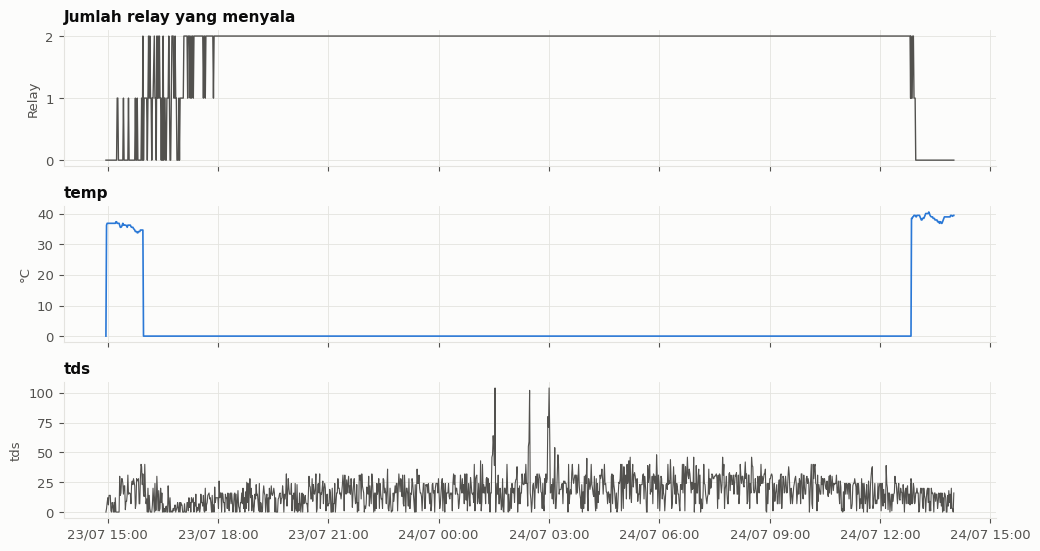

In [48]:
# ===== 20.9 Forensik kelistrikan =====
fr = df.assign(t=pd.to_datetime(df.tanggal + ' ' + df.waktu, format='%d/%m/%Y %H:%M:%S', errors='coerce')).dropna(subset=['t']).sort_values('t').set_index('t')
fr['sensor_nol'] = (fr.temp == 0) & (fr.hum == 0)
display(fr.groupby(['relay1', 'relay2']).agg(baris=('temp', 'size'), persen_nol=('sensor_nol', lambda s: s.mean() * 100), tds_rata2=('tds', 'mean'), tds_noise=('tds', lambda s: s.diff().std() / np.sqrt(2)),
                                             soil1_noise=('soil1', lambda s: s.diff().std() / np.sqrt(2)), soil2_noise=('soil2', lambda s: s.diff().std() / np.sqrt(2))).round(2))
jendela_r = fr.loc['2026-07-23 15:00':'2026-07-24 13:30']
pertama_on = jendela_r.index[(jendela_r.relay1 == 1) | (jendela_r.relay2 == 1)][0]
pertama_nol = jendela_r.index[jendela_r.sensor_nol][0]
dua_on = jendela_r.index[(jendela_r.relay1 == 1) & (jendela_r.relay2 == 1)][0]
print(f'Relay pertama nyala {pertama_on:%d/%m %H:%M} | kedua relay nyala {dua_on:%d/%m %H:%M} | sensor nol pertama {pertama_nol:%d/%m %H:%M}')
on_ = (fr.relay1 == 1) | (fr.relay2 == 1)
akhir_on = fr.index[on_ & ~on_.shift(-1, fill_value=False)]
akhir_nol = fr.index[fr.sensor_nol & ~fr.sensor_nol.shift(-1, fill_value=False)]
blok_r = fr.loc[pertama_on:'2026-07-24 13:30']
print(f'Relay terakhir mati {blok_r.index[(blok_r.relay1 == 1) | (blok_r.relay2 == 1)][-1]:%d/%m %H:%M} | sensor nol terakhir {blok_r.index[blok_r.sensor_nol][-1]:%d/%m %H:%M}')
luar = fr[(fr.calibration_id == 2) & ~on_]
banding_r = pd.DataFrame({'Relay nyala': fr[on_ & (fr.calibration_id == 2)][['lux', 'tds', 'soil1', 'soil2']].median(), 'Relay mati (kalibrasi 2)': luar[['lux', 'tds', 'soil1', 'soil2']].median()})
display(banding_r.round(1))
print('Baris relay nyala tanpa pembacaan nol:', int((on_ & ~fr.sensor_nol).sum()), '| tanggal:', fr[on_ & ~fr.sensor_nol].index.normalize().value_counts().sort_index().to_dict())
print('Pembacaan nol saat relay mati:', int((~on_ & fr.sensor_nol).sum()), '| tanggal:', fr[~on_ & fr.sensor_nol].index.normalize().value_counts().sort_index().to_dict())

bagian_r = fr.loc['2026-07-23 14:30':'2026-07-24 14:00']
fig, ax = plt.subplots(3, 1, figsize=(10.5, 5.6), sharex=True)
ax[0].plot(bagian_r.index, bagian_r.relay1 + bagian_r.relay2, color=TINTA2, lw=1); ax[0].set_title('Jumlah relay yang menyala'); ax[0].set_ylabel('Relay'); ax[0].set_yticks([0, 1, 2])
ax[1].plot(bagian_r.index, bagian_r.temp, color=WARNA['temp'], lw=1.2); ax[1].set_title('temp'); ax[1].set_ylabel('°C')
ax[2].plot(bagian_r.index, bagian_r.tds, color=TINTA2, lw=.8); ax[2].set_title('tds'); ax[2].set_ylabel('tds'); ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M'))
fig.tight_layout(); plt.show()

**Hasil.** Gangguan paling kuat terjadi saat **kedua relay menyala bersamaan**.

| Kondisi relay | Baris | Pembacaan nol | Noise `tds` |
|---|---|---|---|
| Keduanya mati | 117.334 | 0,27% | 5,16 |
| Hanya `relay2` | 23 | 52,2% | 9,20 |
| Hanya `relay1` | 46 | 71,7% | 12,07 |
| Keduanya menyala | 1.167 | 99,7% | 10,40 |

- **Urutan waktunya tepat.** Relay pertama menyala 15:15, tetapi sensor masih terbaca. Kedua relay menyala 15:57, dan sensor mulai nol pada 15:58. Sensor pulih pada 12:50 keesokan harinya, sedangkan relay mati pada 12:57.
- **Tidak semua pembacaan nol berasal dari relay.** Ada 299 pembacaan nol pada 5 Oktober tanpa relay menyala, jadi ada penyebab lain.
- **Relay tidak selalu mengganggu.** Pada 3 Agustus, 12 baris dengan `relay1` menyala tidak memberi pembacaan nol.
- **`tds` terpengaruh relay, `soil` tidak.** Noise `tds` naik sekitar dua kali lipat. Noise `soil` tetap sekitar 10, jadi ketidakstabilan `soil` tidak dijelaskan oleh relay.

Periode relay aktif pada dasarnya hanya satu kejadian panjang, dan perbandingan median `soil` tercampur dengan perbedaan waktu. Jadi ini petunjuk kuat, bukan bukti akhir. Hipotesis yang layak diuji: beban dua relay sekaligus menurunkan tegangan atau mengganggu jalur data sensor.

### 20.10 Model untuk mikrokontroler

`SensorFill` diperkecil dari 128 ke 32 dan 16 neuron, lalu bobotnya disimulasikan dalam 8-bit (int8). Tujuannya melihat apakah prediksi bisa dijalankan langsung di alat tanpa server.

In [49]:
# ===== 20.10 Model untuk mikrokontroler =====
def latih_ringkas(hidden, epoch=60, batch=256, seed=0):
    torch.manual_seed(seed)
    m = SensorFill(hidden=hidden); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-3); jadwal_ = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epoch)
    terbaik_, bobot_, n = np.inf, None, len(x_tr)
    for e in range(epoch):
        m.train(); urutan = torch.randperm(n)
        for i in range(0, n, batch):
            b = urutan[i:i + batch]; mk = MASKER[torch.randint(0, 8, (len(b),))]
            l = loss_masked(m(x_tr[b], mk, t_tr[b]), y_tr[b], mk); opt.zero_grad(); l.backward(); opt.step()
        jadwal_.step(); m.eval()
        with torch.no_grad():
            v = float(np.mean([loss_masked(m(x_va, MASKER[k].repeat(len(x_va), 1), t_va), y_va, MASKER[k].repeat(len(x_va), 1)).item() for k in range(7)]))
        if v < terbaik_: terbaik_, bobot_ = v, {k: w.clone() for k, w in m.state_dict().items()}
    m.load_state_dict(bobot_); return m

def kuantisasi_int8(m):
    q = SensorFill(hidden=m.net[0].out_features); q.load_state_dict(m.state_dict())
    with torch.no_grad():
        for p in q.parameters():
            if p.ndim == 2:
                s_ = p.abs().amax(dim=1, keepdim=True) / 127
                p.copy_(torch.round(p / s_) * s_)
    return q

def nilai_model(m):
    y = y_te.numpy() * SD + MU
    return {'MAE temp (hum+lux)': mean_absolute_error(y[:, 0], prediksi_net(m, x_te, t_te, [0, 1, 1])[:, 0]), 'MAE hum (temp+lux)': mean_absolute_error(y[:, 1], prediksi_net(m, x_te, t_te, [1, 0, 1])[:, 1]),
            'MAE temp (lux)': mean_absolute_error(y[:, 0], prediksi_net(m, x_te, t_te, [0, 0, 1])[:, 0])}

baris_tm = []
for label, m in [('128 neuron (bagian 8)', net), ('32 neuron', latih_ringkas(32)), ('16 neuron', latih_ringkas(16))]:
    n_par = sum(p.numel() for p in m.parameters()); kali = sum(p.numel() for p in m.parameters() if p.ndim == 2)
    baris_tm.append({'model': label, 'presisi': 'float32', 'parameter': n_par, 'ukuran_KB': n_par * 4 / 1024, 'perkalian_per_prediksi': kali, **nilai_model(m)})
    baris_tm.append({'model': label, 'presisi': 'int8', 'parameter': n_par, 'ukuran_KB': n_par / 1024, 'perkalian_per_prediksi': kali, **nilai_model(kuantisasi_int8(m))})
display(pd.DataFrame(baris_tm).set_index(['model', 'presisi']).round(3))

uji_seed = []
for h_ in (128, 32):
    for sd_ in (1, 2, 3):
        uji_seed.append({'neuron': h_, 'seed': sd_, **nilai_model(latih_ringkas(h_, seed=sd_))})
uji_seed = pd.DataFrame(uji_seed)
display(uji_seed.groupby('neuron').agg(['mean', 'std']).drop(columns='seed').round(3))

parameter  ukuran_KB  perkalian_per_prediksi  MAE temp (hum+lux)  MAE hum (temp+lux)  MAE temp (lux)
model                 presisi                                                                                                      
128 neuron (bagian 8) float32      38787    151.512                   38400               1.257               6.348           1.525
                      int8         38787     37.878                   38400               1.262               6.351           1.521
32 neuron             float32       3555     13.887                    3456               0.946               6.550           1.470
                      int8          3555      3.472                    3456               0.945               6.514           1.464
16 neuron             float32       1267      4.949                    1216               1.175               6.885           1.580
                      int8          1267      1.237                    1216               1.178               6.911           1.586

MAE temp (hum+lux)        MAE hum (temp+lux)        MAE temp (lux)       
                     mean    std               mean    std           mean    std
neuron                                                                          
32                  1.110  0.029              6.403  0.139          1.519  0.054
128                 1.169  0.133              6.223  0.042          1.522  0.067

**Hasil.** Model bisa diperkecil jauh tanpa kehilangan akurasi yang berarti.

| Model | Ukuran float32 | Ukuran int8 | Perkalian per prediksi |
|---|---|---|---|
| 128 neuron | 151,5 KB | 37,9 KB | 38.400 |
| 32 neuron | 13,9 KB | 3,5 KB | 3.456 |
| 16 neuron | 4,9 KB | 1,2 KB | 1.216 |

Rata-rata tiga seed menunjukkan 32 neuron setara dengan 128 neuron, dengan parameter sekitar 11 kali lebih sedikit:

| MAE | 128 neuron | 32 neuron |
|---|---|---|
| `temp` dari `hum` + `lux` | 1,17 ± 0,13 °C | 1,11 ± 0,03 °C |
| `hum` dari `temp` + `lux` | 6,22 ± 0,04 %RH | 6,40 ± 0,14 %RH |
| `temp` dari `lux` saja | 1,52 ± 0,07 °C | 1,52 ± 0,05 °C |

Skor 0,95 °C pada tabel pertama adalah hasil satu seed yang kebetulan bagus, jadi angka rata-rata lebih tepat dikutip. Pembulatan ke int8 mengubah MAE paling banyak sekitar 0,04, tetapi ini baru simulasi pada bobot. Model 32 neuron kemungkinan muat di banyak mikrokontroler, tetapi kecepatan dan memorinya belum diuji pada perangkat sebenarnya.

## 21. Kesimpulan analisis lanjutan

1. **Prediksi nilai suhu terbukti berguna.** Model menang atas baseline pada 10 dari 10 minggu, dengan MAE 0,81 °C bila dilatih ulang setiap minggu.
2. **Alarm panas bisa memakai aturan sederhana.** Episode pagi tertangkap oleh jadwal adaptif tanpa alarm palsu. Model dengan batas 1 alarm per hari menyamainya, dengan peringatan lebih awal.
3. **Sinar matahari langsung menjadi penjelasan terkuat lonjakan suhu.** Lonjakan cahaya dan suhu terjadi bersamaan pada semua 79 hari. Suhu maksimum sensor juga sekitar 11,7 °C di atas normal Bandung, jadi `temp` kemungkinan mewakili titik sensor, bukan udara kota. Perlu dicek di lokasi.
4. **Gangguan kelistrikan paling kuat saat dua relay menyala bersamaan,** tetapi ada kerusakan lain tanpa relay, dan `soil` tidak dijelaskan oleh relay.
5. **Keandalan alat masih rendah** (ketersediaan 88,5%), terutama karena pemulihan yang lama.
6. **Interval prediksi perlu dibedakan per jam,** karena interval lama hanya mencakup 48,1% pada jam panas.
7. **Model bisa dijalankan dalam ukuran kecil,** dengan model 32 neuron sebesar 3,5 KB secara simulasi.
8. **Pola cuaca harian lebih bersambung daripada terkelompok,** dan belum ada perubahan rezim yang tegas.

## 22. Saran

**Perbaikan alat**

1. Periksa sensor sekitar pukul 10:00-11:00 untuk melihat apakah sinar mengenainya, terutama dari arah timur. Pasang pelindung radiasi, lalu bandingkan dengan termometer rujukan dan data stasiun BMKG Bandung.
2. Uji relay dengan catu daya terpisah, terutama saat kedua relay menyala bersamaan.
3. Perbaiki kabel `soil` dan `tds`, lalu ulangi audit bagian 4.
4. Selidiki penyebab pembacaan nol pada 5 Oktober dan dua gangguan sekitar 92 jam pada awal Oktober.
5. Tambahkan alert otomatis saat data berhenti masuk, supaya gangguan lebih cepat ditangani.

**Penerapan model**

1. Pakai model prediksi dengan pelatihan ulang setiap minggu.
2. Untuk alarm panas, mulai dari jadwal adaptif, atau model dengan batas 1 alarm per hari bila peringatan lebih awal diperlukan.
3. Pakai interval prediksi per kelas jam.
4. Uji model 32 neuron pada perangkat sebenarnya.

**Data yang perlu dikumpulkan untuk analisis berikutnya**

Analisis berikut belum bisa dilakukan dengan data saat ini:

| Analisis yang belum bisa dilakukan | Alasan | Yang perlu dikumpulkan |
|---|---|---|
| Hubungan iklim dengan hasil tanaman | Belum ada data tanaman dan panen | Jenis tanaman, fase tumbuh, dan hasil panen |
| Efisiensi air | Catatan penyiraman tidak ada dan `soil` tidak andal | Catatan penyiraman, debit air, dan sensor `soil` yang sudah diperbaiki |
| Perbandingan antar-lokasi | Data hanya dari satu lokasi | Sensor yang sama di beberapa lokasi |
| Pola tahunan | Data baru sekitar tiga bulan | Pengukuran minimal satu tahun penuh |

Selain itu, simpan titik koordinat sensor yang tepat, jenis tempat pemasangan (terbuka, teduh, atau rumah tanam), catatan pemeliharaan, dan data cuaca Bandung, supaya analisis matahari dan anomali bisa dipastikan.